# Overview

Here we process output files from Sapiens2 model from json format into workable csv

The steps include:
- 

In [1]:
import os
import glob
import pandas as pd
import numpy

curfolder = os.getcwd()

coordfolder = os.path.join(curfolder, 'Sapiens_Output')
vidfolder = os.path.join(curfolder, 'GTST_sampled')
processedfolder = os.path.join(curfolder, 'Sapiens_Processed')

if not os.path.exists(processedfolder):
    os.makedirs(processedfolder)

vidfiles = glob.glob(os.path.join(vidfolder, '*.mp4'))
coordfiles = glob.glob(os.path.join(coordfolder, '*', '*.json'))

In [ ]:
coordsample = coordfiles[0]

# Load in json file
df = pd.read_json(coordsample)
df.head() # Note that it's double-nested

## Process json to csv

In [15]:
import sys, json, csv, glob, os
import numpy as np

sys.path.append(os.path.join(curfolder, 'Sapiens'))
from keypoints308 import dataset_info
_ki = dataset_info["keypoint_info"]
KP_NAMES = [_ki[i]["name"] for i in range(len(_ki))]
IDX = {KP_NAMES[i]: i for i in range(len(KP_NAMES))}

CONF_THR = 0.6

def unwrap(d):
    fps, video = d.get("fps"), d.get("video")
    node = d["frames"]; pred = None
    if isinstance(node, dict):
        pred = node[next(iter(node))]; video = video or pred.get("video"); node = pred
    if isinstance(node, dict):
        node = node["frames"]
    return node, fps, video, pred

def person_center(inst):
    kp = np.array(inst["keypoints"], float)
    sc = np.array(inst["keypoint_scores"], float)
    good = sc >= CONF_THR
    if good.sum() == 0:
        x1, y1, x2, y2 = inst["bbox"]
        return np.array([(x1 + x2) / 2, (y1 + y2) / 2])
    return kp[good].mean(axis=0)

def person_trunk_size(inst):
    """Shoulder->hip height; falls back to shoulder width if hips aren't confident."""
    kp = np.array(inst["keypoints"], float)
    sc = np.array(inst["keypoint_scores"], float)
    good = sc >= CONF_THR
    def pt(name):
        i = IDX[name]; return kp[i] if good[i] else None
    ls, rs = pt("left_shoulder"), pt("right_shoulder")
    lh, rh = pt("left_hip"), pt("right_hip")
    if ls is not None and rs is not None and lh is not None and rh is not None:
        return np.linalg.norm((lh + rh) / 2 - (ls + rs) / 2)   # trunk height
    if ls is not None and rs is not None:
        return np.linalg.norm(ls - rs)                          # fallback: shoulder width
    return 0.0

def person_score(inst, cx, cy):
    """Lower = more central AND larger (nearer). inf if no usable trunk."""
    c = person_center(inst)
    dist = np.hypot(c[0] - cx, c[1] - cy)
    trunk = person_trunk_size(inst)
    if trunk <= 0:
        return np.inf
    return dist / trunk

def order_by_center_and_trunk(instances, cx, cy):
    return sorted(instances, key=lambda i: person_score(i, cx, cy))

def json_to_wide_csv(json_path, csv_path):
    with open(json_path) as f:
        d = json.load(f)
    frames, fps, video, pred = unwrap(d)

    H, W = pred["image_size"]
    cx, cy = W / 2, H / 2

    n_persons = max((len(fr["instances"]) for fr in frames), default=1)
    header = ["video", "frame", "time_s"]
    for p in range(1, n_persons + 1):
        for nm in KP_NAMES:
            header += [f"p{p}_{nm}_x", f"p{p}_{nm}_y", f"p{p}_{nm}_conf"]

    with open(csv_path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(header)
        for fr in frames:
            idx = int(os.path.splitext(fr["image_name"])[0])
            row = {"video": video, "frame": idx, "time_s": idx / fps if fps else ""}
            insts = order_by_center_and_trunk(fr["instances"], cx, cy)
            for p, inst in enumerate(insts, 1):
                for nm, (x, y), s in zip(KP_NAMES, inst["keypoints"], inst["keypoint_scores"]):
                    row[f"p{p}_{nm}_x"] = x
                    row[f"p{p}_{nm}_y"] = y
                    row[f"p{p}_{nm}_conf"] = s
            w.writerow([row.get(c, "") for c in header])
    return n_persons

json_err = []
for jp in coordfiles:
    print(jp)
    try:
        n = json_to_wide_csv(jp, jp[:-5] + ".csv")
        print(f"wrote {os.path.basename(jp)[:-5]}.csv  ({n} person(s))")
    except Exception as e:
        json_err.append((jp, e))

c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ANSTECKEN\GP01_ANSTECKEN_pose.json
wrote GP01_ANSTECKEN_pose.csv  (1 person(s))
c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BODEN\GP01_BODEN_pose.json
wrote GP01_BODEN_pose.csv  (1 person(s))
c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BRIEF\GP01_BRIEF_pose.json
wrote GP01_BRIEF_pose.csv  (1 person(s))
c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BUERO\GP01_BUERO_pose.json
wrote GP01_BUERO_pose.csv  (1 person(s))
c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ENTSCHULDIGEN\GP01_ENTSCHULDIGEN_pose.json
wrote GP01_ENTSCHULDIGEN_pose.csv  (1 person(s))
c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_GIRAFFE\GP01_GIRAFFE_pose.json
wrote GP01_GIRAFFE_pose.csv  (1 person(s))
c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_GOTT

In [9]:
json_err

[('c:\\Users\\kadava\\Documents\\Github\\GtST_FLESH_KinTrajectory\\Sapiens_Output\\IP10_01_ZERREIẞEN\\IP10_01_ZERREIẞEN_pose.json',
  TypeError('cannot unpack non-iterable NoneType object')),
 ('c:\\Users\\kadava\\Documents\\Github\\GtST_FLESH_KinTrajectory\\Sapiens_Output\\IP10_02_ZERREIẞEN\\IP10_02_ZERREIẞEN_pose.json',
  TypeError('cannot unpack non-iterable NoneType object')),
 ('c:\\Users\\kadava\\Documents\\Github\\GtST_FLESH_KinTrajectory\\Sapiens_Output\\IP11_01_ZERREIẞEN\\IP11_01_ZERREIẞEN_pose.json',
  TypeError('cannot unpack non-iterable NoneType object')),
 ('c:\\Users\\kadava\\Documents\\Github\\GtST_FLESH_KinTrajectory\\Sapiens_Output\\IP14_01_ZERREIẞEN\\IP14_01_ZERREIẞEN_pose.json',
  TypeError('cannot unpack non-iterable NoneType object')),
 ('c:\\Users\\kadava\\Documents\\Github\\GtST_FLESH_KinTrajectory\\Sapiens_Output\\IP14_02_ZERREIẞEN\\IP14_02_ZERREIẞEN_pose.json',
  TypeError('cannot unpack non-iterable NoneType object')),
 ('c:\\Users\\kadava\\Documents\\Github\

<Axes: xlabel='frame'>

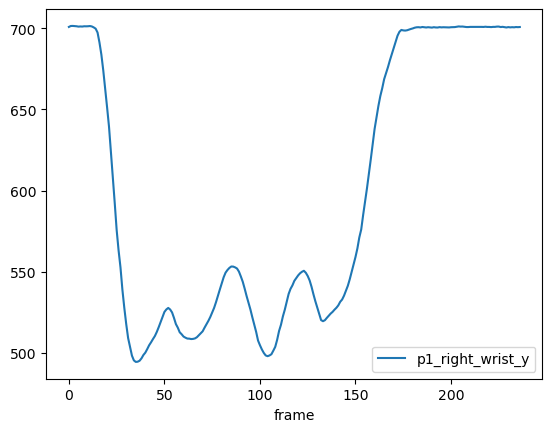

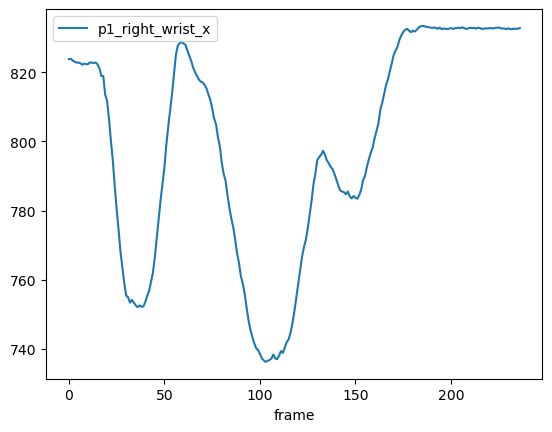

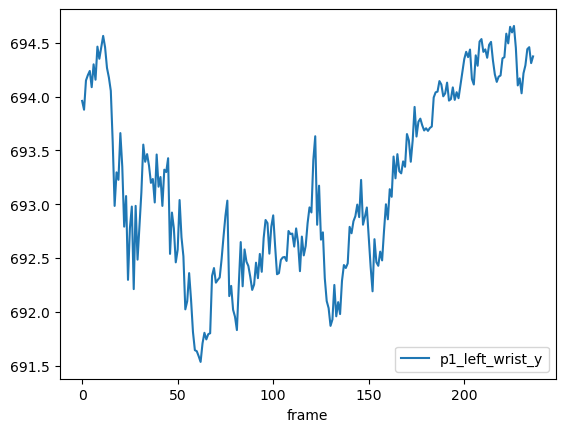

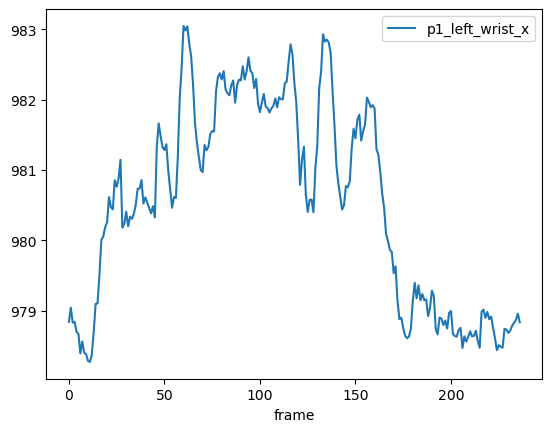

In [30]:
csvfiles = glob.glob(os.path.join(curfolder, 'Sapiens_Output', '*', '*GP01_ANSTECKEN_pose.csv'))
sample_df = pd.read_csv(csvfiles[0])

# plot p1_right_wrist_y
sample_df.plot(x='frame', y='p1_right_wrist_y') # should move once up and once down - notice it's FLIPPED
sample_df.plot(x='frame', y='p1_right_wrist_x') # should slightly move left and right
sample_df.plot(x='frame', y='p1_left_wrist_y') # should not move
sample_df.plot(x='frame', y='p1_left_wrist_x') # should not move




## Check people association (in multi-party frames)

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\IP04_01_HAENDE\IP04_01_HAENDE_pose.csv
  showing frame 0


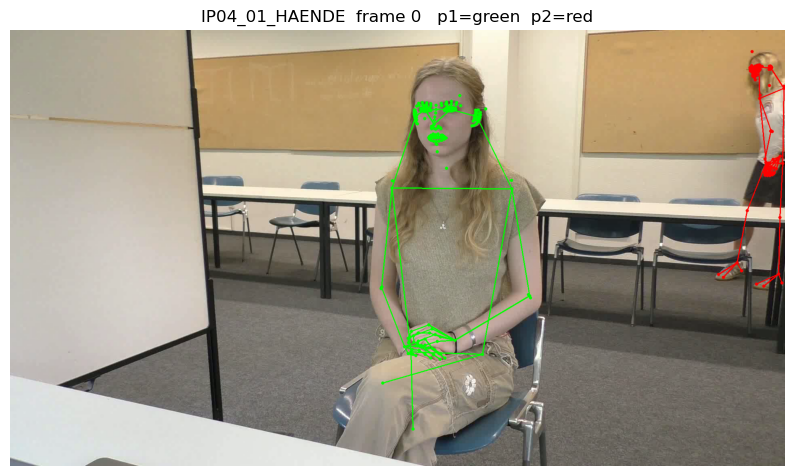

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\IP11_01_GEBURT\IP11_01_GEBURT_pose.csv
  showing frame 72


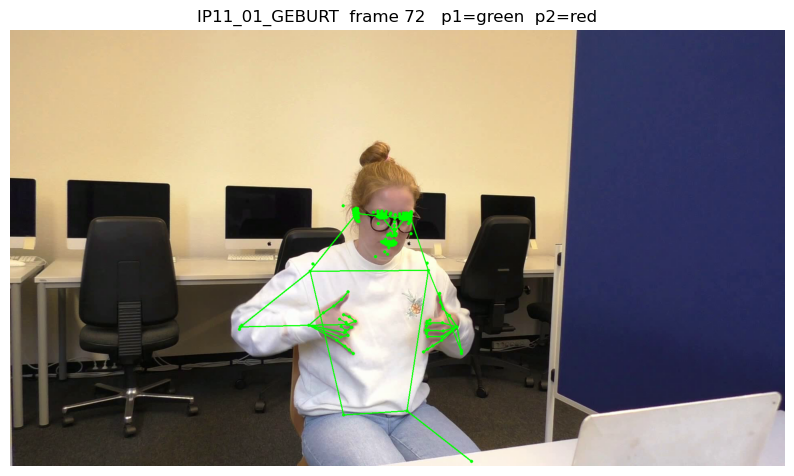

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\IP11_01_TRETEN\IP11_01_TRETEN_pose.csv
  showing frame 0


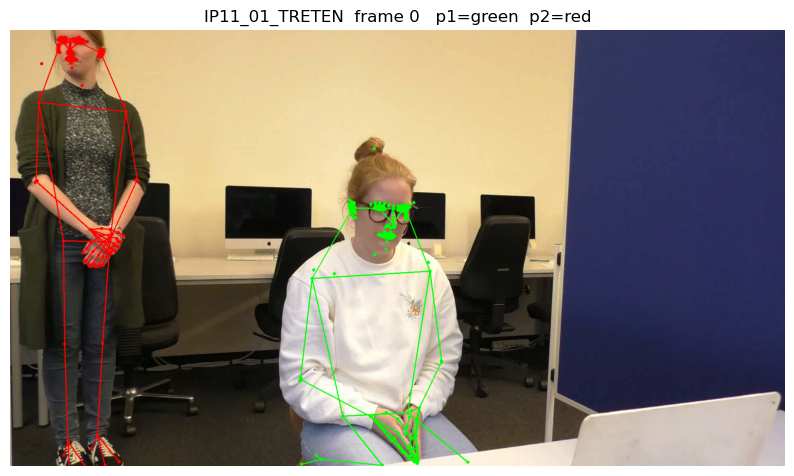

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\IP11_02_VOGEL\IP11_02_VOGEL_pose.csv
  showing frame 102


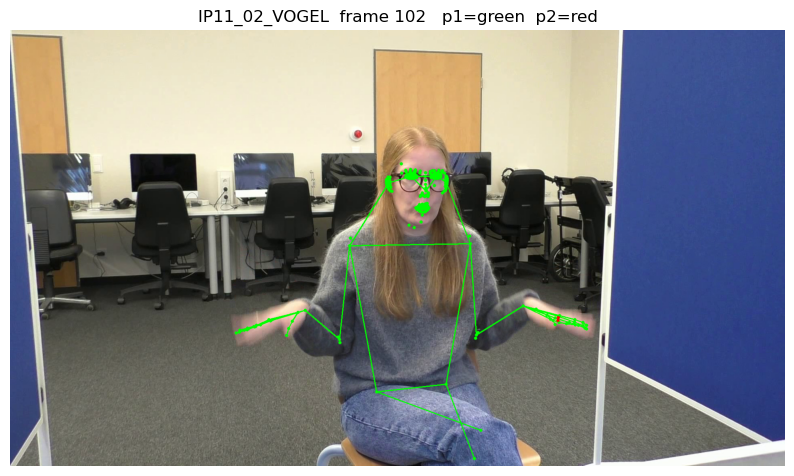

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\IP16_01_BRECHEN\IP16_01_BRECHEN_pose.csv
  showing frame 102


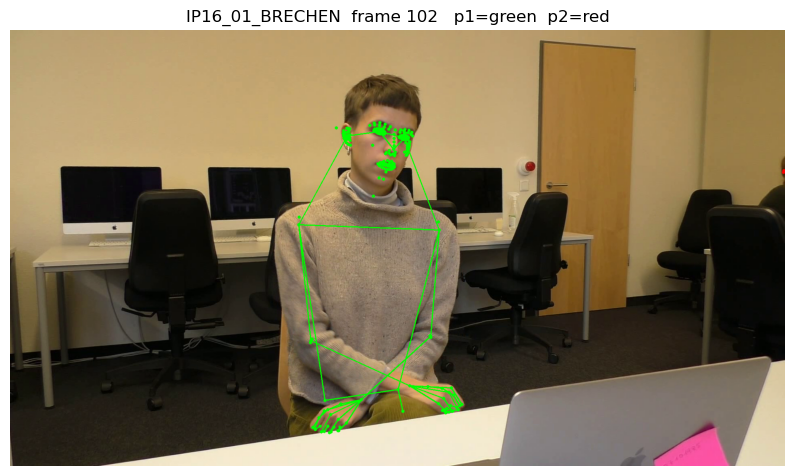

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\IP16_01_ZEIT\IP16_01_ZEIT_pose.csv
  showing frame 0


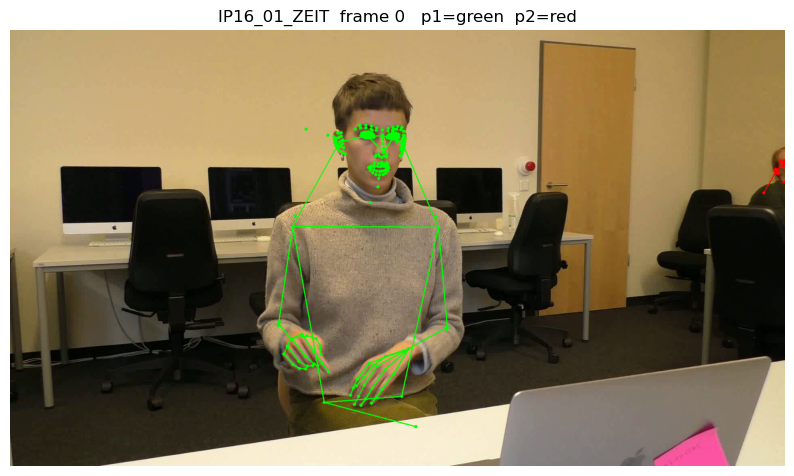

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\IP16_02_HUT\IP16_02_HUT_pose.csv
  showing frame 40


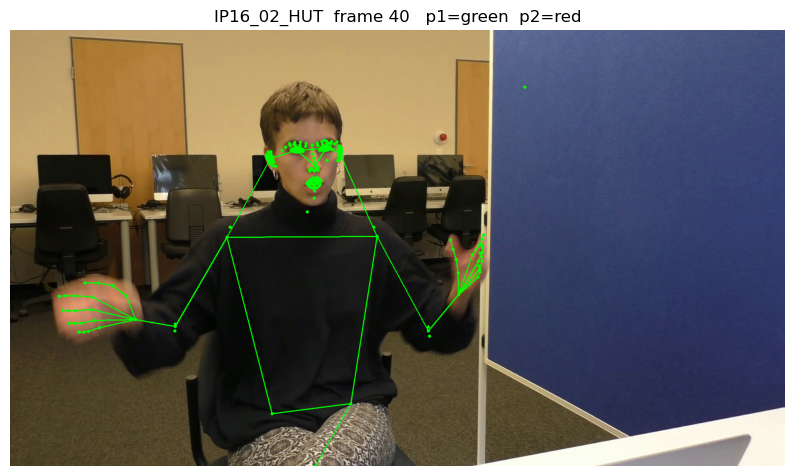

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\IP18_01_STINKEN\IP18_01_STINKEN_pose.csv
  showing frame 0


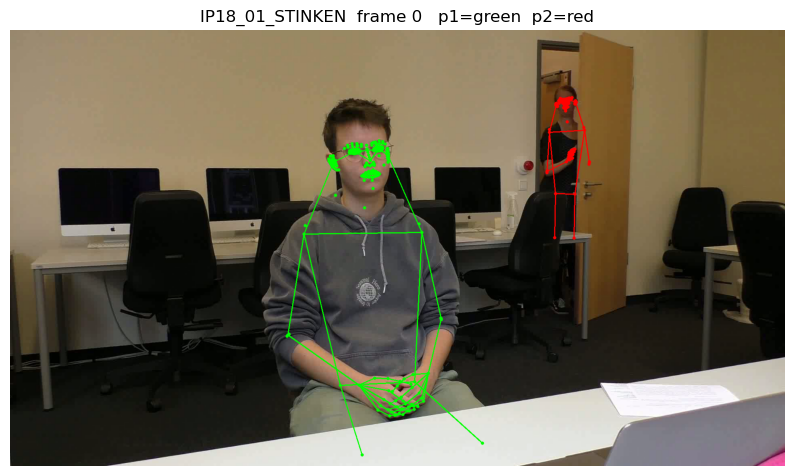

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP01_01_ARGUMENTIEREN\LP01_01_ARGUMENTIEREN_pose.csv
  showing frame 0


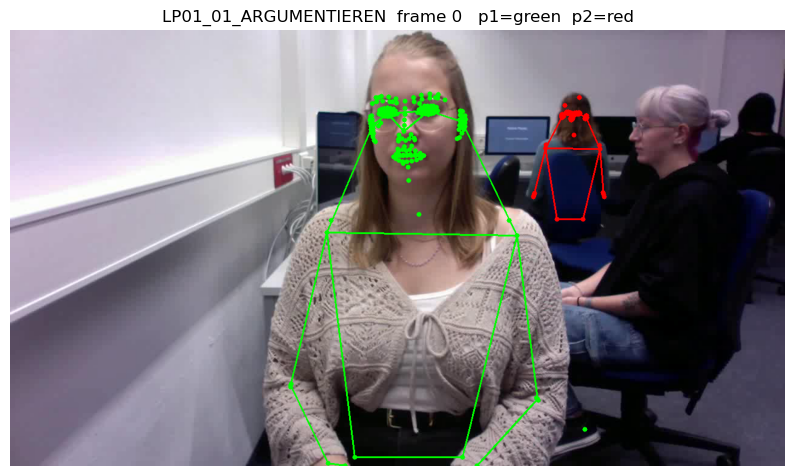

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP01_01_AUTO\LP01_01_AUTO_pose.csv
  showing frame 0


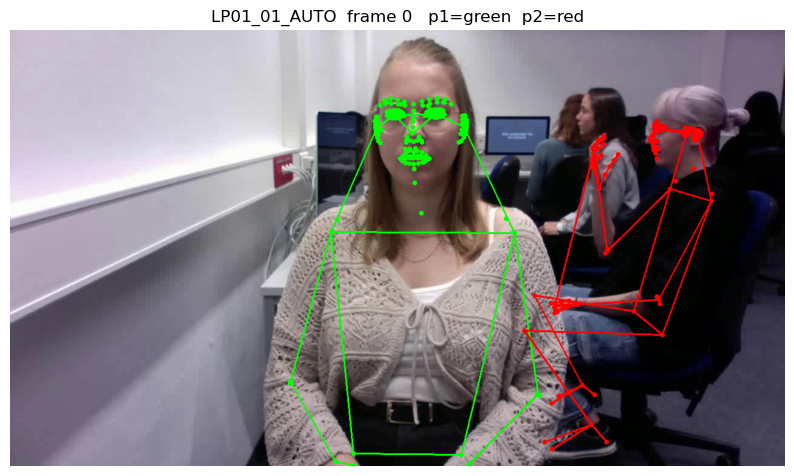

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP01_01_BASKETBALL\LP01_01_BASKETBALL_pose.csv
  showing frame 0


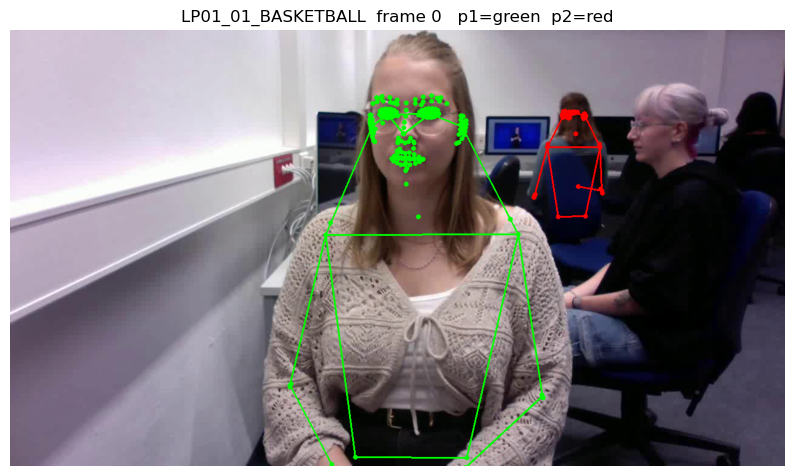

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP01_01_BIER\LP01_01_BIER_pose.csv
  showing frame 0


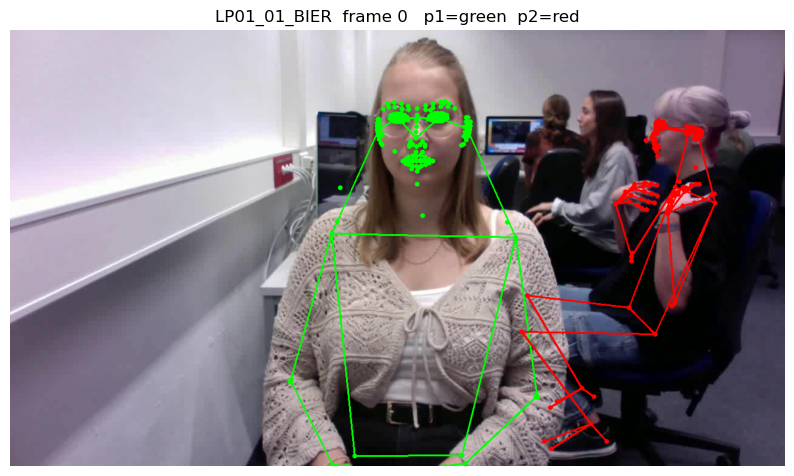

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP01_01_BRECHEN\LP01_01_BRECHEN_pose.csv
  showing frame 0


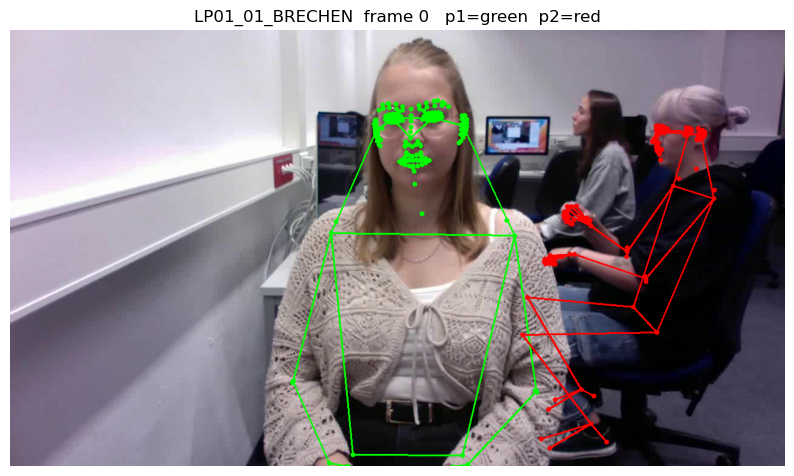

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP01_01_KOFFER\LP01_01_KOFFER_pose.csv
  showing frame 0


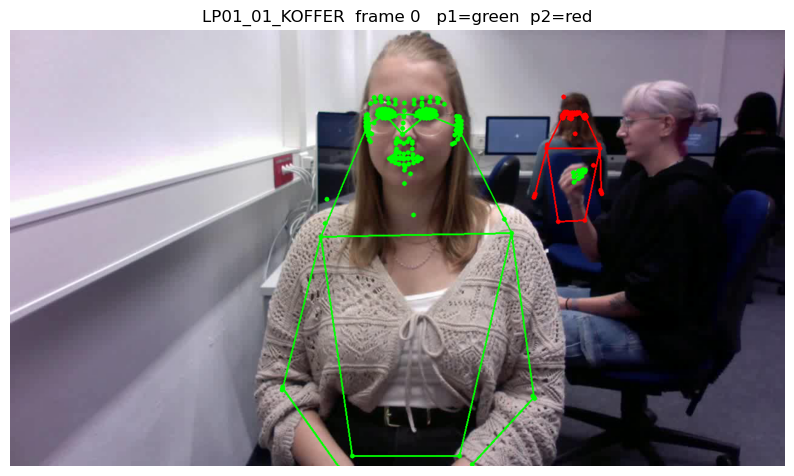

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP01_01_LIPPENSTIFT AUFTRAGEN\LP01_01_LIPPENSTIFT AUFTRAGEN_pose.csv
  showing frame 0


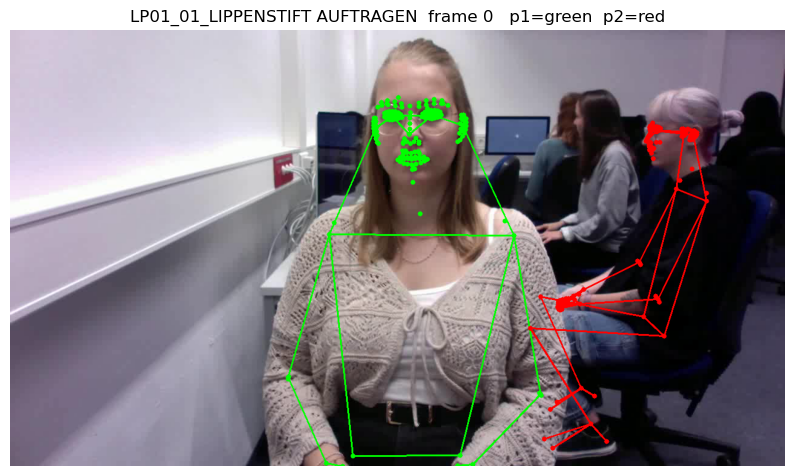

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP01_01_SANDWICH\LP01_01_SANDWICH_pose.csv
  showing frame 0


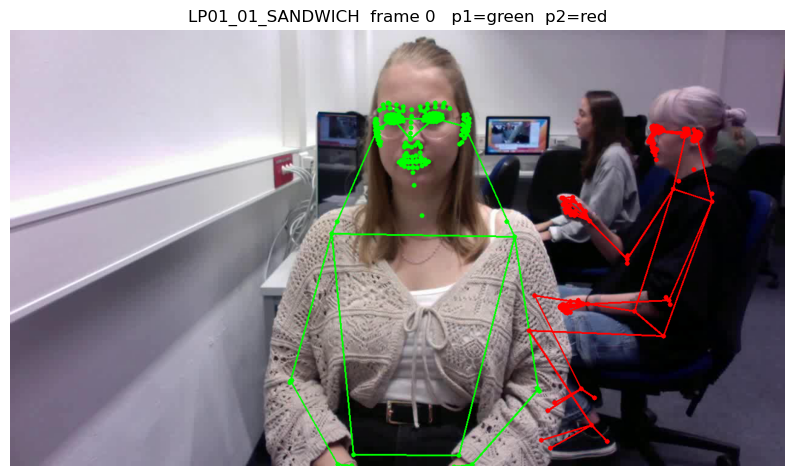

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP01_01_TEE\LP01_01_TEE_pose.csv
  showing frame 0


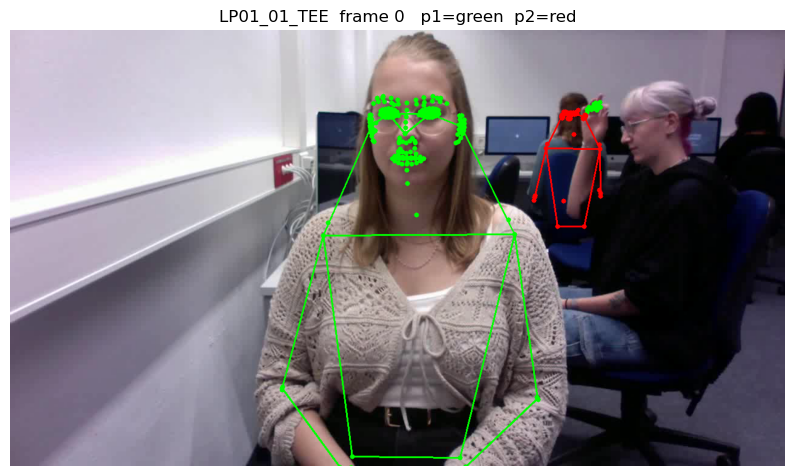

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP01_01_VERHEIRATET\LP01_01_VERHEIRATET_pose.csv
  showing frame 0


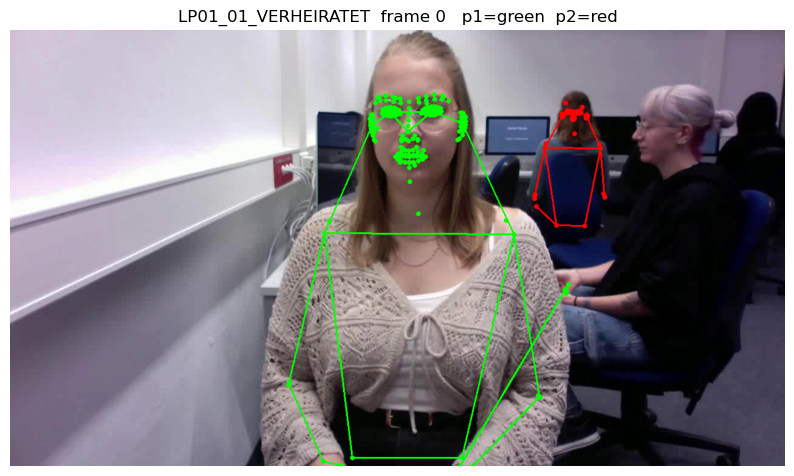

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP04_01_FRAGE\LP04_01_FRAGE_pose.csv
  showing frame 0


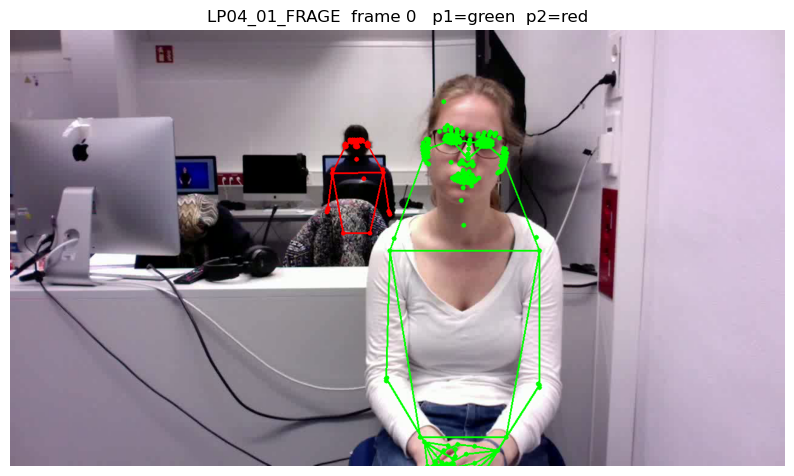

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP04_01_KRANKENWAGEN\LP04_01_KRANKENWAGEN_pose.csv
  showing frame 0


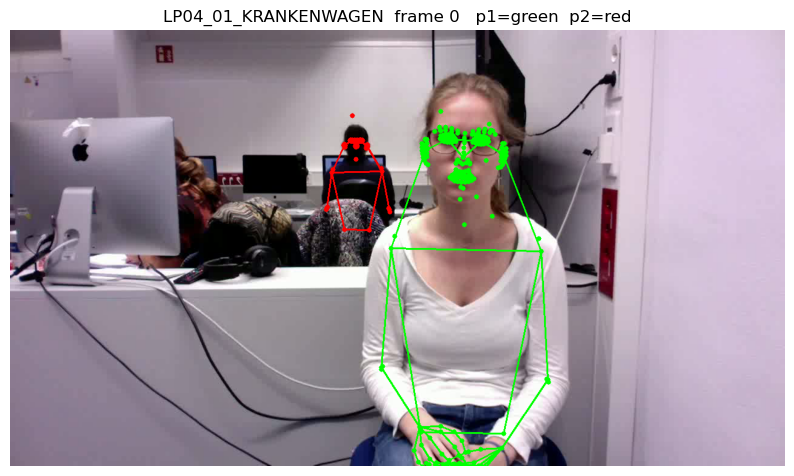

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP06_01_AUGE\LP06_01_AUGE_pose.csv
  showing frame 0


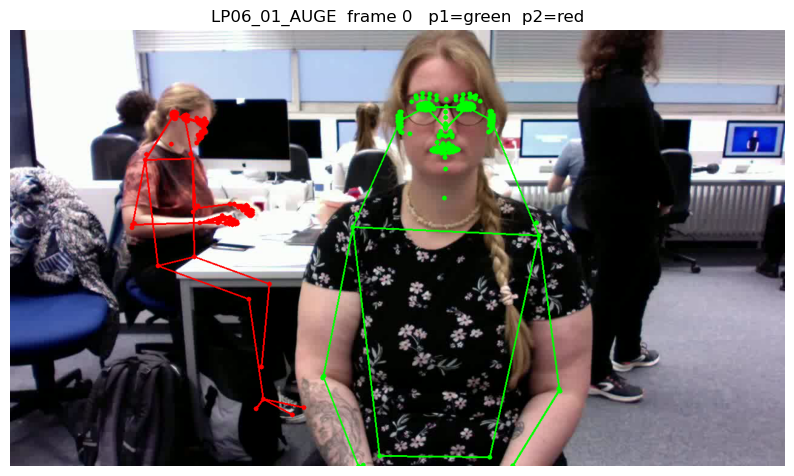

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP06_01_EI\LP06_01_EI_pose.csv
  showing frame 0


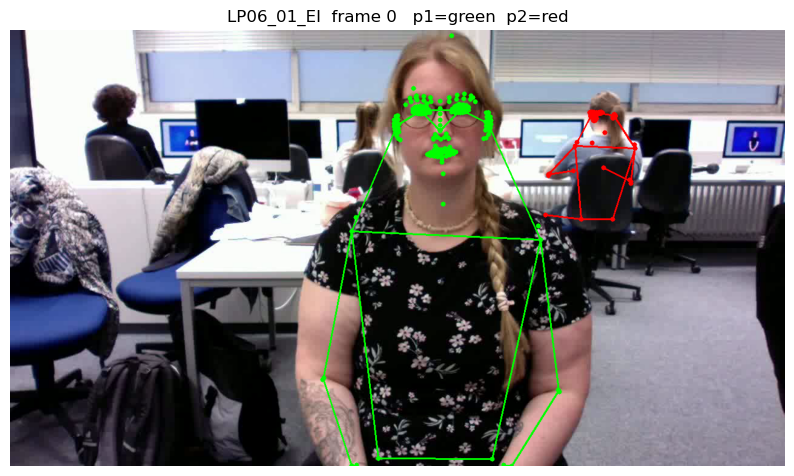

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP06_01_ESSEN\LP06_01_ESSEN_pose.csv
  showing frame 0


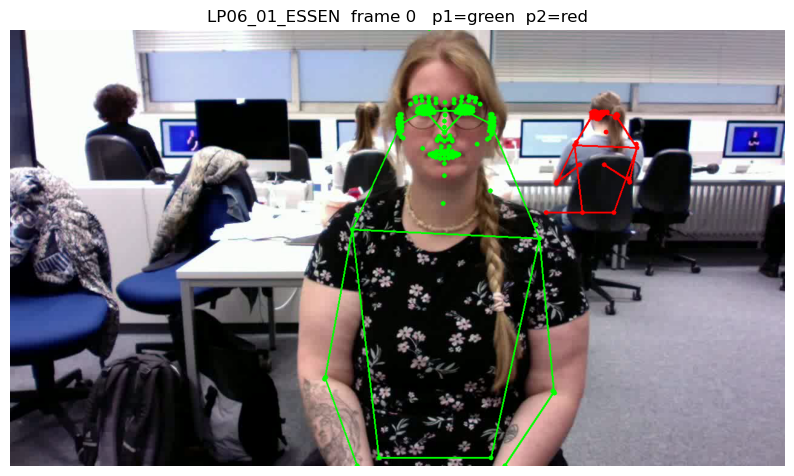

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP06_01_HOCKEY\LP06_01_HOCKEY_pose.csv
  showing frame 0


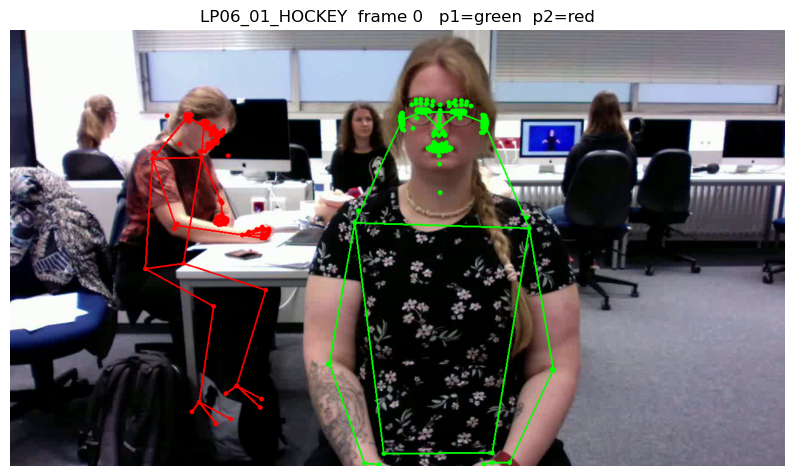

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP06_01_HUEGEL\LP06_01_HUEGEL_pose.csv
  showing frame 0


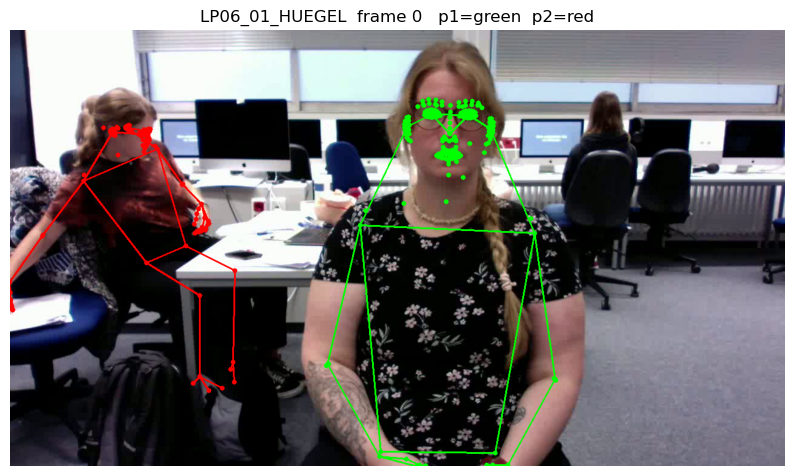

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP06_01_LOEFFEL\LP06_01_LOEFFEL_pose.csv
  showing frame 0


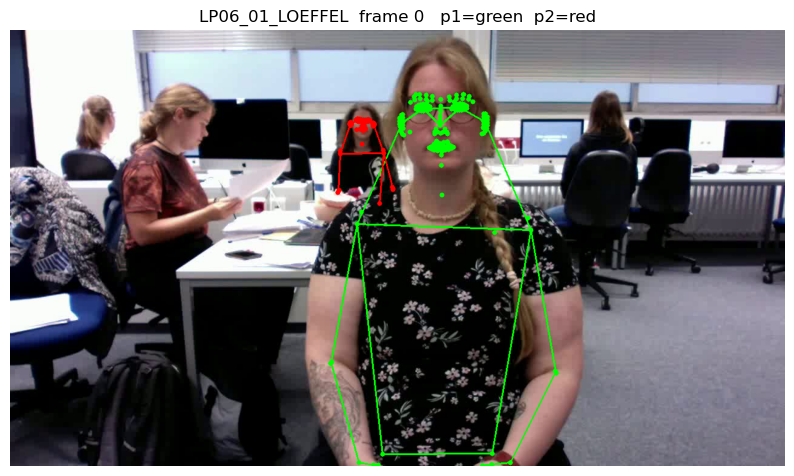

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP06_01_PFLUECKEN\LP06_01_PFLUECKEN_pose.csv
  showing frame 0


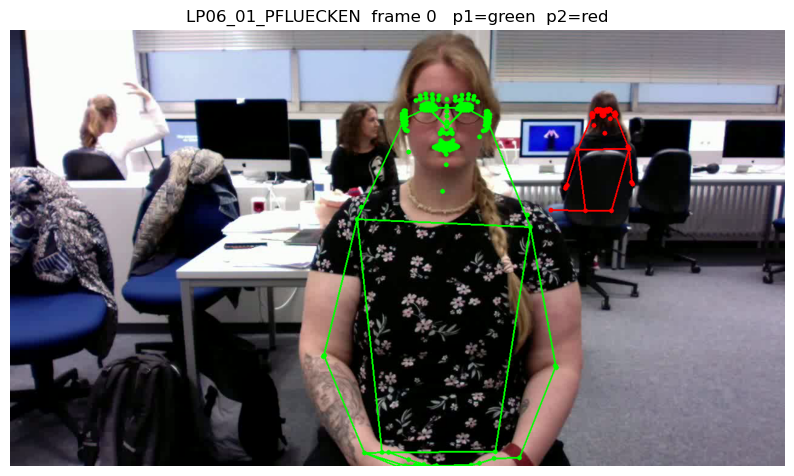

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP06_01_SCHLAFEN\LP06_01_SCHLAFEN_pose.csv
  showing frame 0


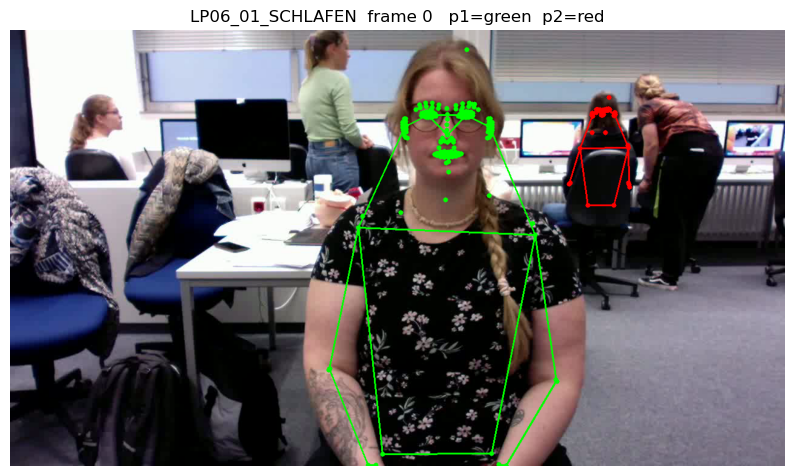

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP06_01_SCHMETTERLING\LP06_01_SCHMETTERLING_pose.csv
  showing frame 0


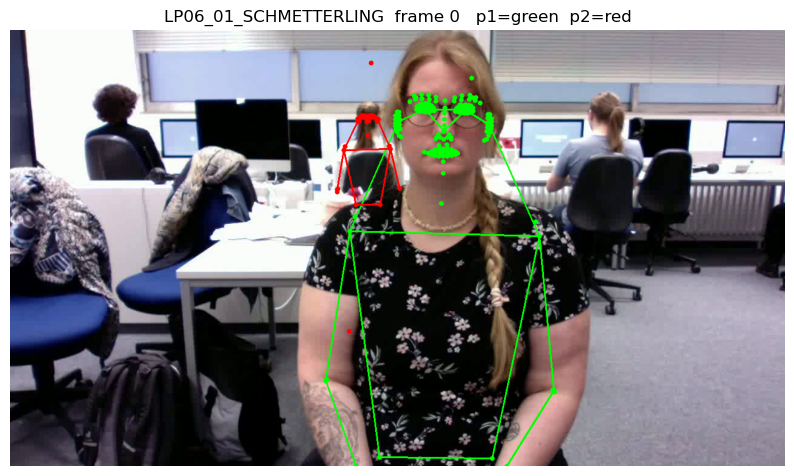

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP06_01_VERGANGENHEIT\LP06_01_VERGANGENHEIT_pose.csv
  showing frame 0


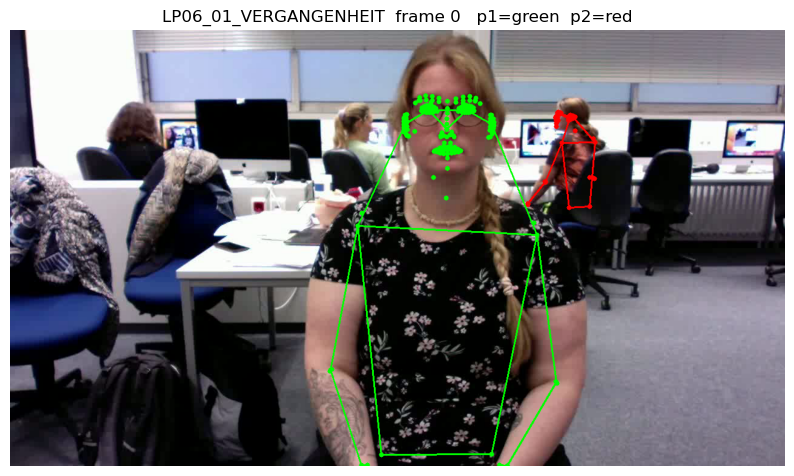

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP07_01_AUTO\LP07_01_AUTO_pose.csv
  showing frame 0


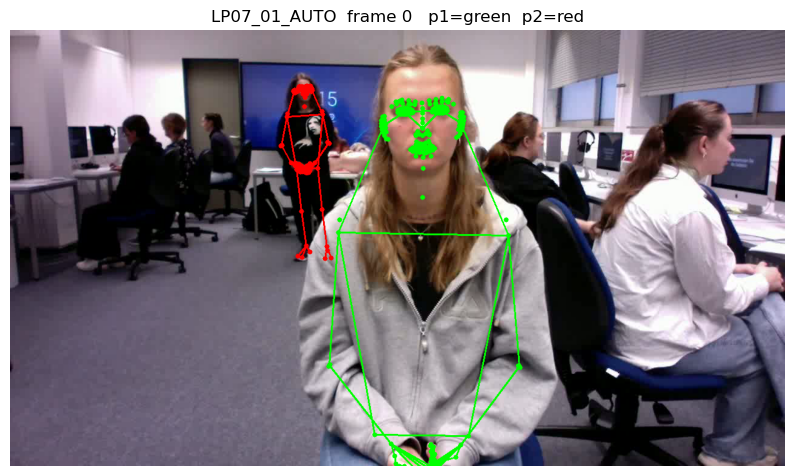

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP07_01_BODEN\LP07_01_BODEN_pose.csv
  showing frame 0


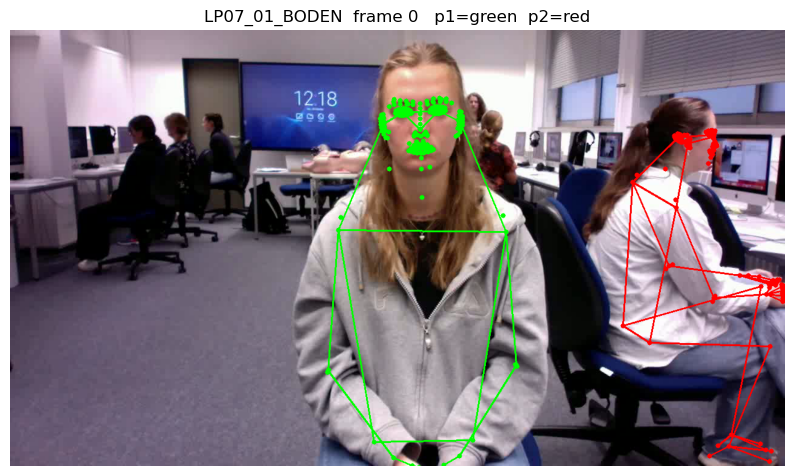

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP07_01_EGAL\LP07_01_EGAL_pose.csv
  showing frame 0


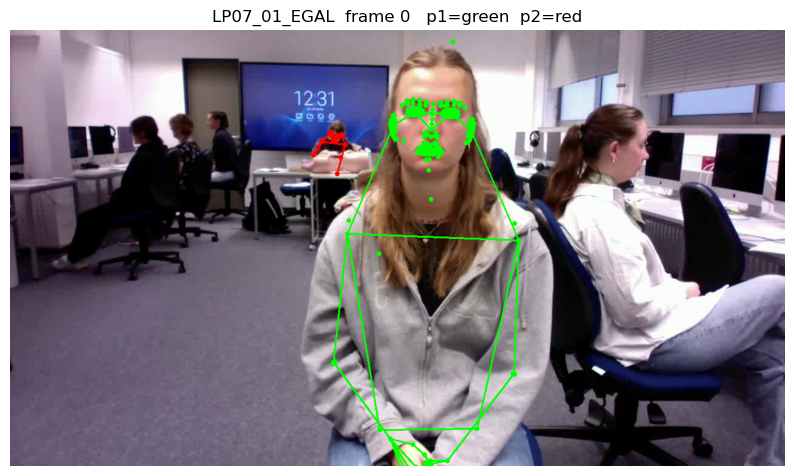

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP07_01_FEUER\LP07_01_FEUER_pose.csv
  showing frame 0


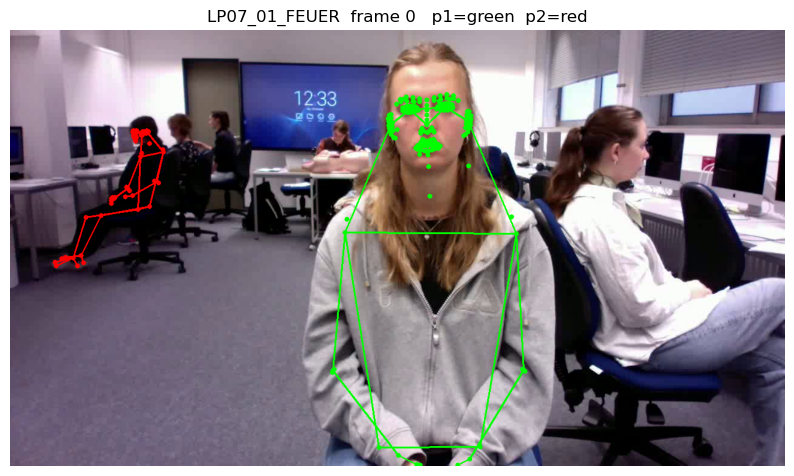

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP07_01_KLATSCHEN\LP07_01_KLATSCHEN_pose.csv
  showing frame 0


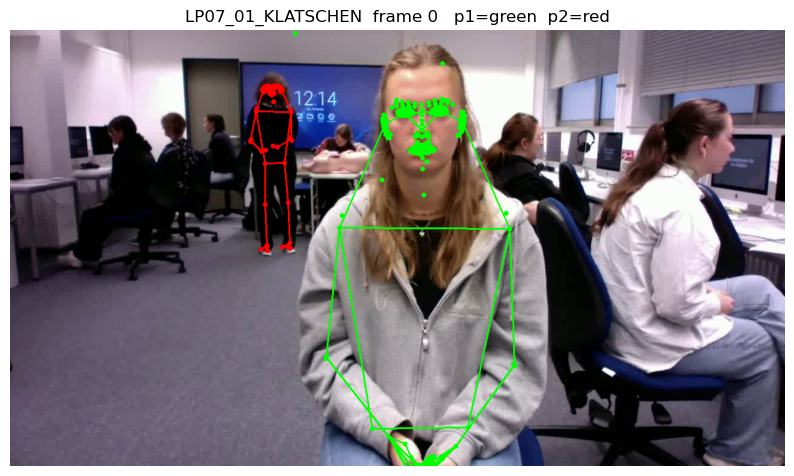

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP07_01_KRIEG\LP07_01_KRIEG_pose.csv
  showing frame 0


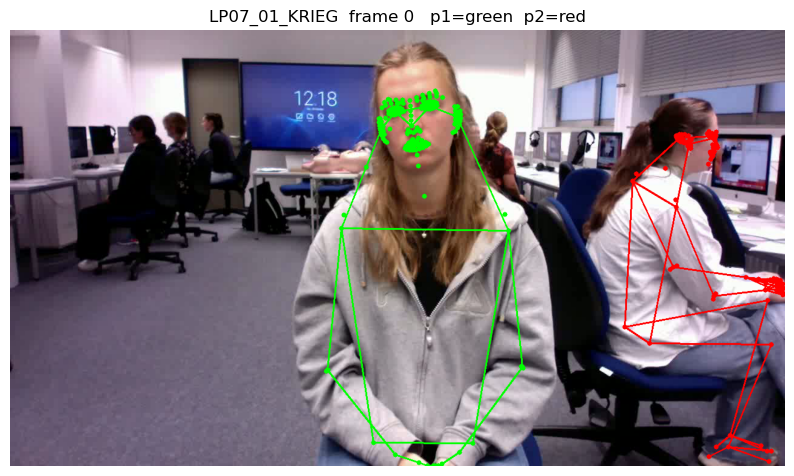

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP07_01_PFANNE\LP07_01_PFANNE_pose.csv
  showing frame 0


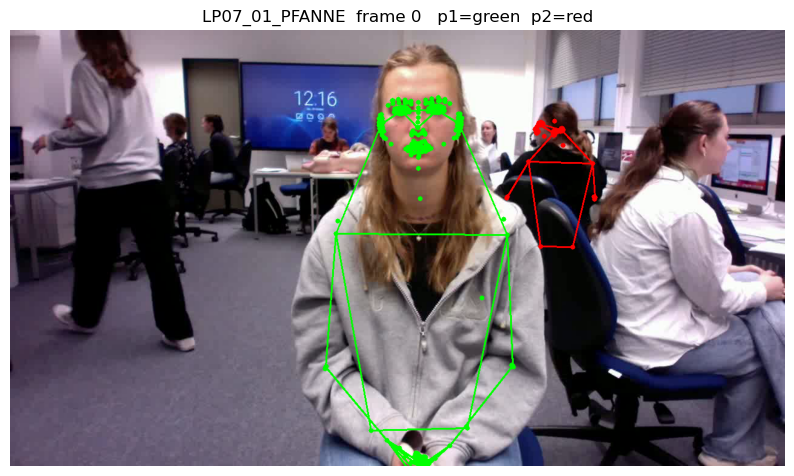

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP07_01_SAGEN\LP07_01_SAGEN_pose.csv
  showing frame 0


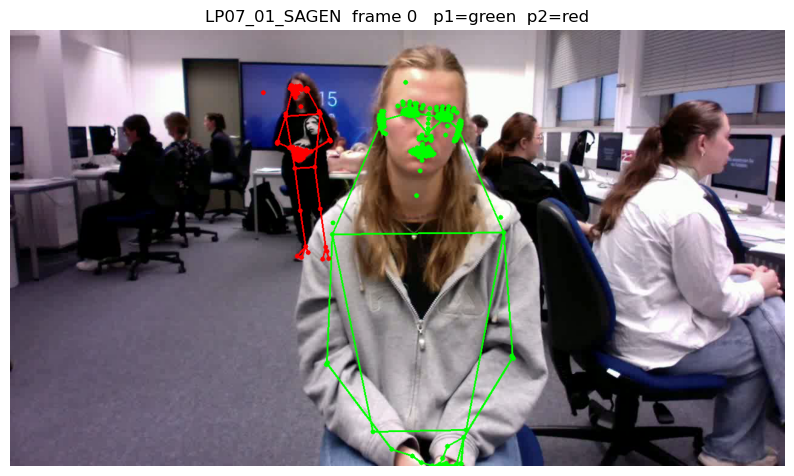

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP07_01_SPINNE\LP07_01_SPINNE_pose.csv
  showing frame 0


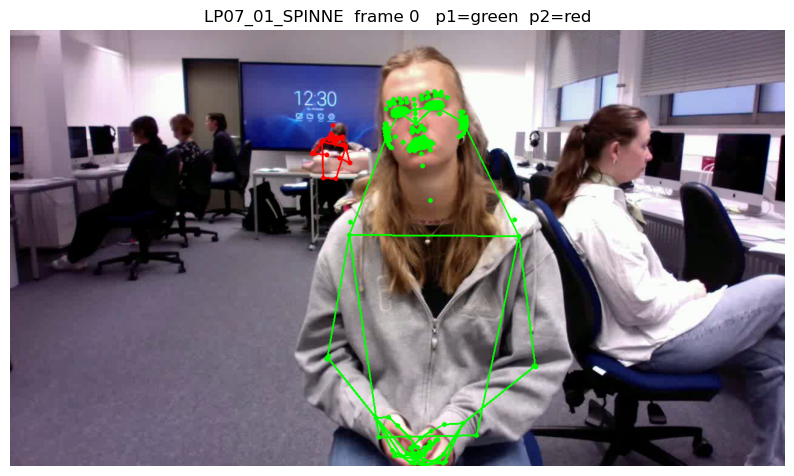

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP07_01_TENNIS\LP07_01_TENNIS_pose.csv
  showing frame 0


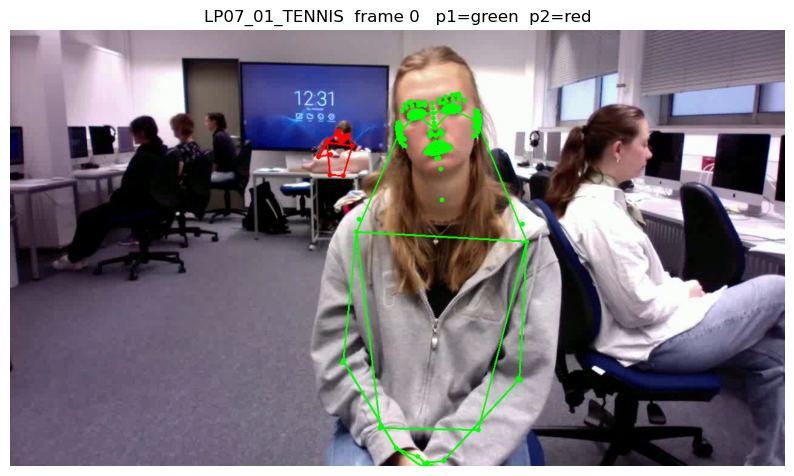

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP08_01_AKKORDEON\LP08_01_AKKORDEON_pose.csv
  showing frame 0


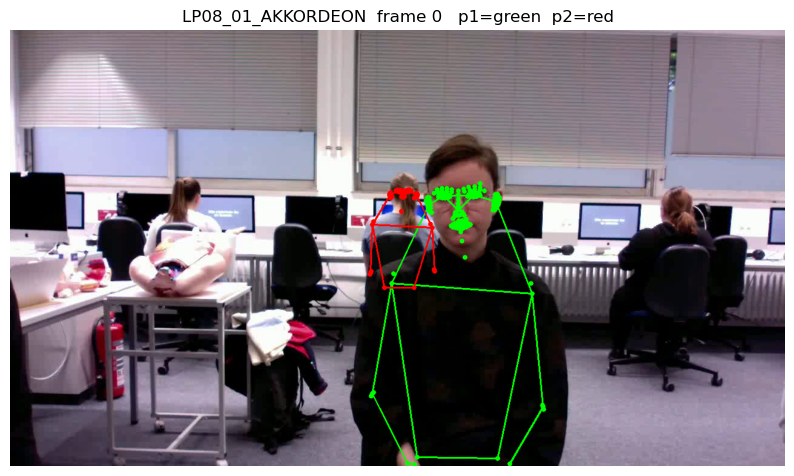

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP08_01_BIER\LP08_01_BIER_pose.csv
  showing frame 0


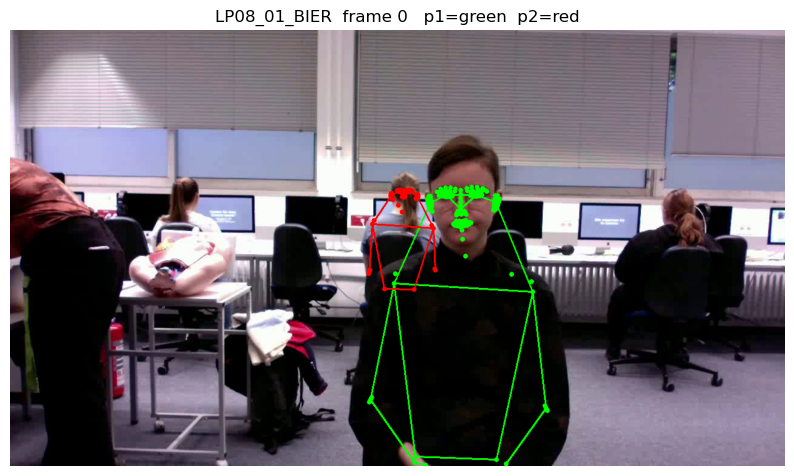

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP08_01_EI\LP08_01_EI_pose.csv
  showing frame 0


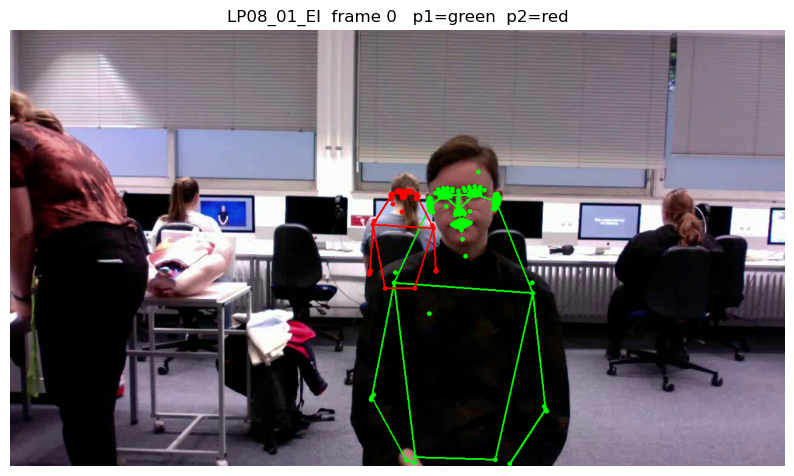

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP08_01_SAEGE\LP08_01_SAEGE_pose.csv
  showing frame 0


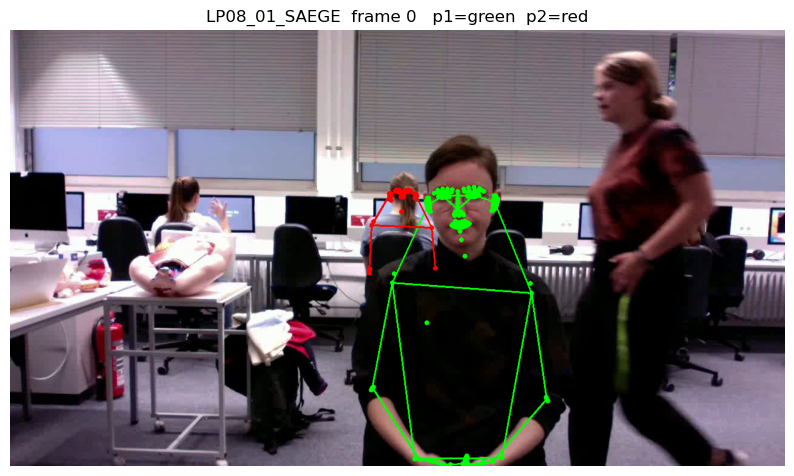

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP08_01_SCHAMPOO\LP08_01_SCHAMPOO_pose.csv
  showing frame 0


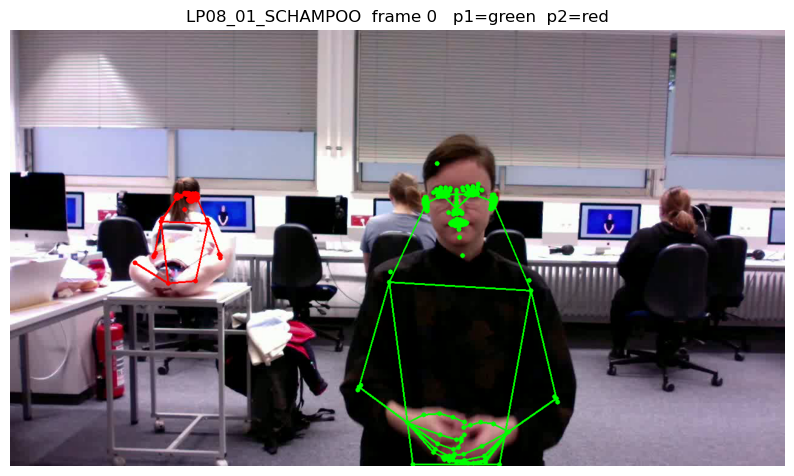

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP08_01_SCHLAFEN\LP08_01_SCHLAFEN_pose.csv
  showing frame 0


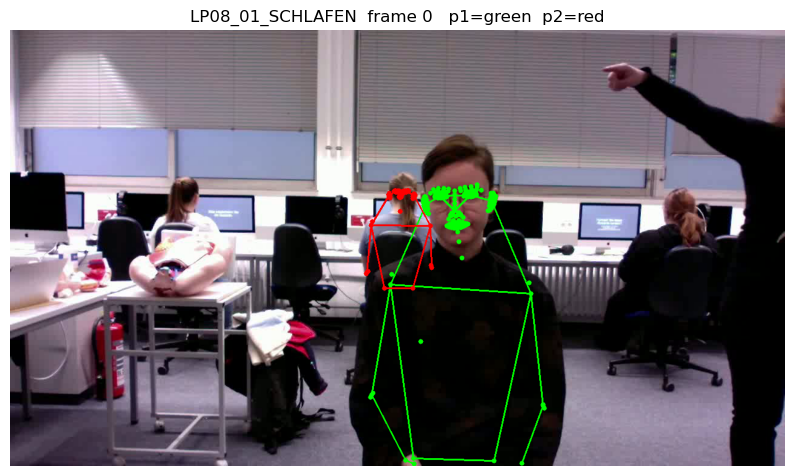

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP08_01_TEE\LP08_01_TEE_pose.csv
  showing frame 0


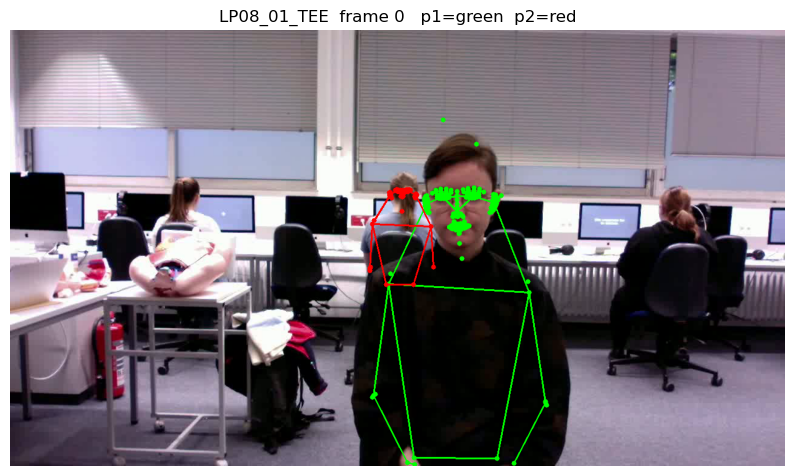

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP08_01_TEUFEL\LP08_01_TEUFEL_pose.csv
  showing frame 0


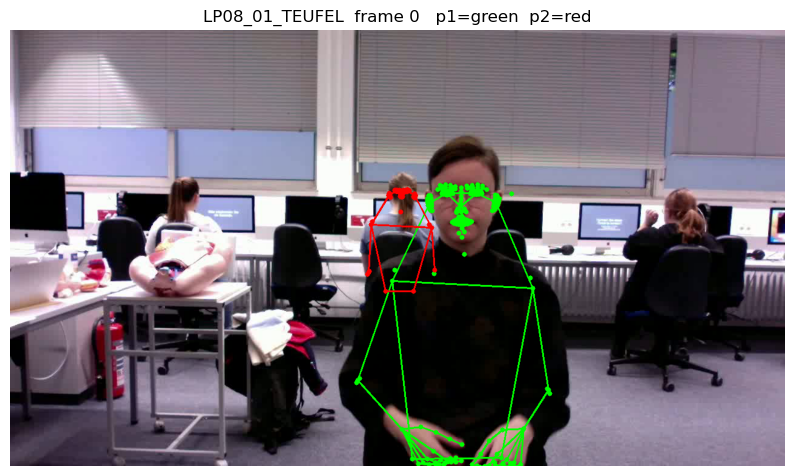

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP08_01_UMZIEHEN\LP08_01_UMZIEHEN_pose.csv
  showing frame 0


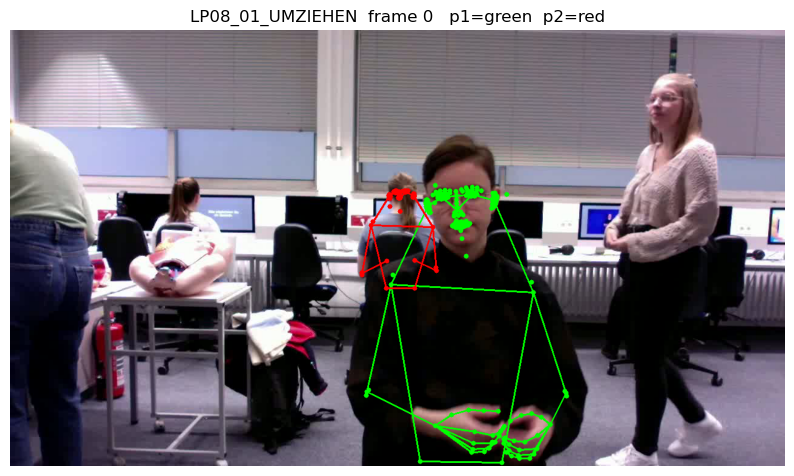

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP08_01_VORSCHLAGEN\LP08_01_VORSCHLAGEN_pose.csv
  showing frame 0


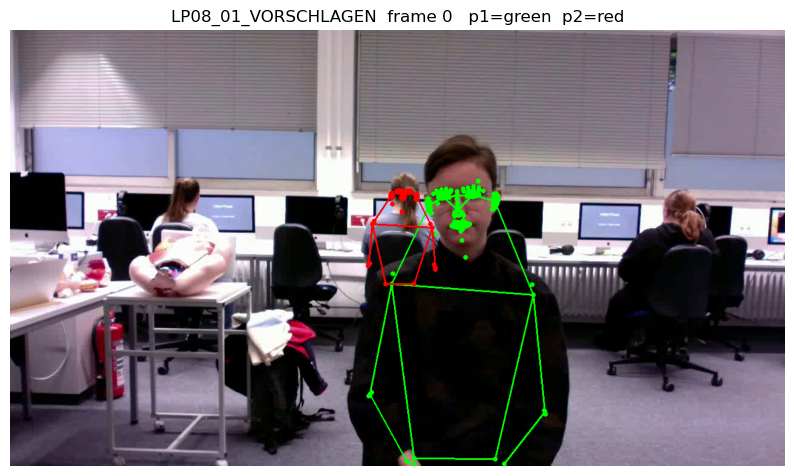

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP08_01_WENIG\LP08_01_WENIG_pose.csv
  showing frame 0


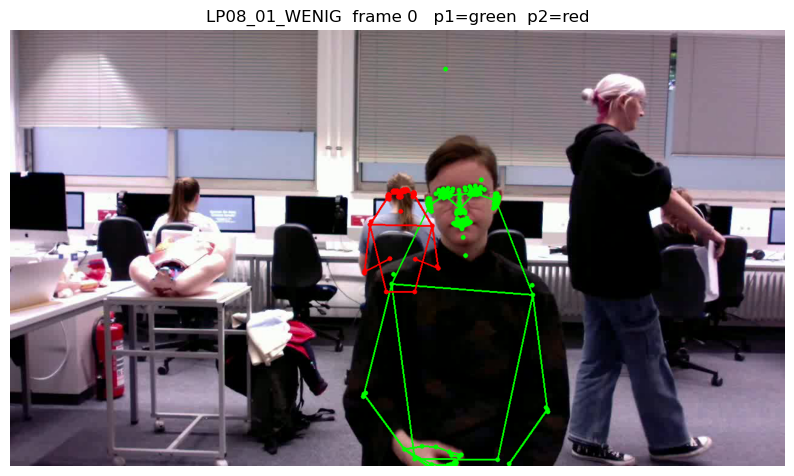

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP13_01_BRILLE\LP13_01_BRILLE_pose.csv
  showing frame 0


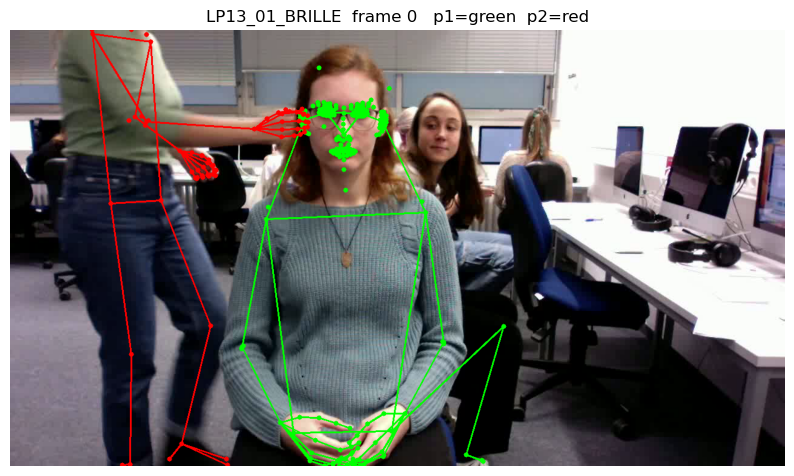

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP13_01_HEBEN\LP13_01_HEBEN_pose.csv
  showing frame 0


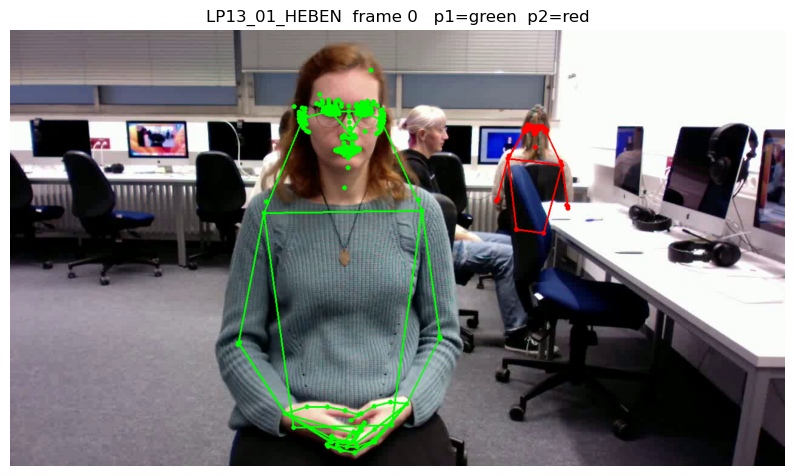

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP13_01_JUCKEN\LP13_01_JUCKEN_pose.csv
  showing frame 0


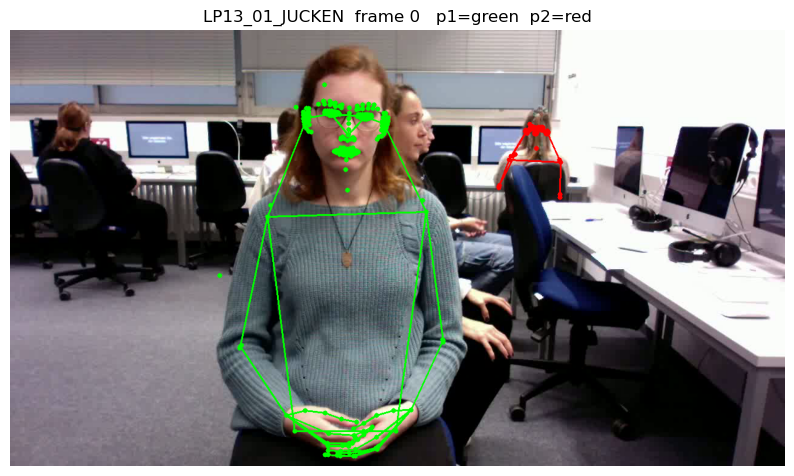

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP13_01_KRIEG\LP13_01_KRIEG_pose.csv
  showing frame 0


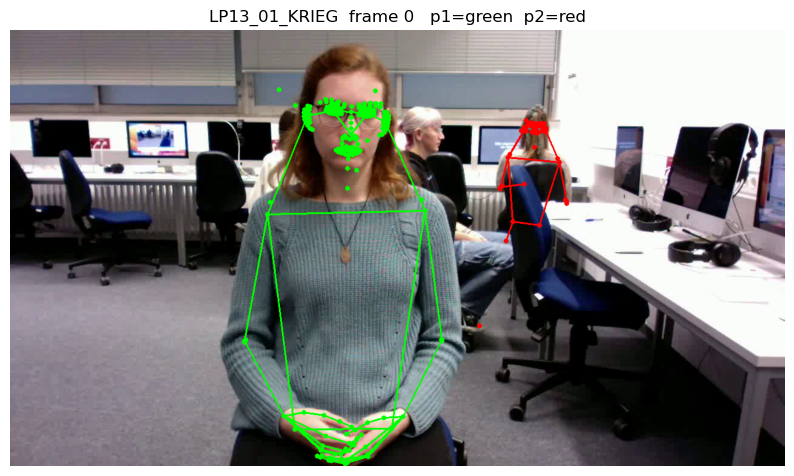

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP13_01_MILCH\LP13_01_MILCH_pose.csv
  showing frame 0


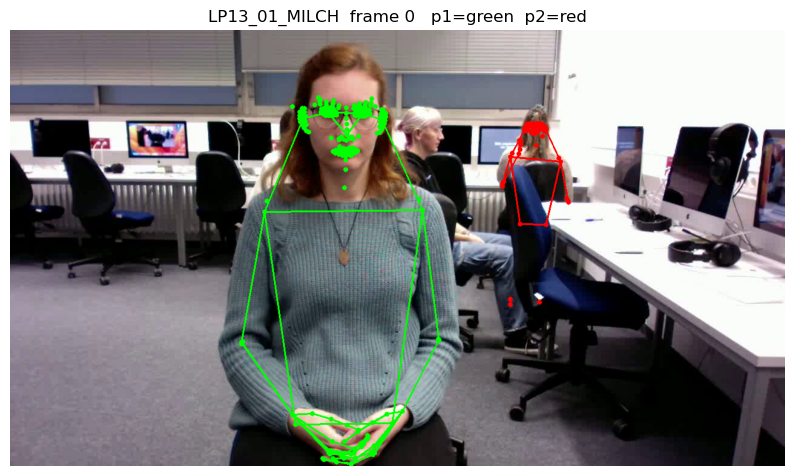

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP13_01_MIXER\LP13_01_MIXER_pose.csv
  showing frame 0


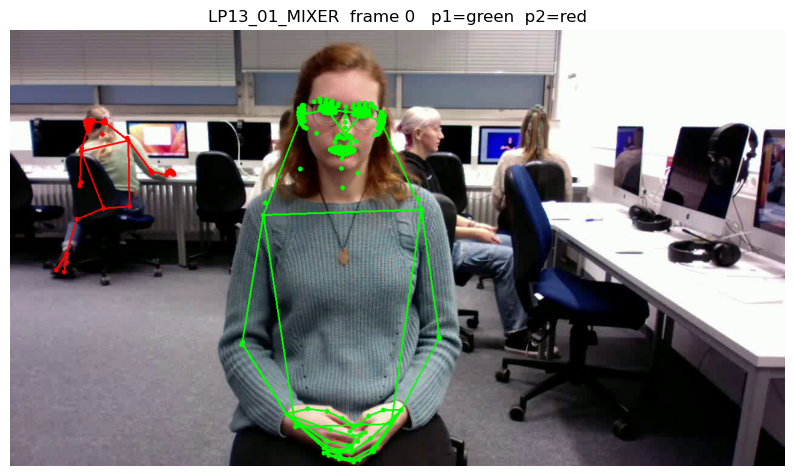

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP13_01_PYRAMIDE\LP13_01_PYRAMIDE_pose.csv
  showing frame 0


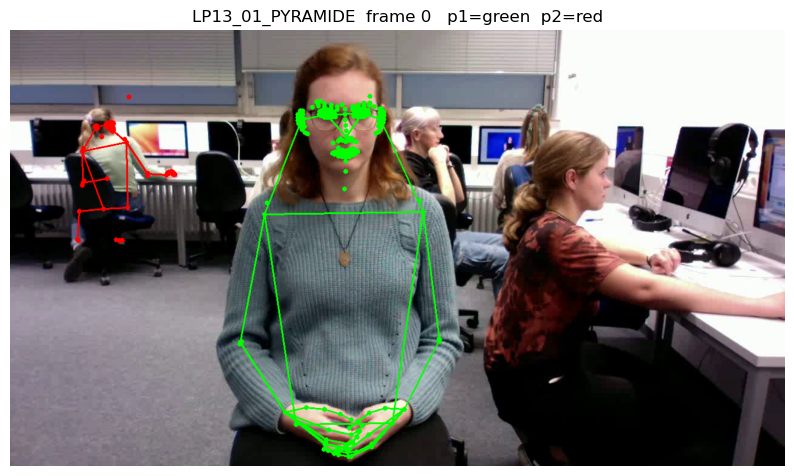

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP13_01_TISCHTENNIS\LP13_01_TISCHTENNIS_pose.csv
  showing frame 0


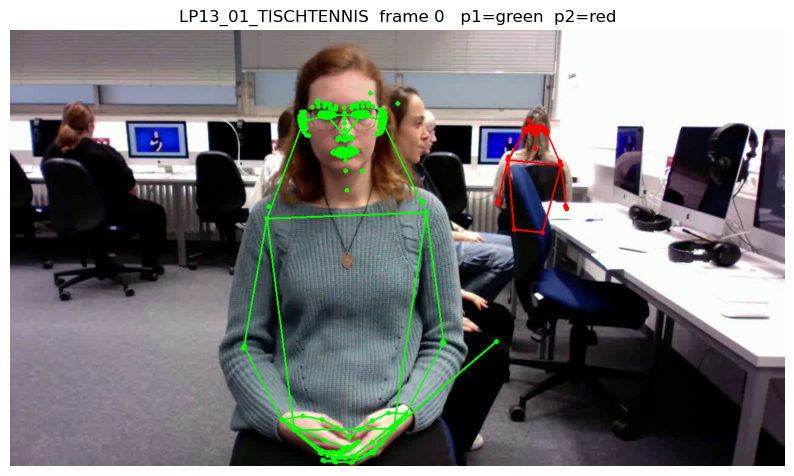

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP13_01_VERGANGENHEIT\LP13_01_VERGANGENHEIT_pose.csv
  showing frame 0


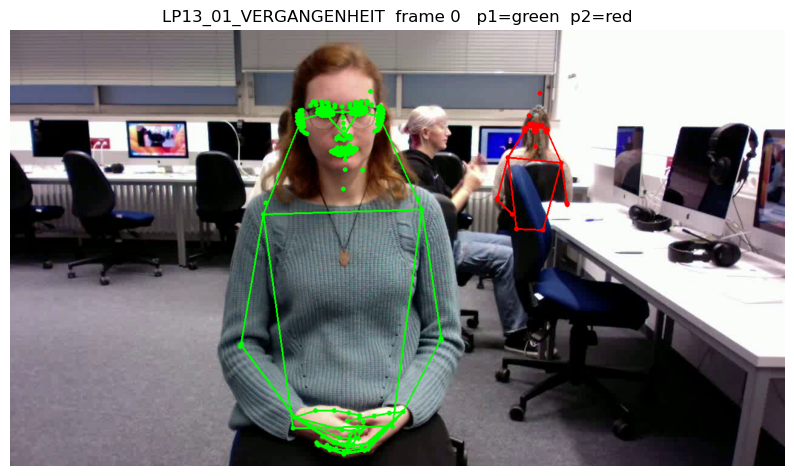

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP13_01_VOGEL\LP13_01_VOGEL_pose.csv
  showing frame 0


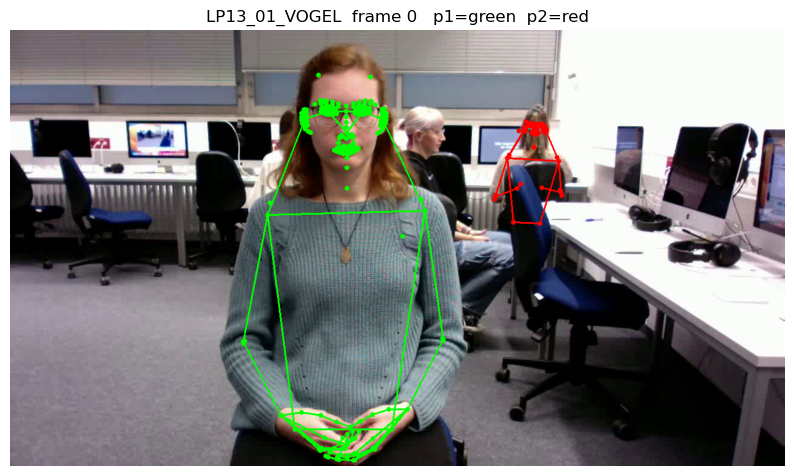

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP13_01_ZEIT\LP13_01_ZEIT_pose.csv
  showing frame 0


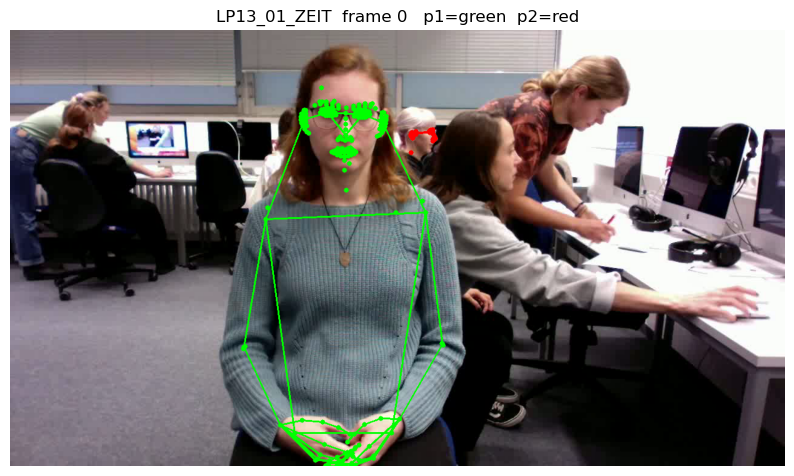

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP14_01_AUSRADIEREN\LP14_01_AUSRADIEREN_pose.csv
  showing frame 0


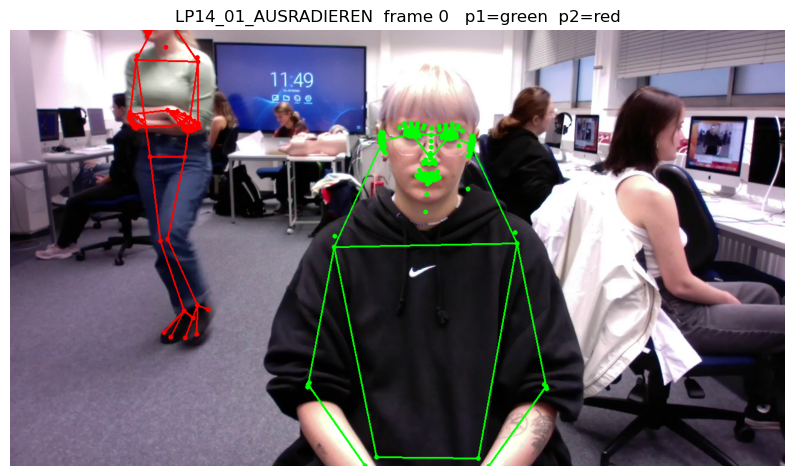

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP14_01_KAEMMEN\LP14_01_KAEMMEN_pose.csv
  showing frame 0


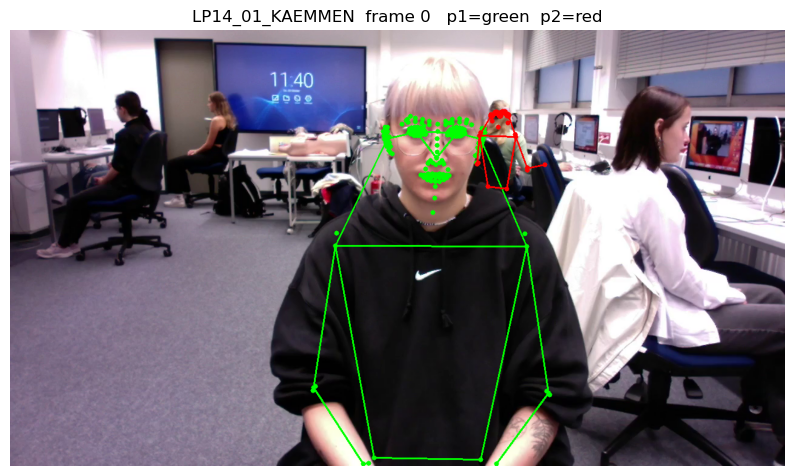

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP14_01_KRIEG\LP14_01_KRIEG_pose.csv
  showing frame 0


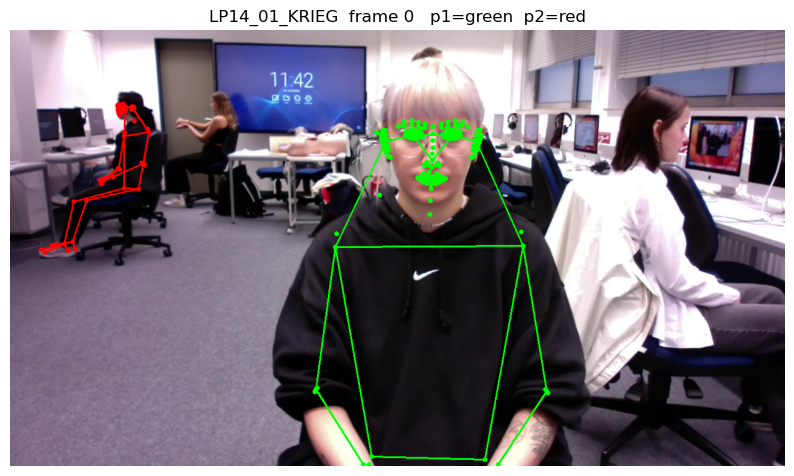

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP14_01_MOTORRAD\LP14_01_MOTORRAD_pose.csv
  showing frame 0


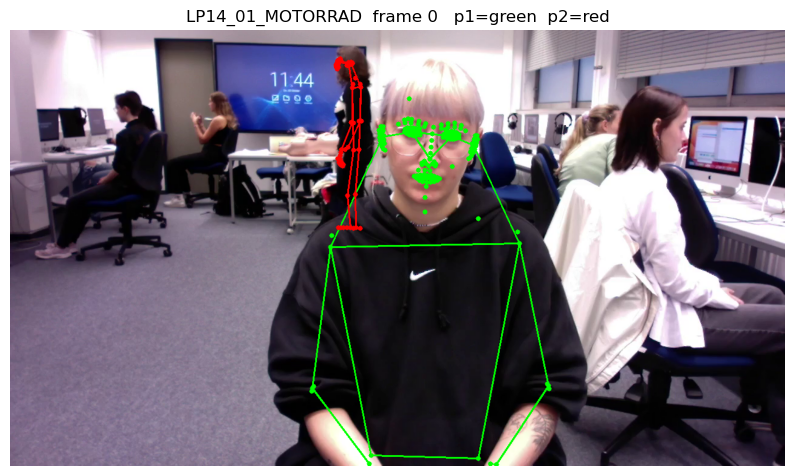

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP14_01_RASIEREN\LP14_01_RASIEREN_pose.csv
  showing frame 0


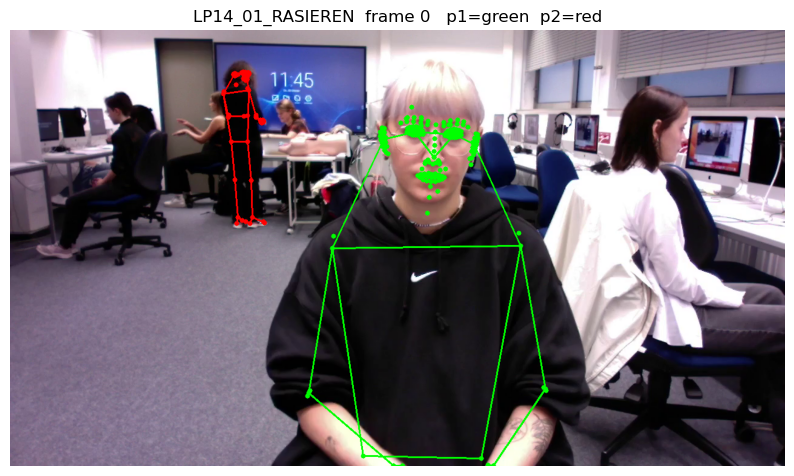

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP14_01_ROLLSTUHL\LP14_01_ROLLSTUHL_pose.csv
  showing frame 0


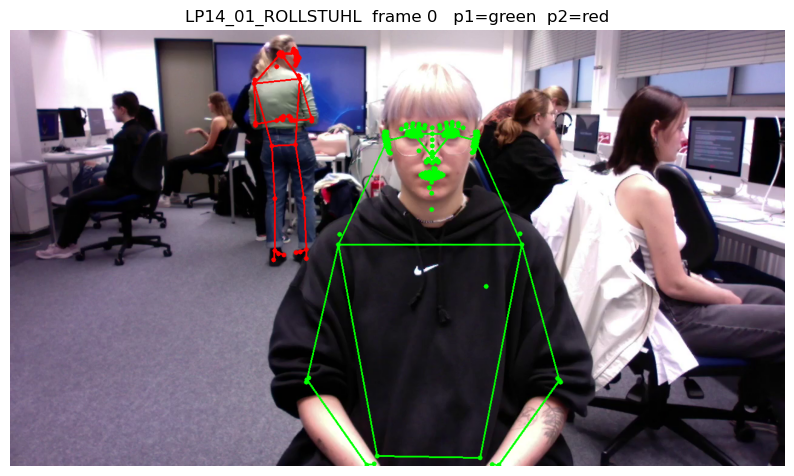

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP14_01_SCHRAUBENZIEHER\LP14_01_SCHRAUBENZIEHER_pose.csv
  showing frame 0


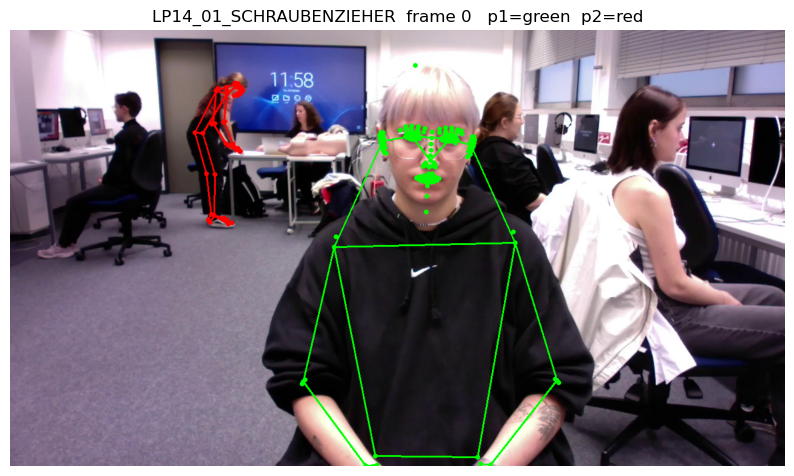

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP14_01_TRINKWASSER\LP14_01_TRINKWASSER_pose.csv
  showing frame 0


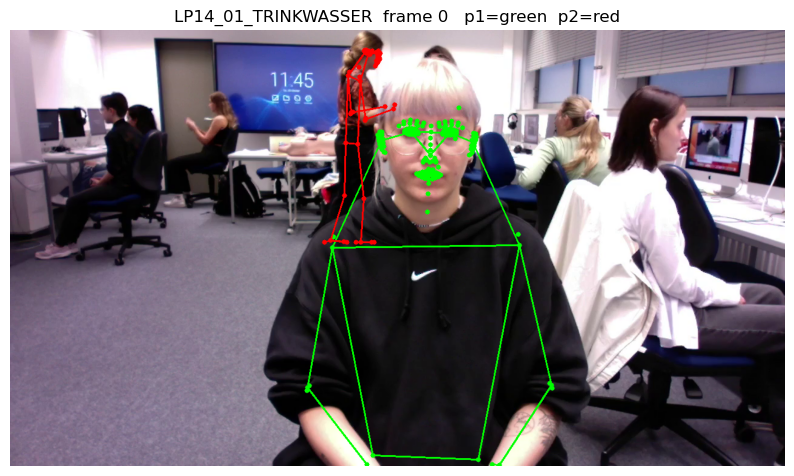

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP14_01_UNTERTITEL\LP14_01_UNTERTITEL_pose.csv
  showing frame 0


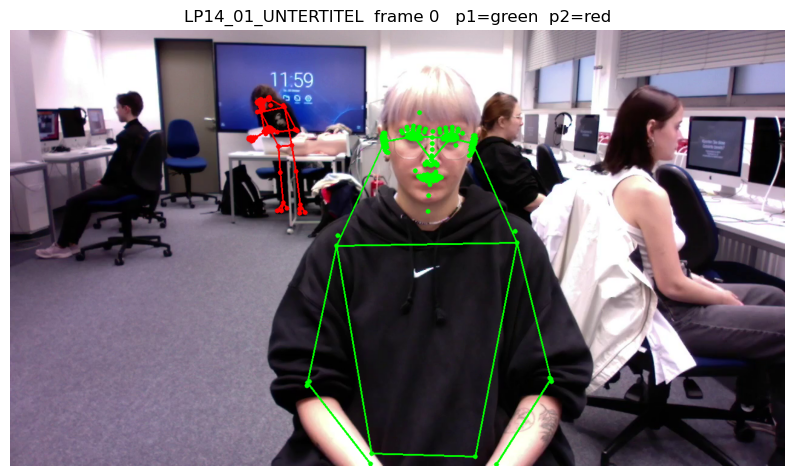

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP14_01_WARTEN\LP14_01_WARTEN_pose.csv
  showing frame 0


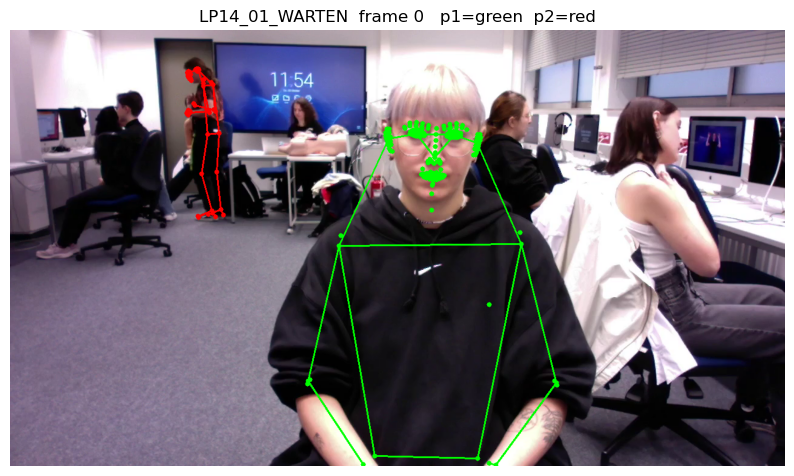

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP15_01_AFFE\LP15_01_AFFE_pose.csv
  showing frame 0


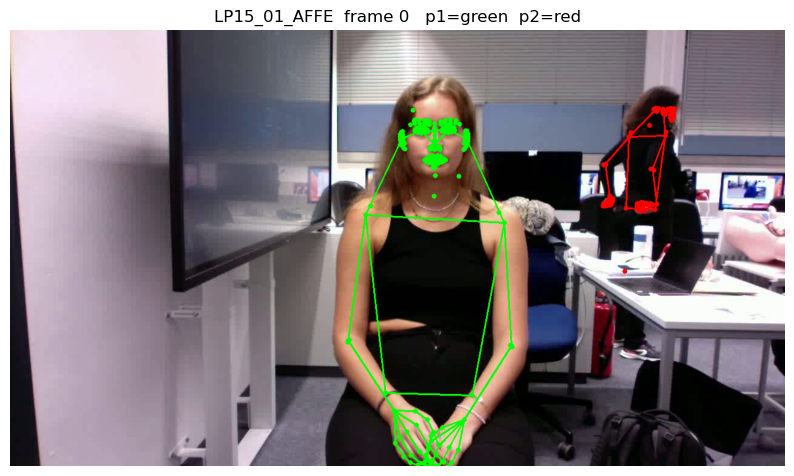

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP15_01_BRIEF\LP15_01_BRIEF_pose.csv
  showing frame 0


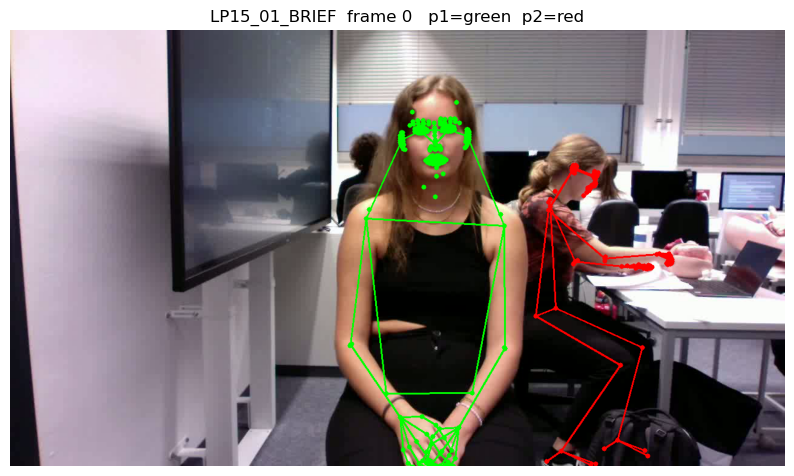

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP15_01_KARTEN\LP15_01_KARTEN_pose.csv
  showing frame 0


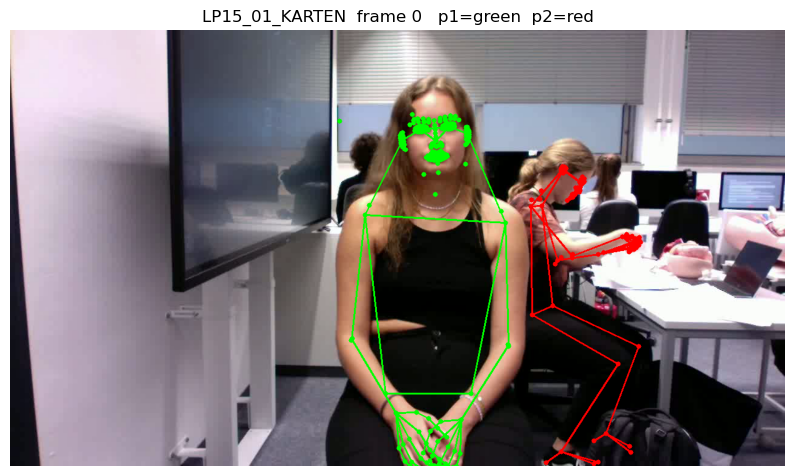

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP15_01_KLEIDUNG\LP15_01_KLEIDUNG_pose.csv
  showing frame 0


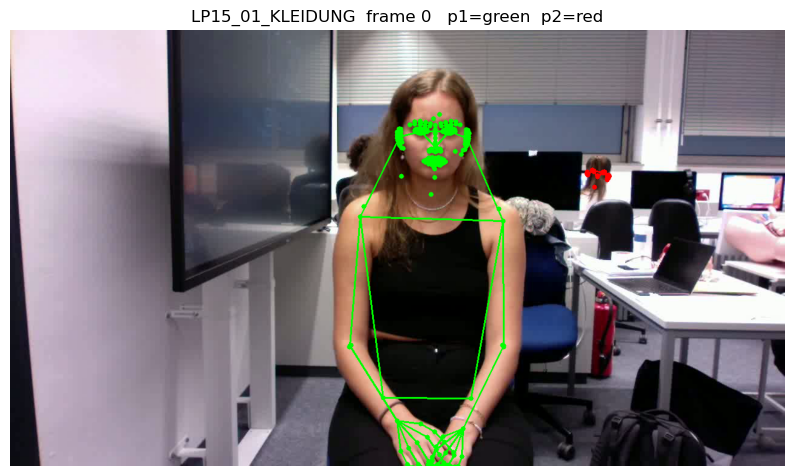

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP15_01_KRANKENWAGEN\LP15_01_KRANKENWAGEN_pose.csv
  showing frame 0


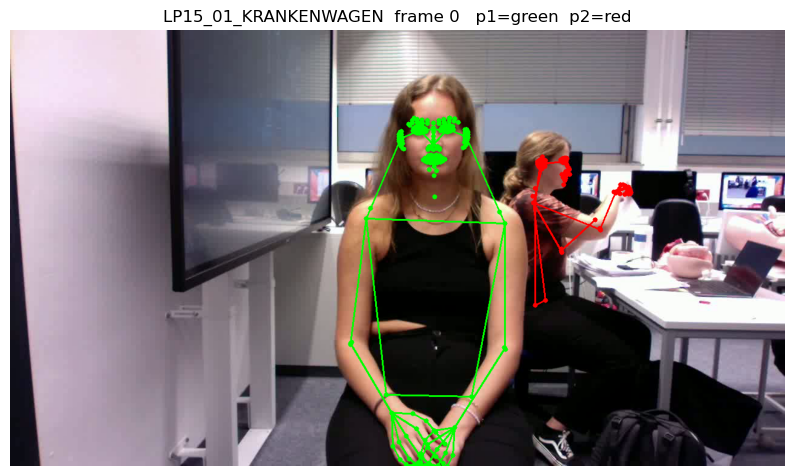

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP15_01_MANTEL\LP15_01_MANTEL_pose.csv
  showing frame 0


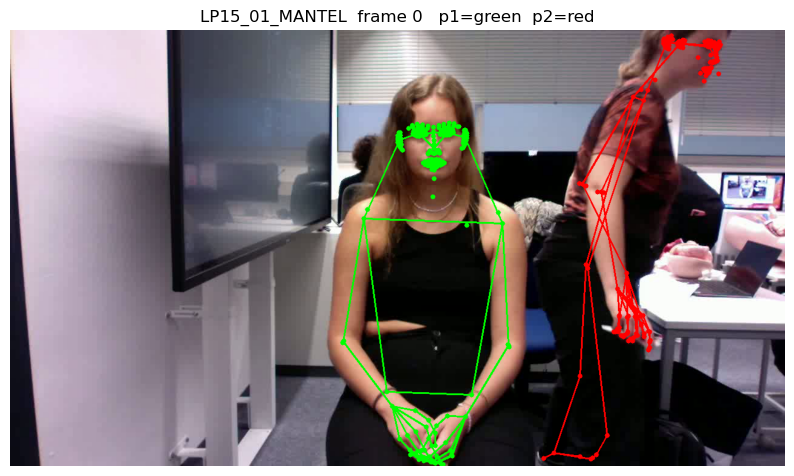

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP15_01_MOND\LP15_01_MOND_pose.csv
  showing frame 0


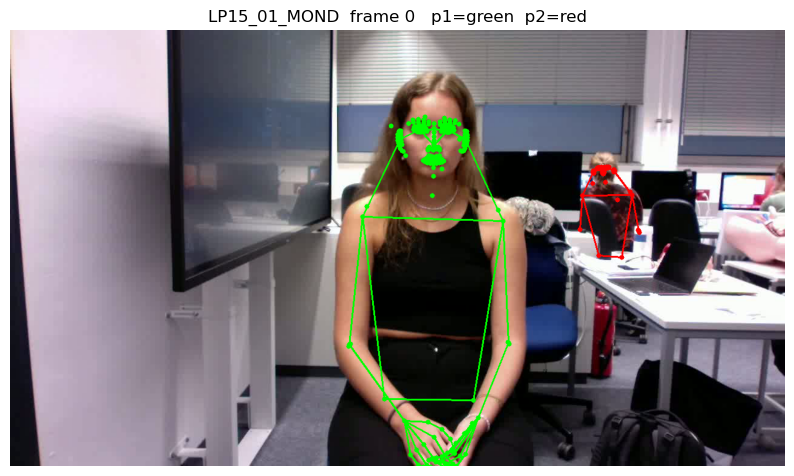

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP15_01_MOTORRAD\LP15_01_MOTORRAD_pose.csv
  showing frame 0


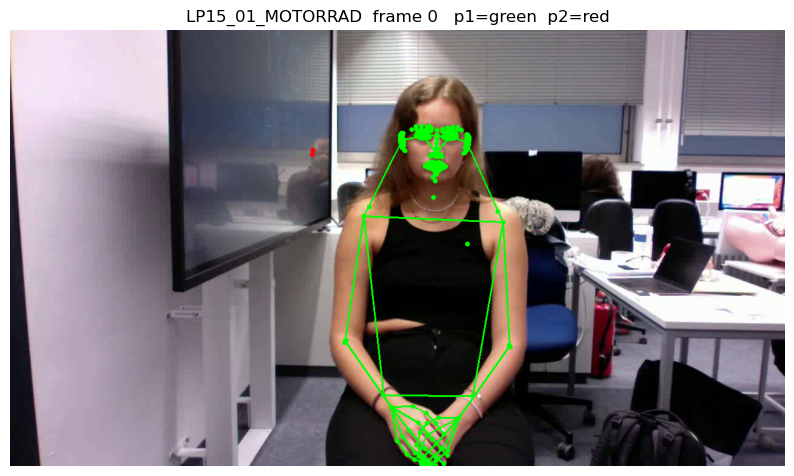

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP15_01_SAEGE\LP15_01_SAEGE_pose.csv
  showing frame 0


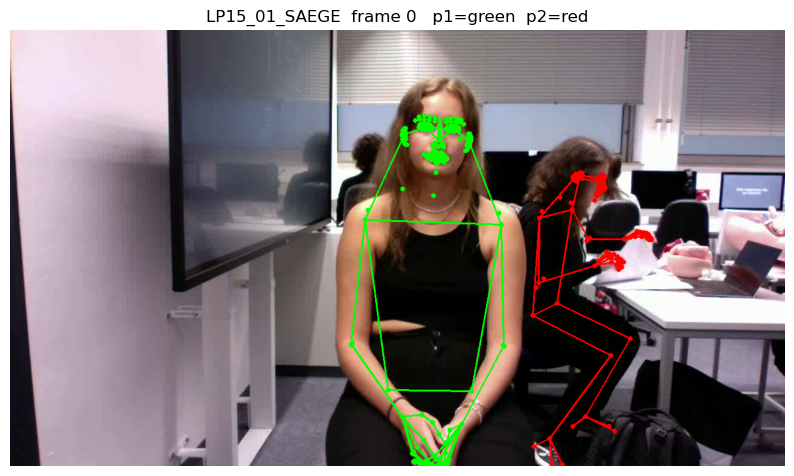

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP15_01_SAXOPHON\LP15_01_SAXOPHON_pose.csv
  showing frame 0


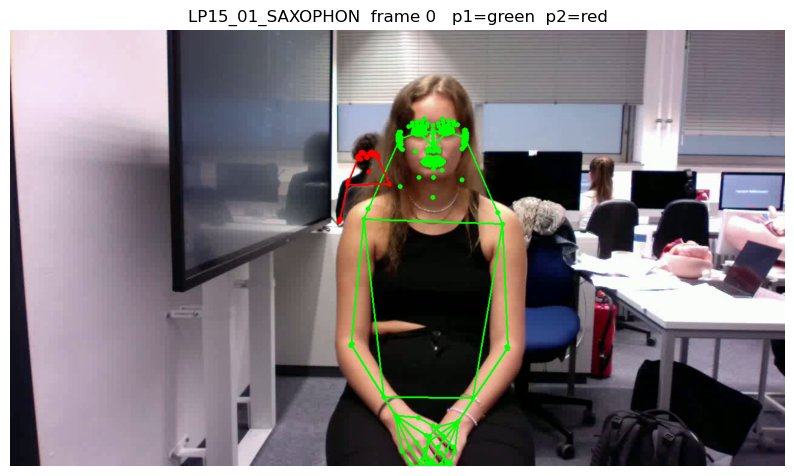

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP15_01_ZEICHNEN\LP15_01_ZEICHNEN_pose.csv
  showing frame 0


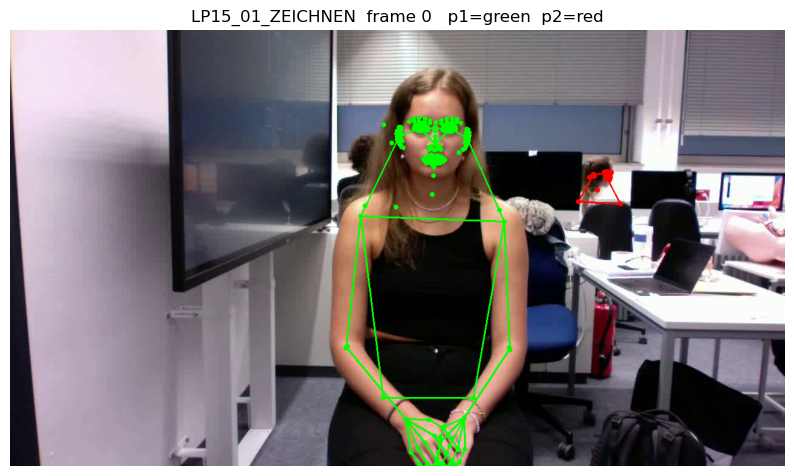

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP17_01_ARGUMENTIEREN\LP17_01_ARGUMENTIEREN_pose.csv
  showing frame 0


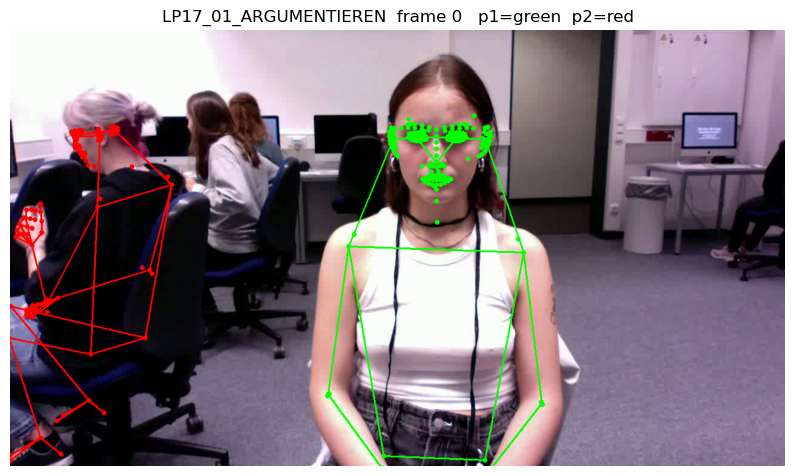

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP17_01_BUCH\LP17_01_BUCH_pose.csv
  showing frame 0


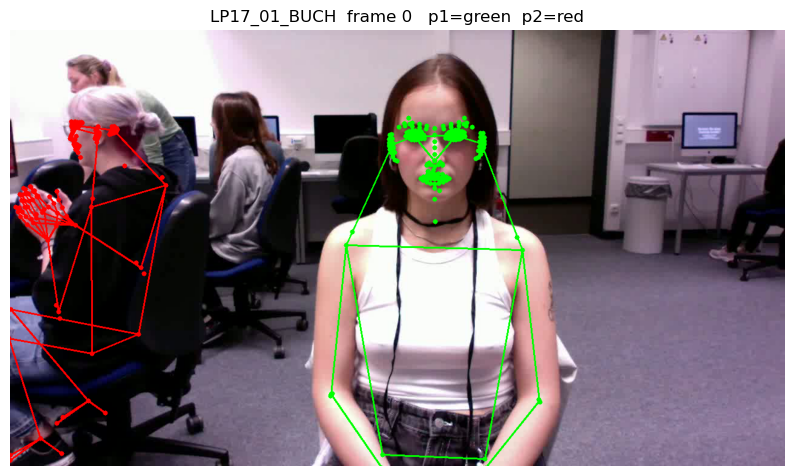

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP17_01_KOERPER WASCHEN\LP17_01_KOERPER WASCHEN_pose.csv
  showing frame 0


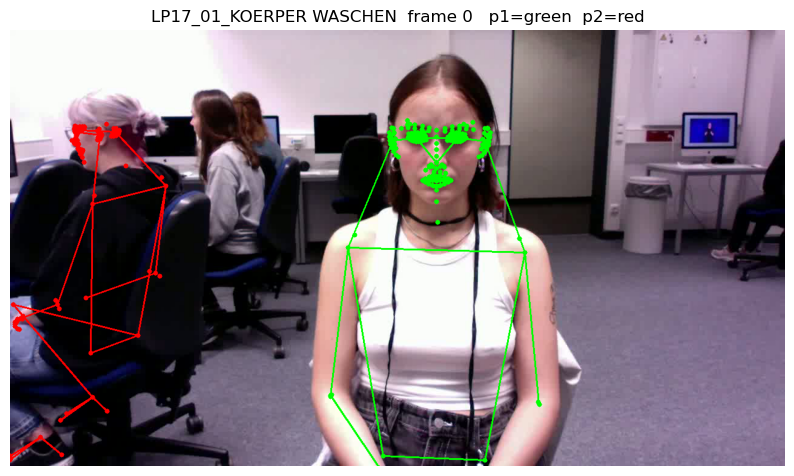

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP17_01_KRANKENWAGEN\LP17_01_KRANKENWAGEN_pose.csv
  showing frame 0


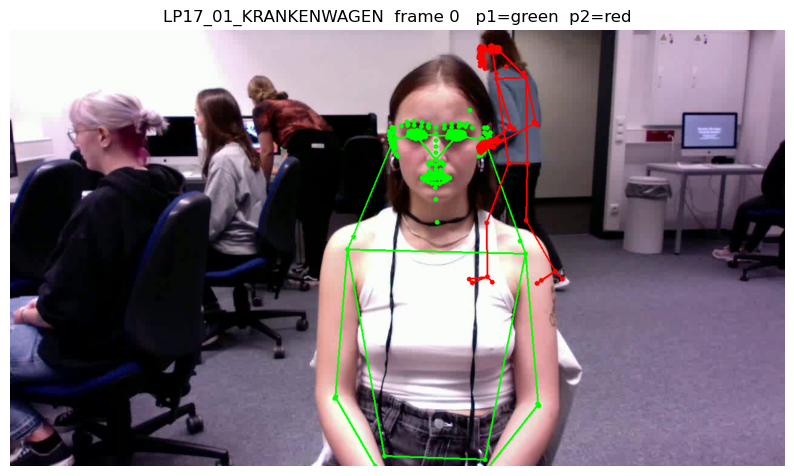

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP17_01_KRIEG\LP17_01_KRIEG_pose.csv
  showing frame 0


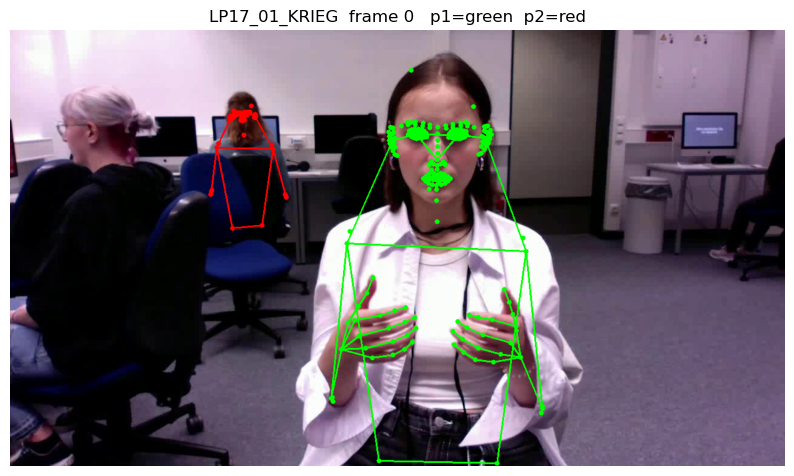

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP17_01_NEUGIERIG\LP17_01_NEUGIERIG_pose.csv
  showing frame 0


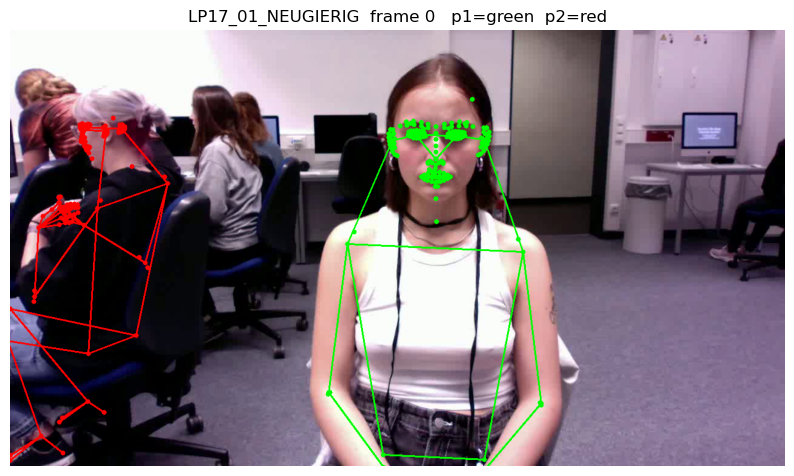

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP17_01_STERBEN\LP17_01_STERBEN_pose.csv
  showing frame 0


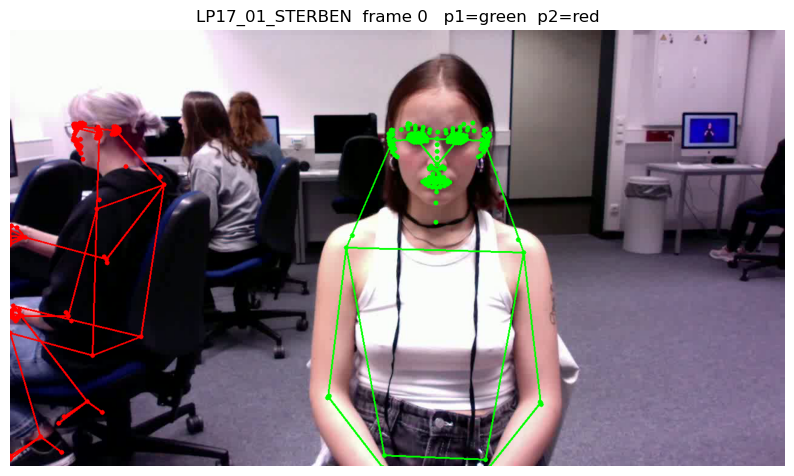

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP17_01_STINKEN\LP17_01_STINKEN_pose.csv
  showing frame 0


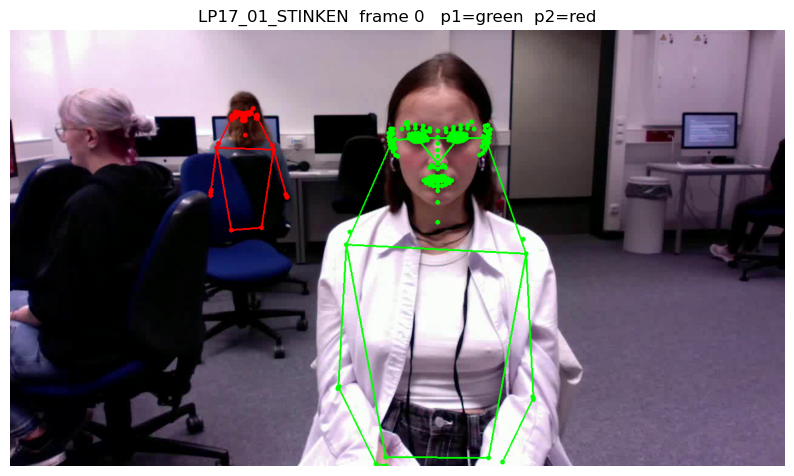

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP17_01_TRINKEN\LP17_01_TRINKEN_pose.csv
  showing frame 0


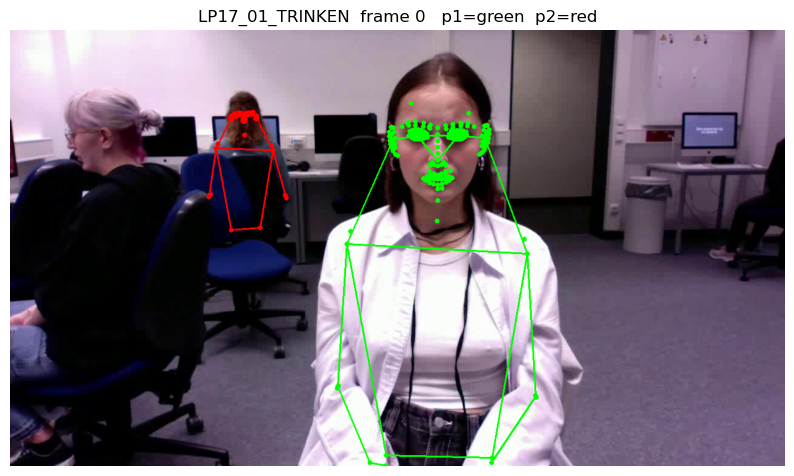

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP17_01_VIDEOSPIEL\LP17_01_VIDEOSPIEL_pose.csv
  showing frame 0


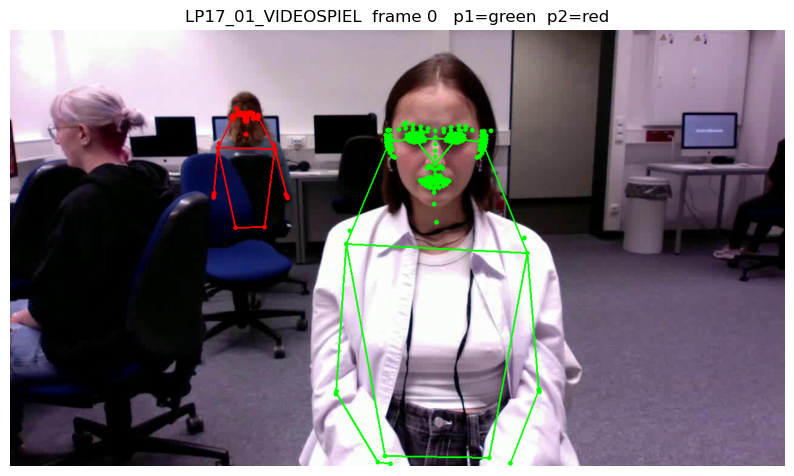

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP17_01_VORSCHLAGEN\LP17_01_VORSCHLAGEN_pose.csv
  showing frame 0


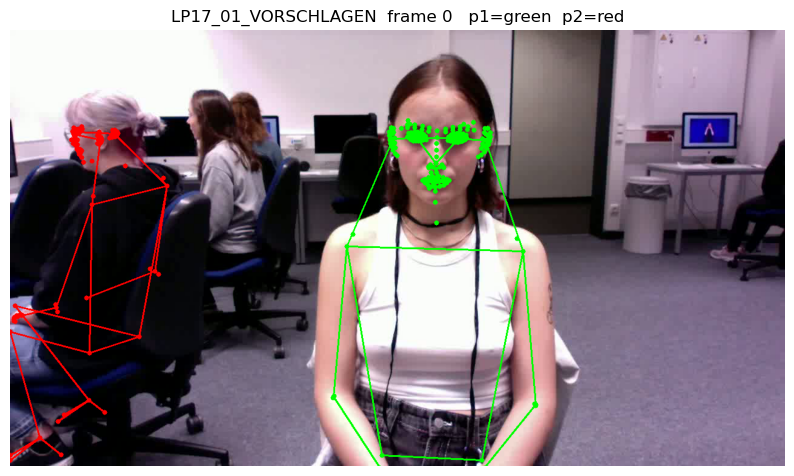

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP18_01_LIPPENSTIFT AUFTRAGEN\LP18_01_LIPPENSTIFT AUFTRAGEN_pose.csv
  showing frame 0


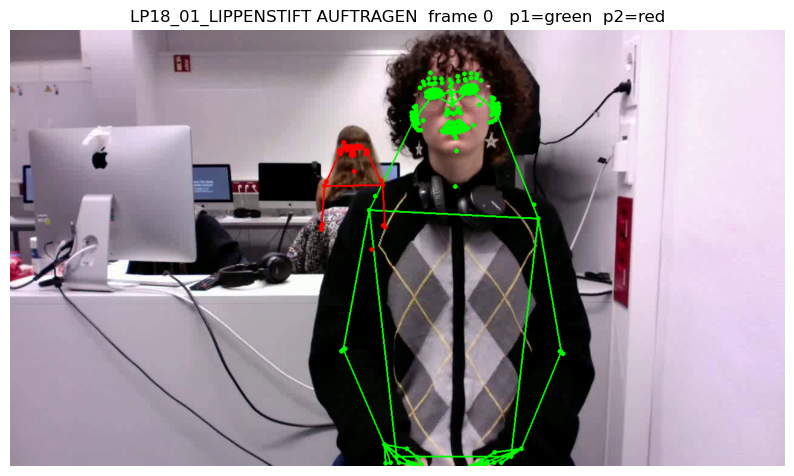

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP18_01_MIXER\LP18_01_MIXER_pose.csv
  showing frame 0


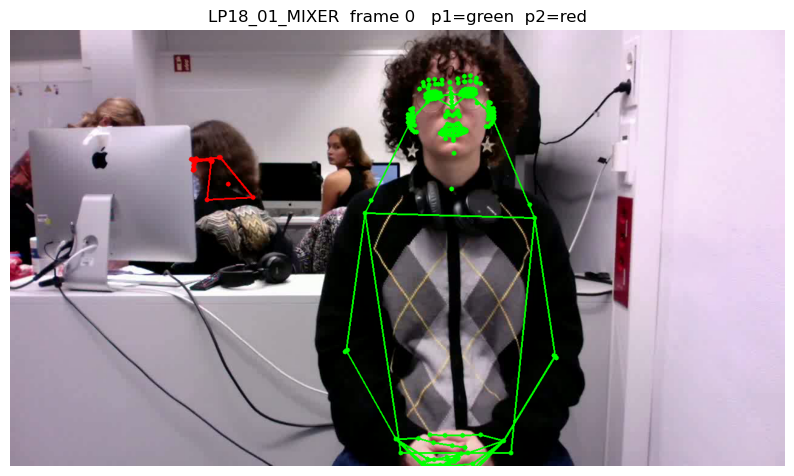

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP18_01_PFEFFER\LP18_01_PFEFFER_pose.csv
  showing frame 0


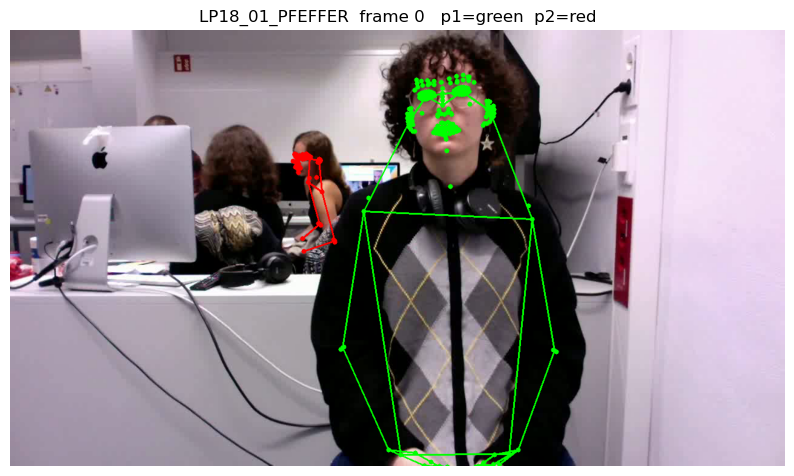

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP18_01_RAUCHEN\LP18_01_RAUCHEN_pose.csv
  showing frame 0


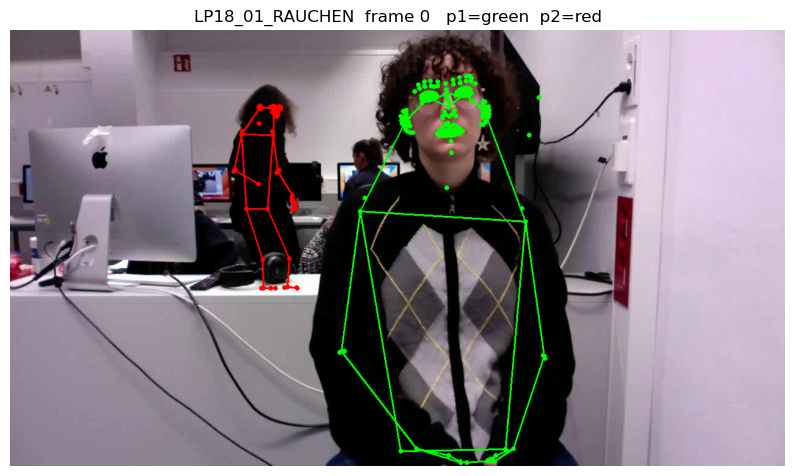

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP18_01_SAGEN\LP18_01_SAGEN_pose.csv
  showing frame 0


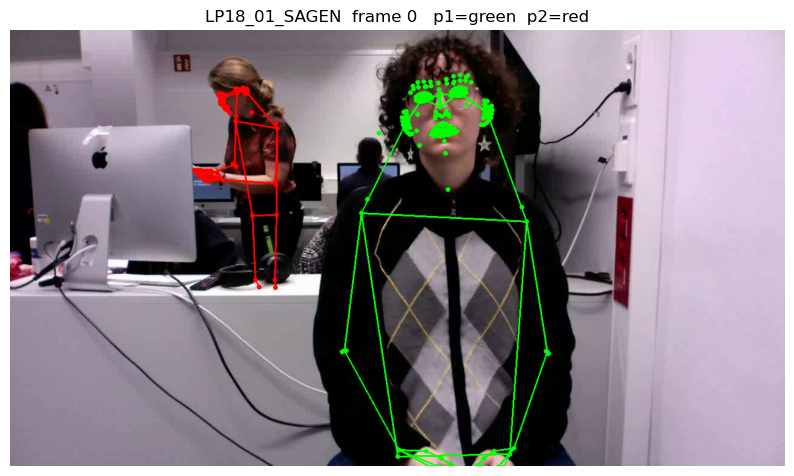

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP18_01_SCHLAFEN\LP18_01_SCHLAFEN_pose.csv
  showing frame 1


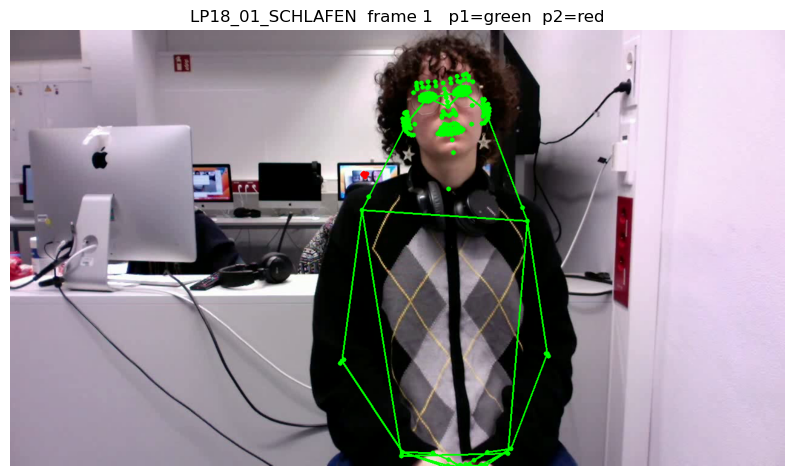

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP18_01_TELEFONANRUF\LP18_01_TELEFONANRUF_pose.csv
  showing frame 0


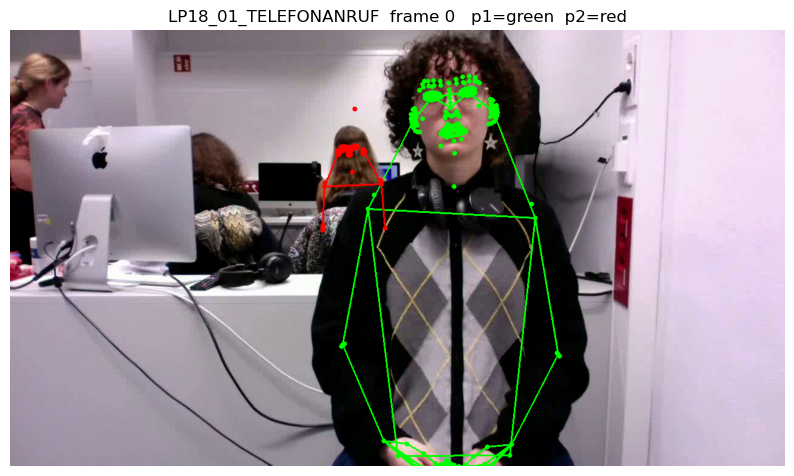

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP18_01_UEBERRASCHT\LP18_01_UEBERRASCHT_pose.csv
  showing frame 0


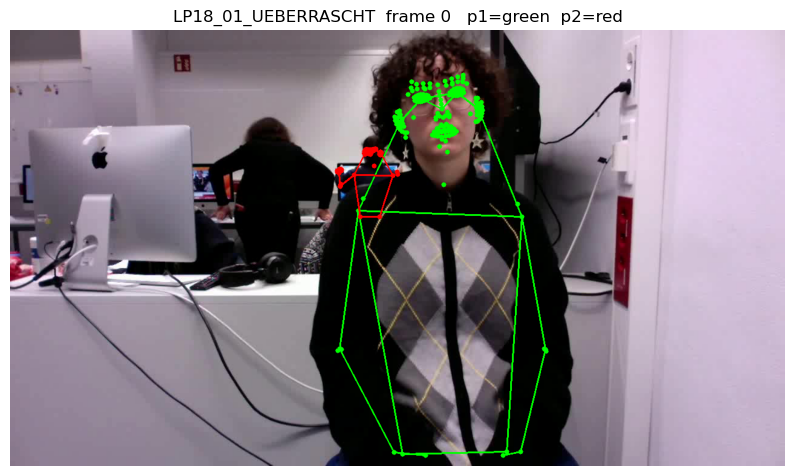

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP18_01_VIDEOSPIEL\LP18_01_VIDEOSPIEL_pose.csv
  showing frame 0


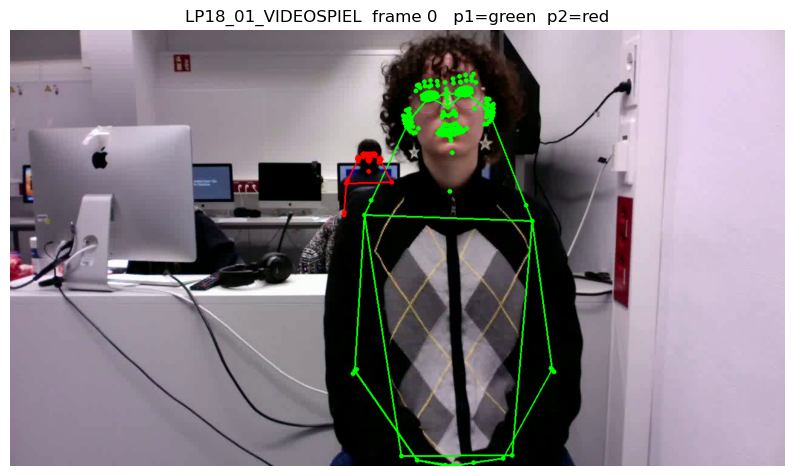

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP18_01_ZENTRAL\LP18_01_ZENTRAL_pose.csv
  showing frame 0


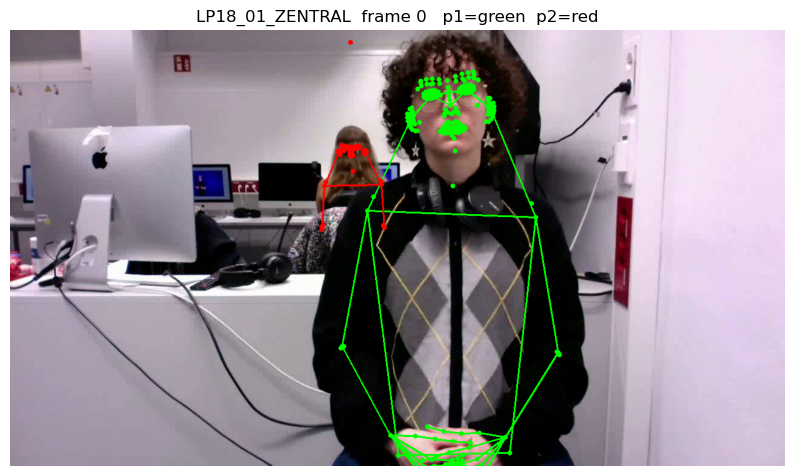

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP19_01_FEUER\LP19_01_FEUER_pose.csv
  showing frame 0


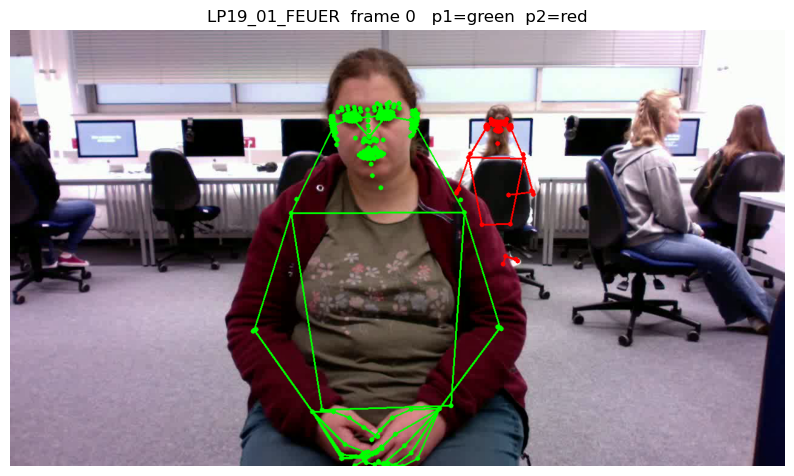

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP19_01_KALT\LP19_01_KALT_pose.csv
  showing frame 0


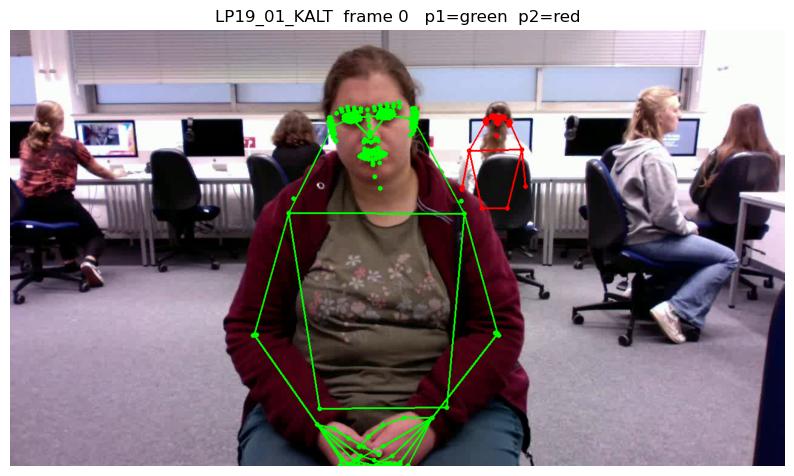

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP19_01_KAUFEN\LP19_01_KAUFEN_pose.csv
  showing frame 0


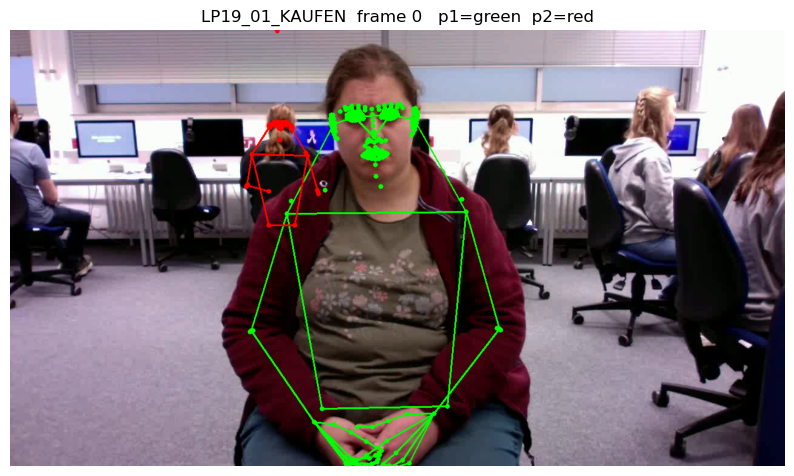

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP19_01_MOND\LP19_01_MOND_pose.csv
  showing frame 0


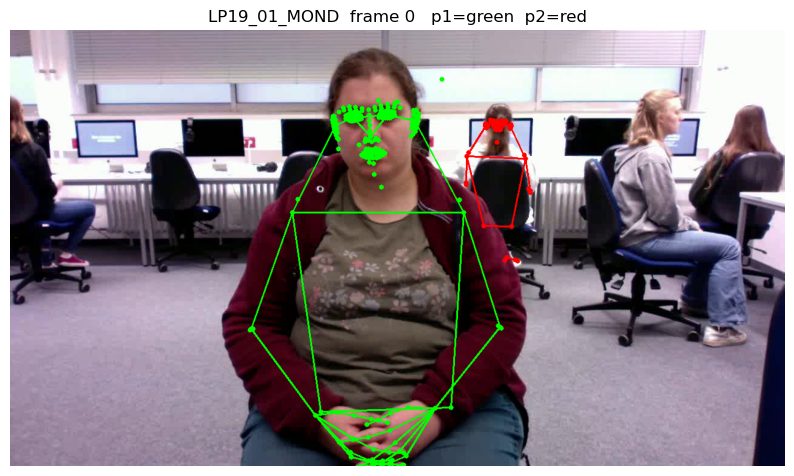

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP19_01_PILOT\LP19_01_PILOT_pose.csv
  showing frame 0


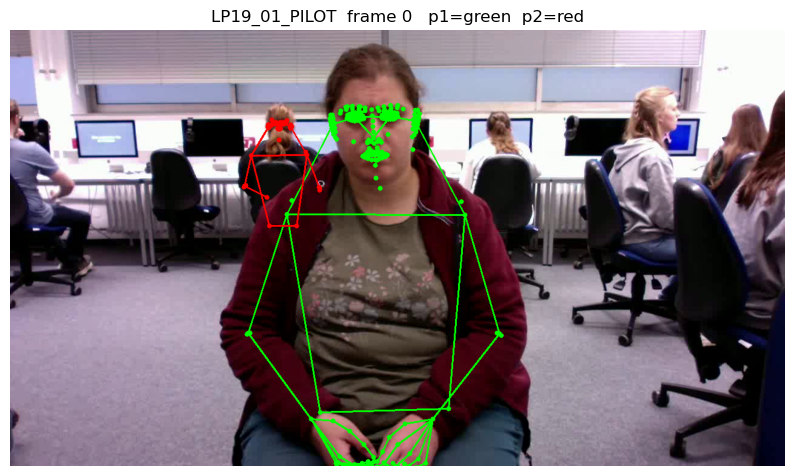

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP19_01_VOGEL\LP19_01_VOGEL_pose.csv
  showing frame 0


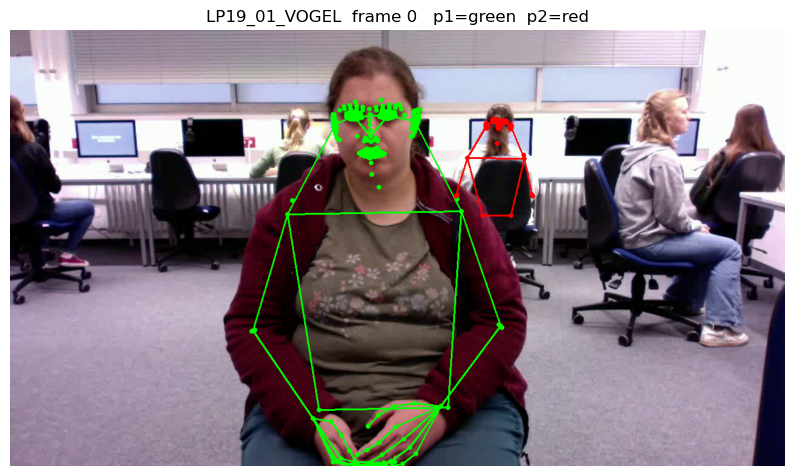

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP19_01_ZEITSCHRIFT\LP19_01_ZEITSCHRIFT_pose.csv
  showing frame 0


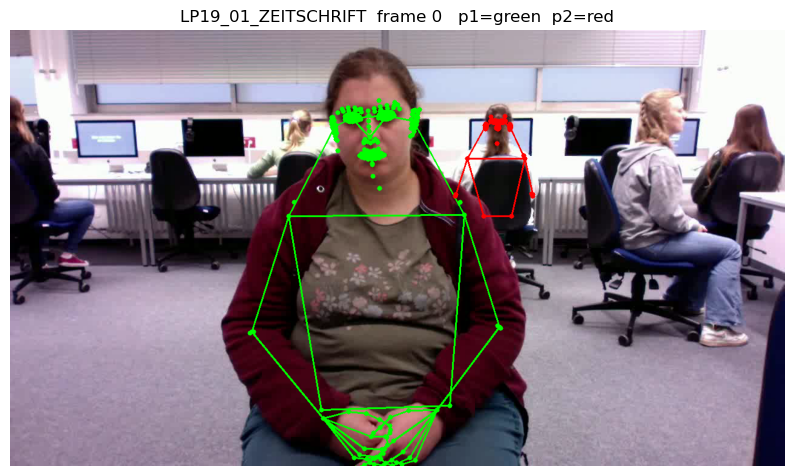

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP22_01_BABY\LP22_01_BABY_pose.csv
  showing frame 0


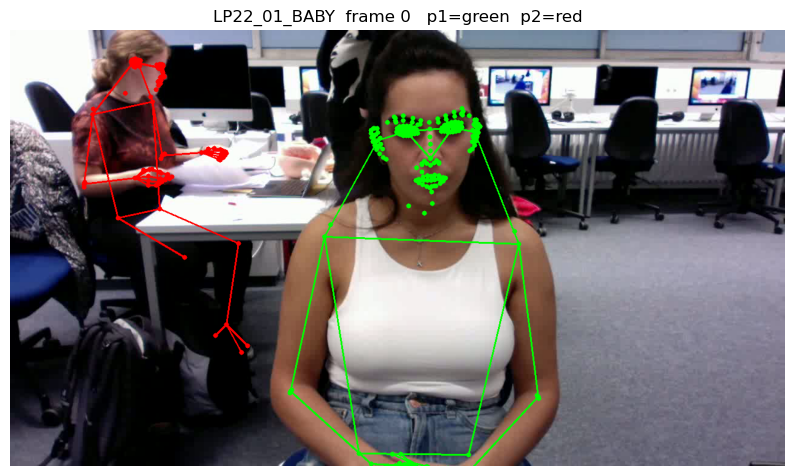

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP22_01_FRAGE\LP22_01_FRAGE_pose.csv
  showing frame 0


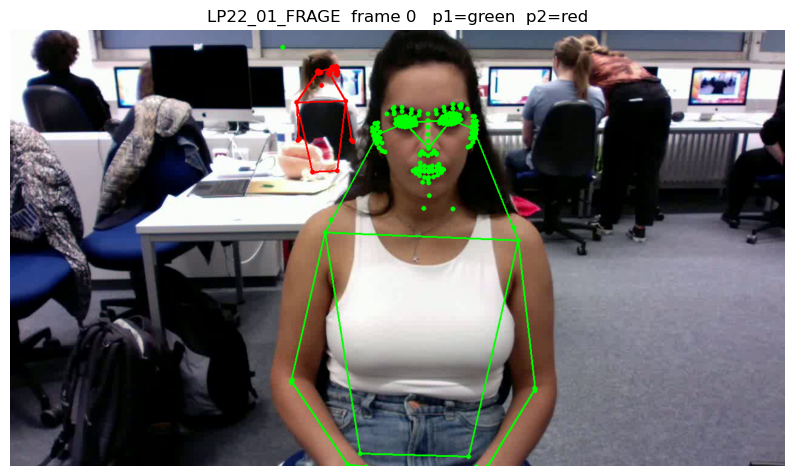

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP22_01_JUCKEN\LP22_01_JUCKEN_pose.csv
  showing frame 0


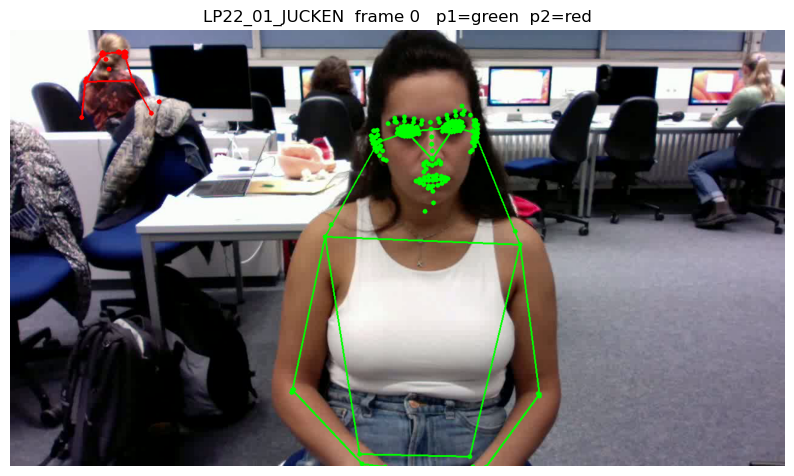

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP22_01_KAUFEN\LP22_01_KAUFEN_pose.csv
  showing frame 0


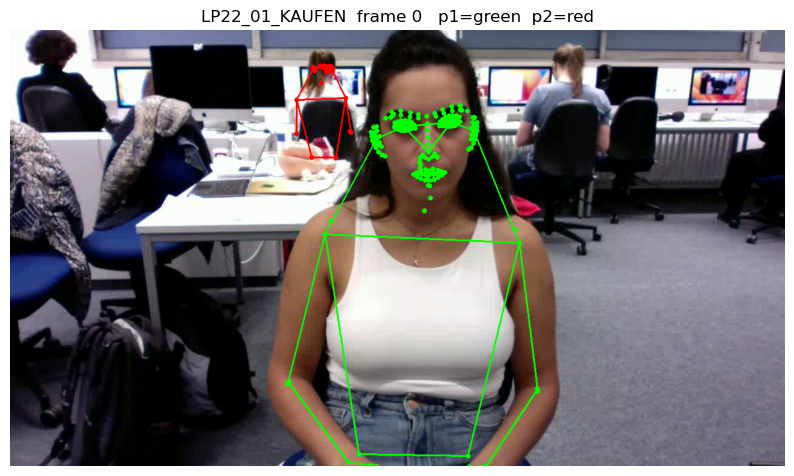

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP22_01_KOMMUNIKATION\LP22_01_KOMMUNIKATION_pose.csv
  showing frame 0


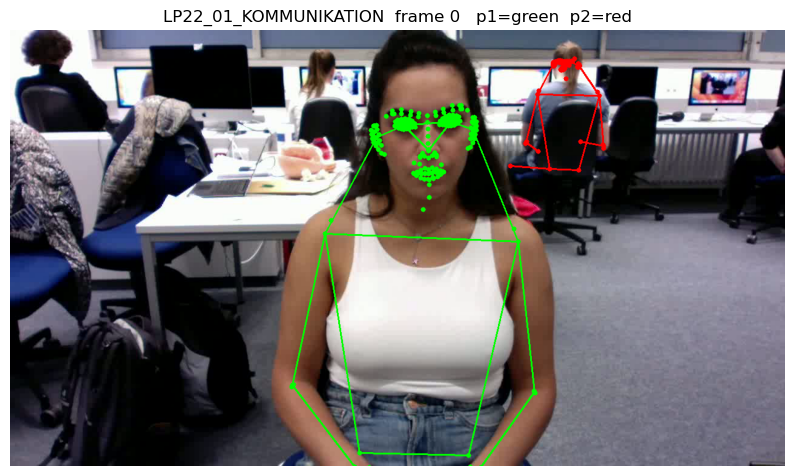

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP22_01_MOND\LP22_01_MOND_pose.csv
  showing frame 0


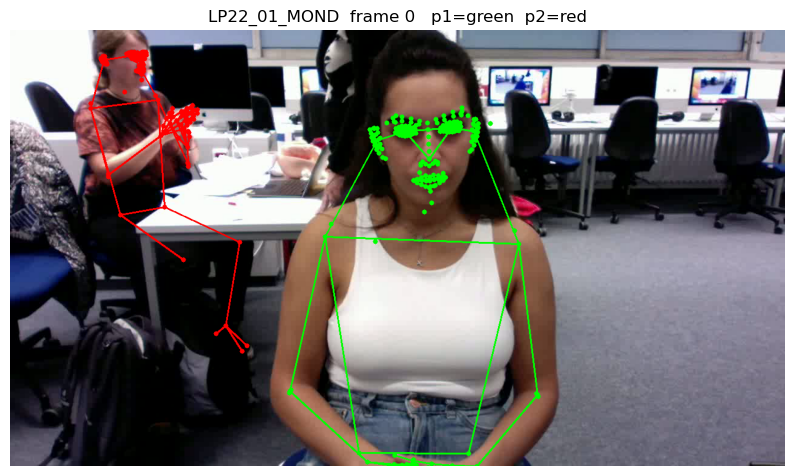

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP22_01_NEUGIERIG\LP22_01_NEUGIERIG_pose.csv
  showing frame 0


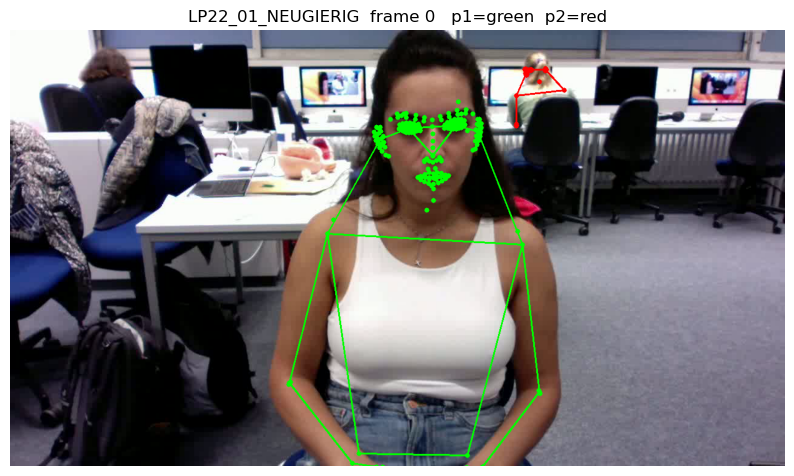

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP22_01_PFANNE\LP22_01_PFANNE_pose.csv
  showing frame 0


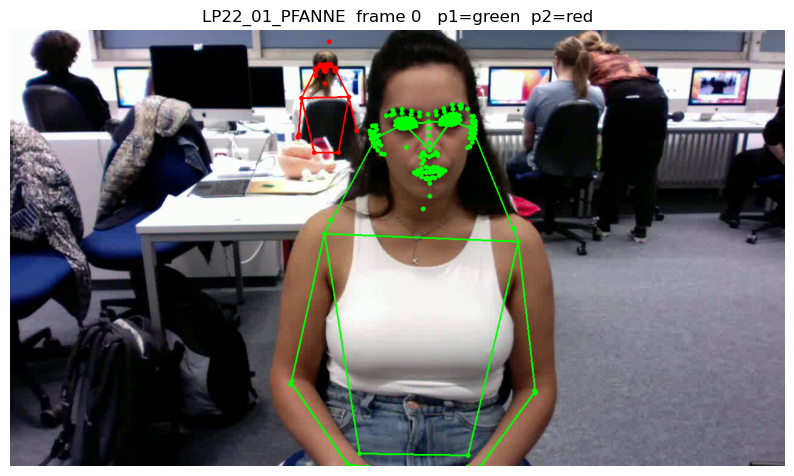

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP22_01_SCHAMPOO\LP22_01_SCHAMPOO_pose.csv
  showing frame 0


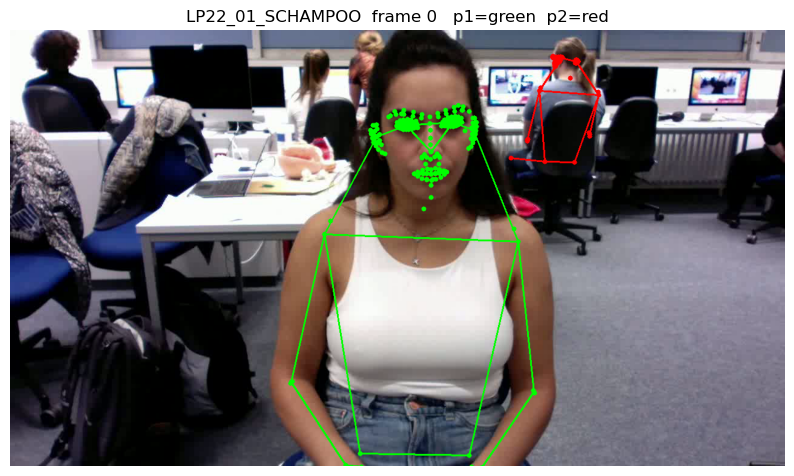

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP25_01_BASKETBALL\LP25_01_BASKETBALL_pose.csv
  showing frame 0


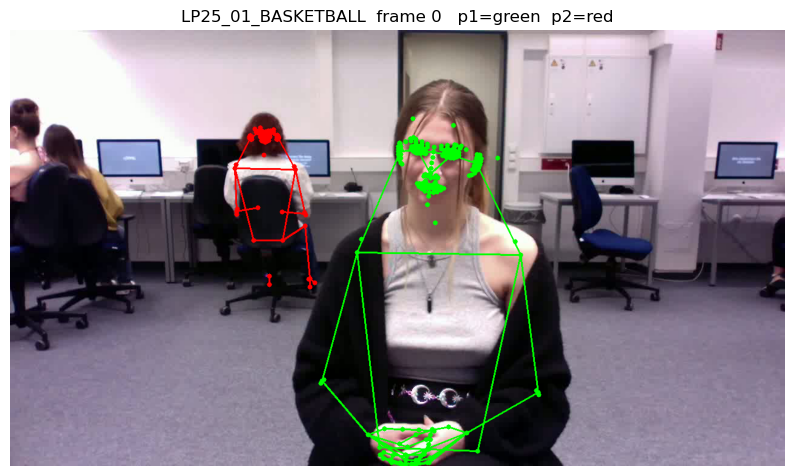

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP25_01_EGAL\LP25_01_EGAL_pose.csv
  showing frame 0


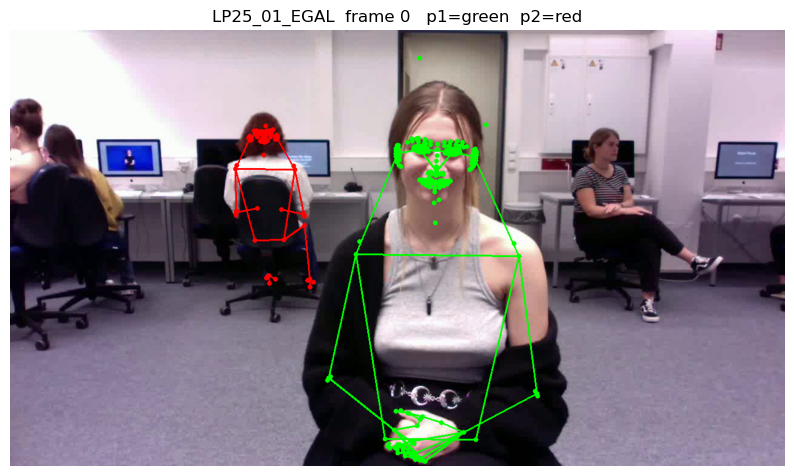

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP25_01_FRAGE\LP25_01_FRAGE_pose.csv
  showing frame 0


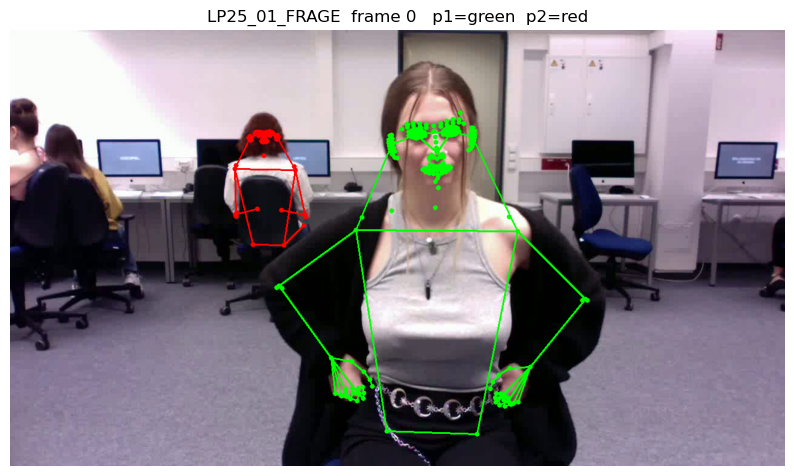

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP25_01_MUECKE\LP25_01_MUECKE_pose.csv
  showing frame 0


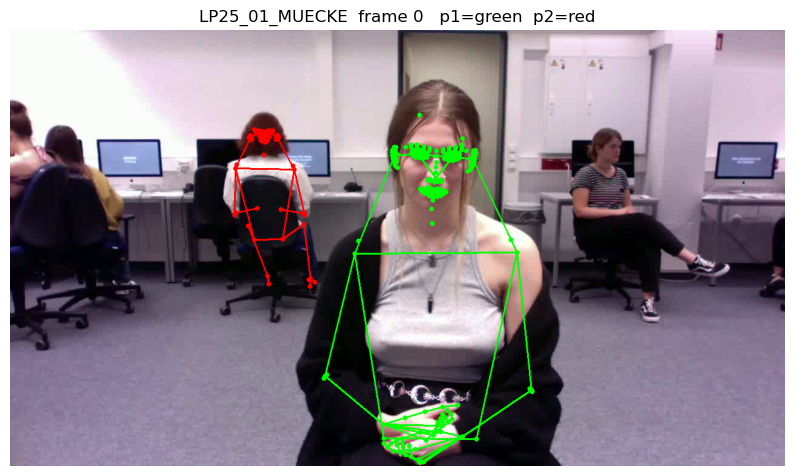

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP25_01_NASE\LP25_01_NASE_pose.csv
  showing frame 0


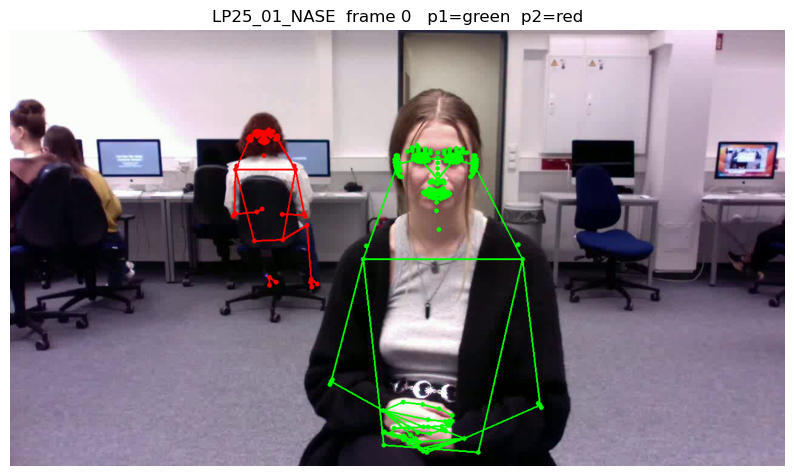

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP25_01_SAEGE\LP25_01_SAEGE_pose.csv
  showing frame 0


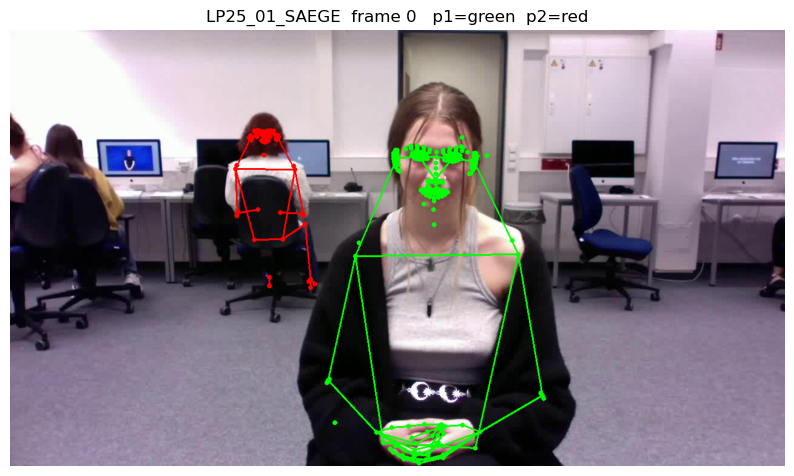

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP25_01_TREPPE\LP25_01_TREPPE_pose.csv
  showing frame 0


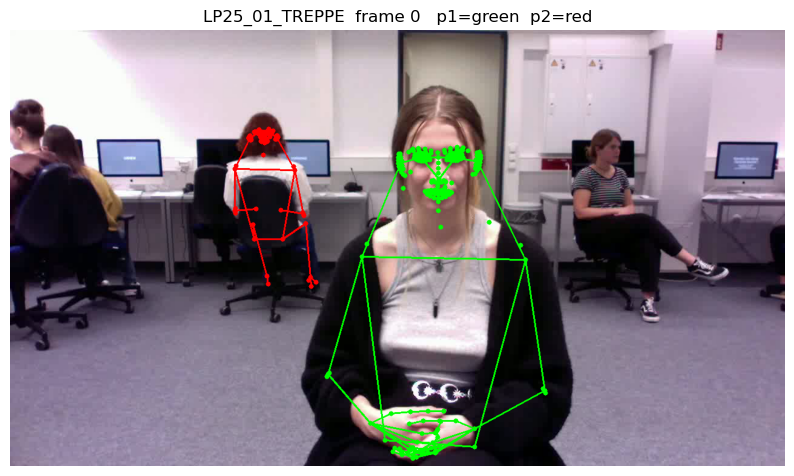

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP25_01_VERHEIRATET\LP25_01_VERHEIRATET_pose.csv
  showing frame 0


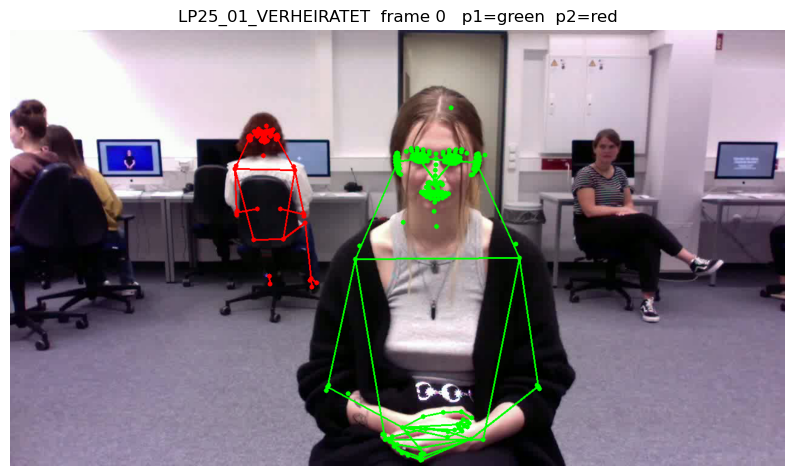

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP25_01_VIEL\LP25_01_VIEL_pose.csv
  showing frame 0


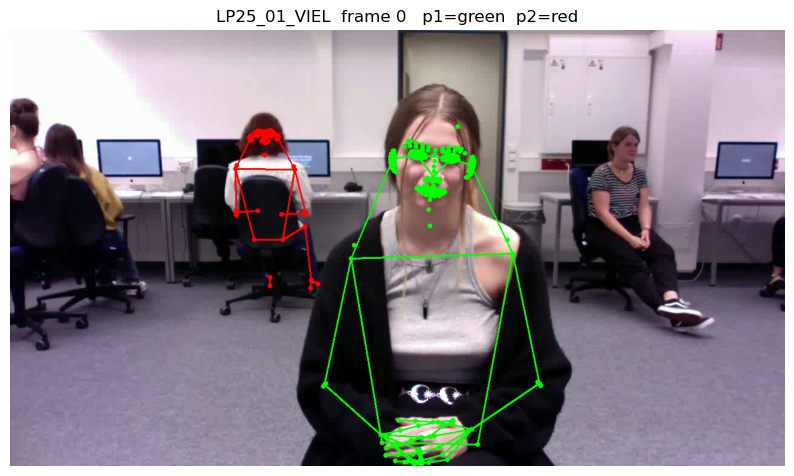

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP25_01_VORSCHLAGEN\LP25_01_VORSCHLAGEN_pose.csv
  showing frame 0


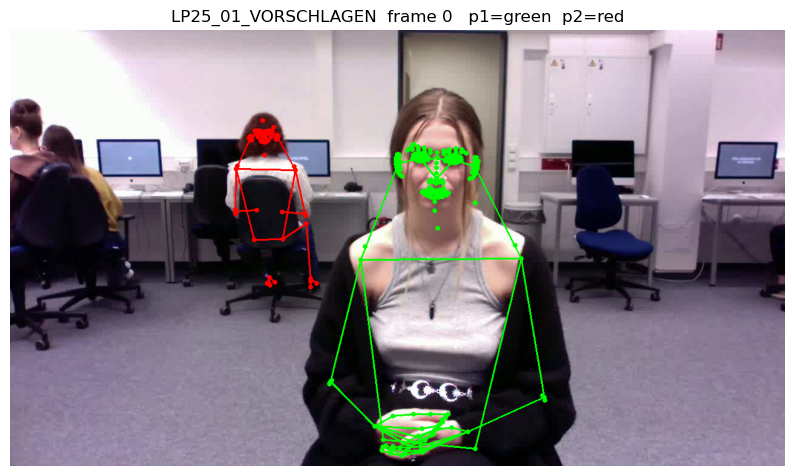

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP28_01_BASKETBALL\LP28_01_BASKETBALL_pose.csv
  showing frame 0


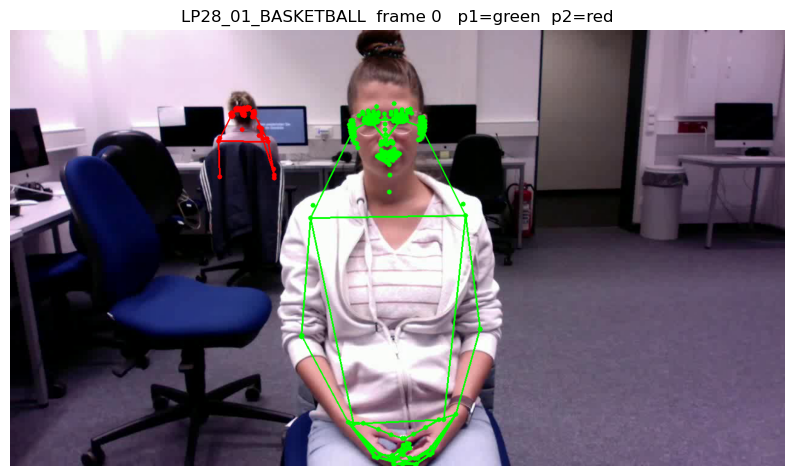

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP28_01_BEZAHLEN\LP28_01_BEZAHLEN_pose.csv
  showing frame 0


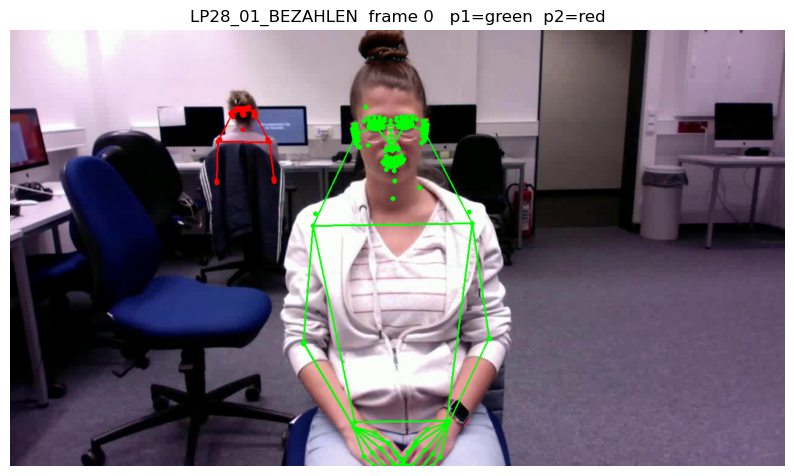

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP28_01_BILLIARD\LP28_01_BILLIARD_pose.csv
  showing frame 0


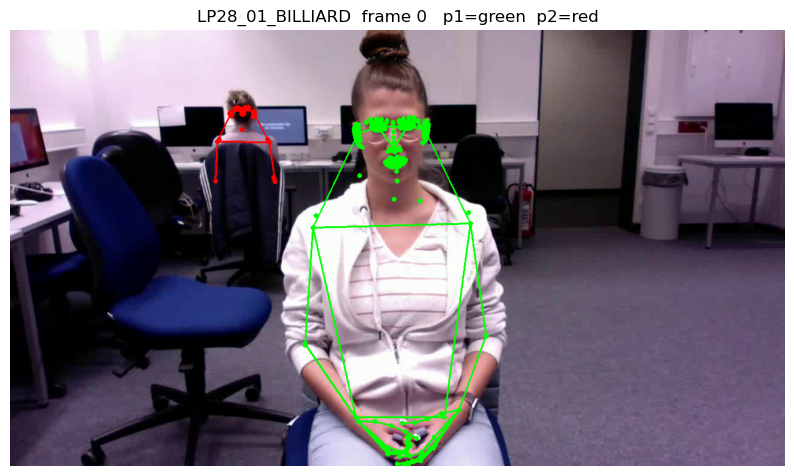

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP28_01_ESSEN\LP28_01_ESSEN_pose.csv
  showing frame 0


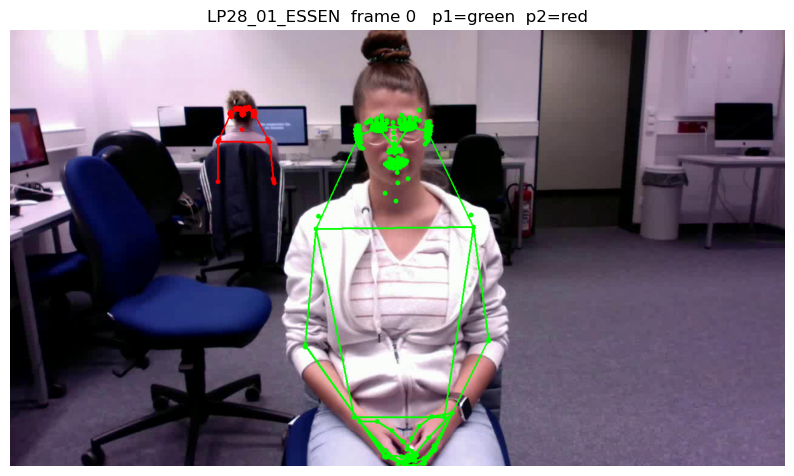

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP28_01_HANDY\LP28_01_HANDY_pose.csv
  showing frame 0


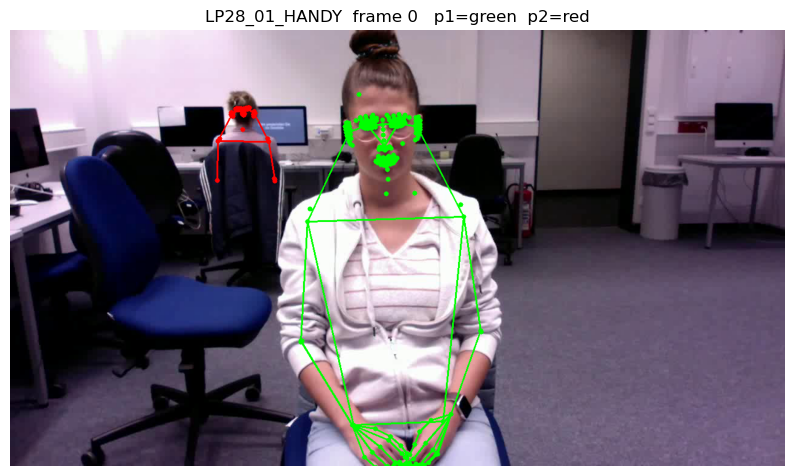

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP28_01_KALT\LP28_01_KALT_pose.csv
  showing frame 0


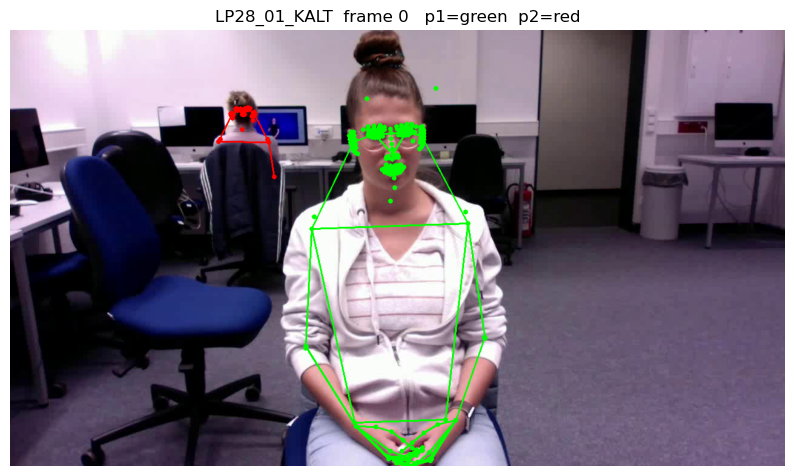

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP28_01_LIPPENSTIFT AUFTRAGEN\LP28_01_LIPPENSTIFT AUFTRAGEN_pose.csv
  showing frame 0


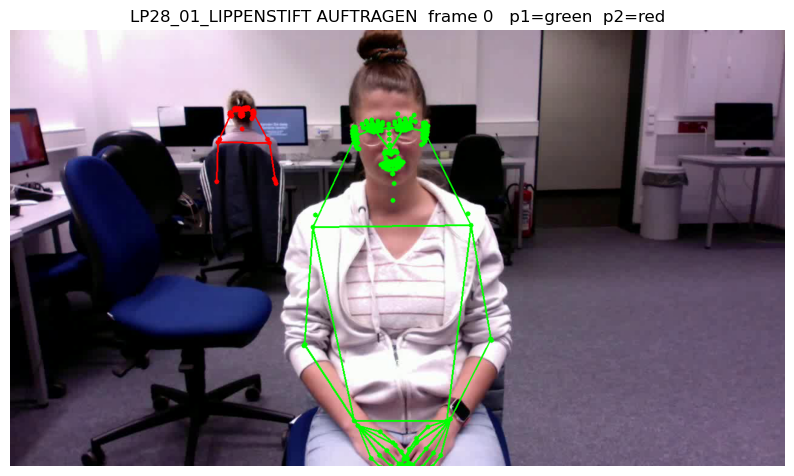

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP28_01_PFANNE\LP28_01_PFANNE_pose.csv
  showing frame 0


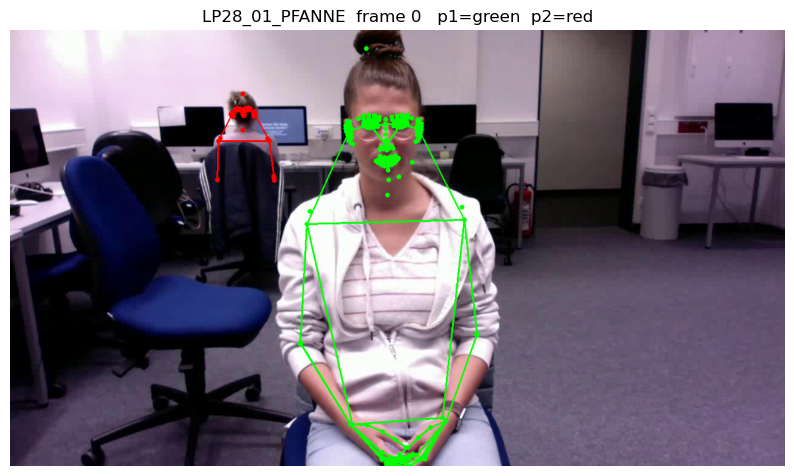

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP28_01_STECKER\LP28_01_STECKER_pose.csv
  showing frame 0


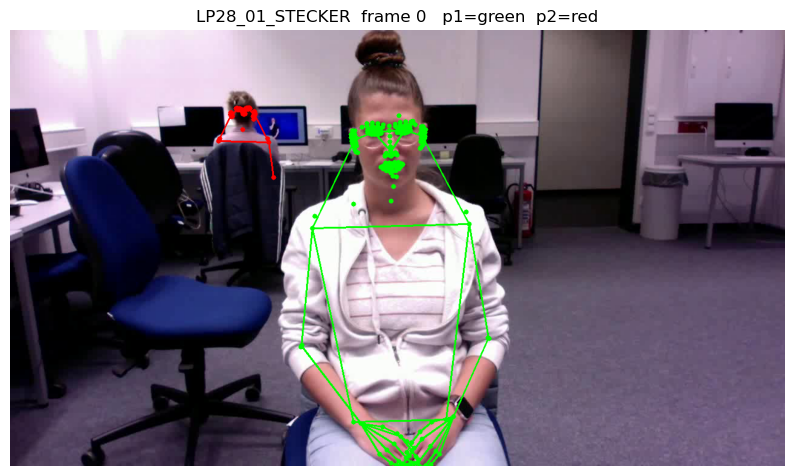

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP28_01_VIEL\LP28_01_VIEL_pose.csv
  showing frame 0


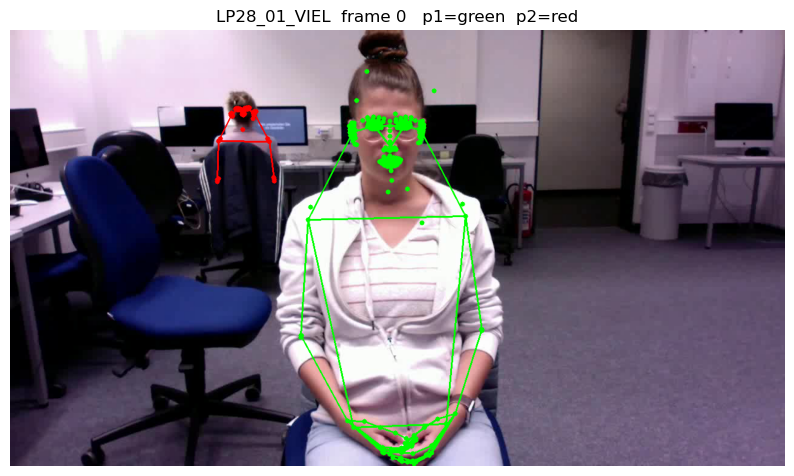

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP28_01_VORSCHLAGEN\LP28_01_VORSCHLAGEN_pose.csv
  showing frame 0


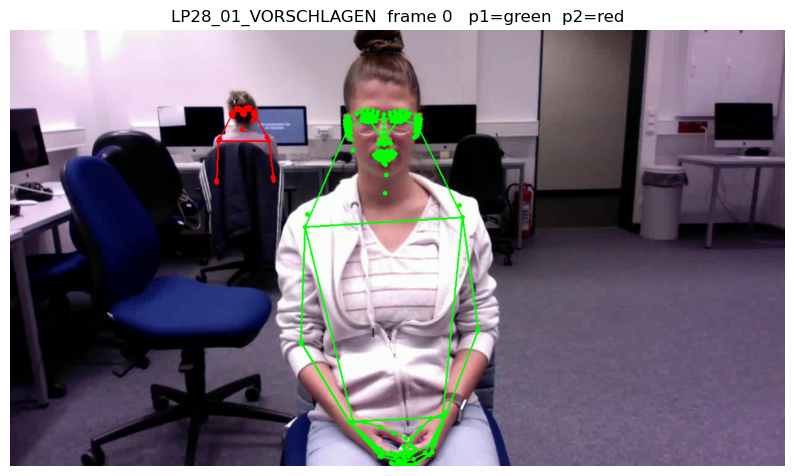

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP29_01_BRIEF\LP29_01_BRIEF_pose.csv
  showing frame 3


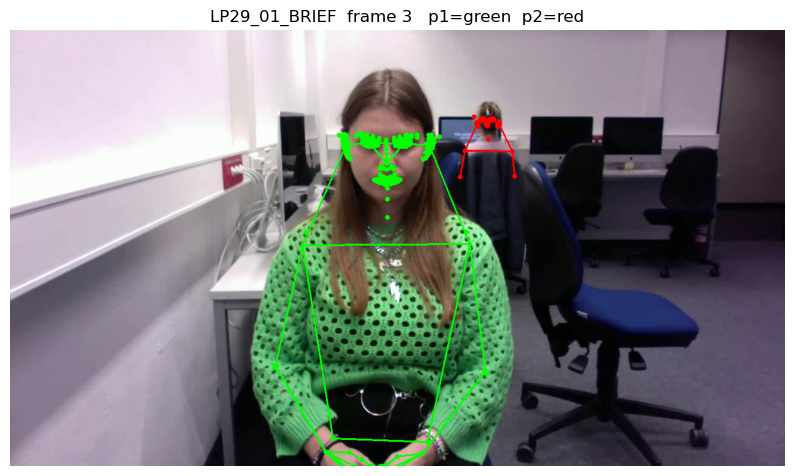

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP29_01_FEUER\LP29_01_FEUER_pose.csv
  showing frame 0


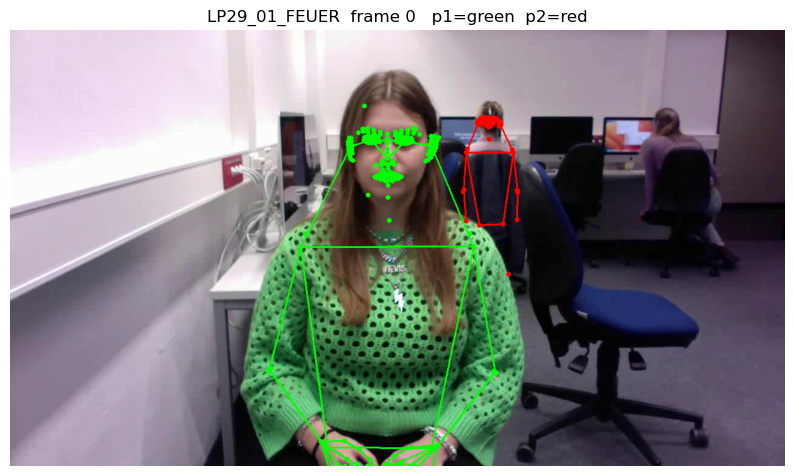

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP29_01_KOFFER\LP29_01_KOFFER_pose.csv
  showing frame 0


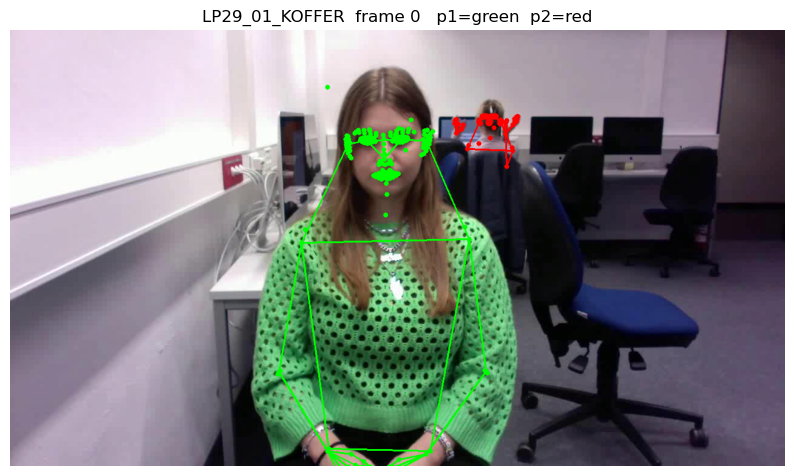

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP29_01_LAPTOP\LP29_01_LAPTOP_pose.csv
  showing frame 0


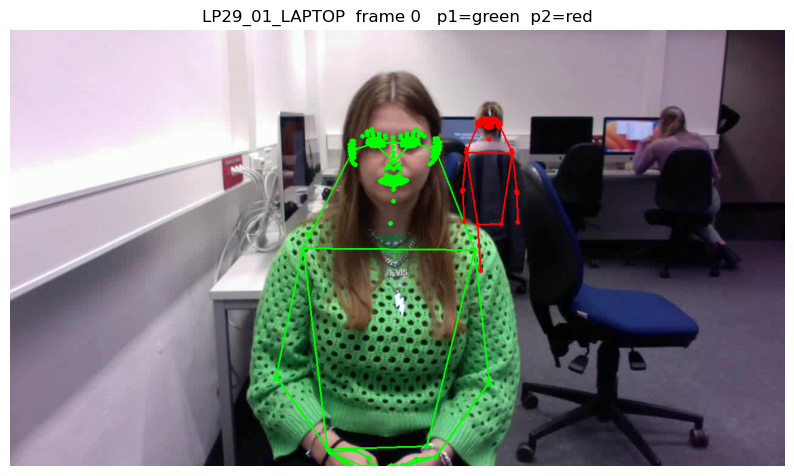

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP29_01_PARTY\LP29_01_PARTY_pose.csv
  showing frame 0


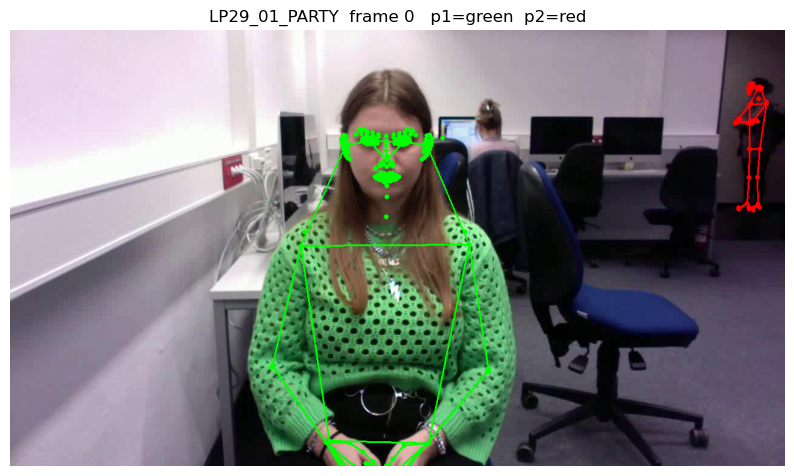

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP29_01_SCHRAUBENZIEHER\LP29_01_SCHRAUBENZIEHER_pose.csv
  showing frame 1


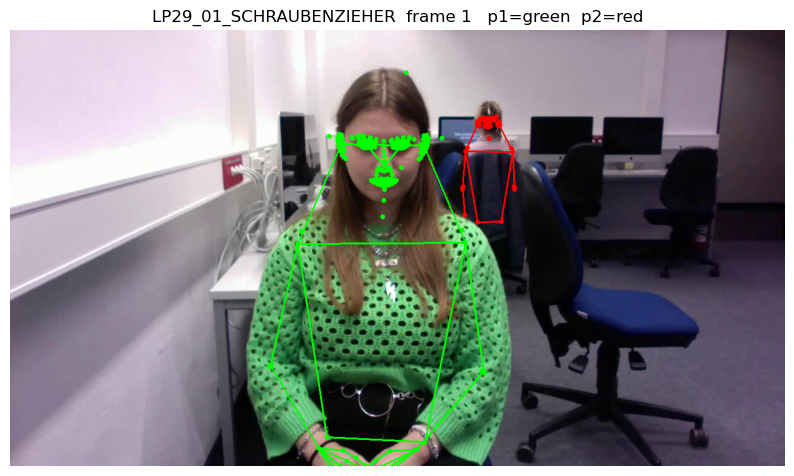

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP29_01_TASCHENRECHNER\LP29_01_TASCHENRECHNER_pose.csv
  showing frame 0


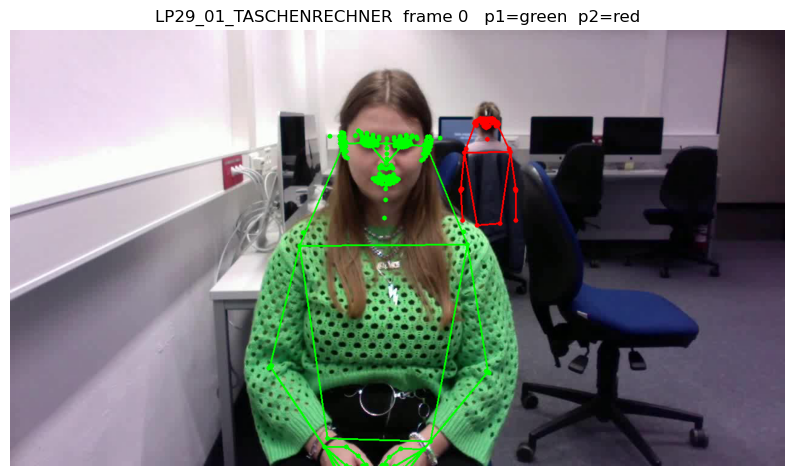

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP29_01_TENNIS\LP29_01_TENNIS_pose.csv
  showing frame 0


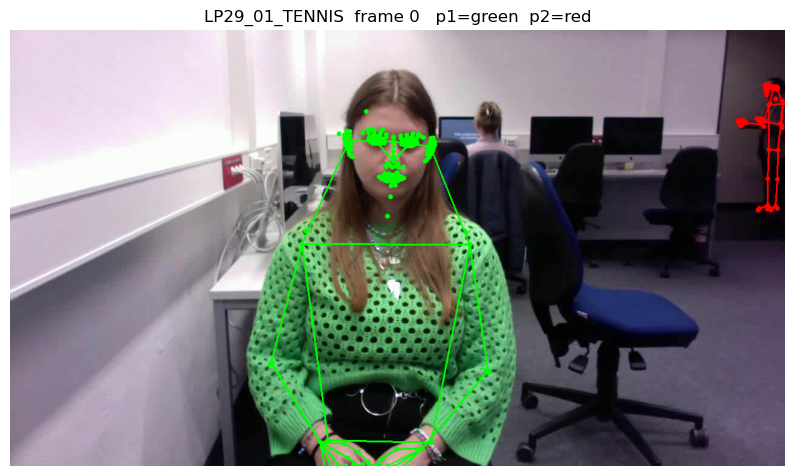

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP29_01_TRETEN\LP29_01_TRETEN_pose.csv
  showing frame 0


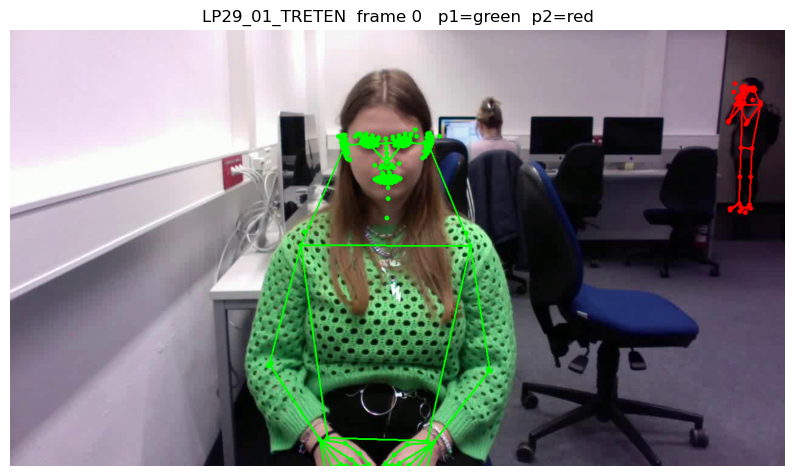

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP29_01_TRINKWASSER\LP29_01_TRINKWASSER_pose.csv
  showing frame 0


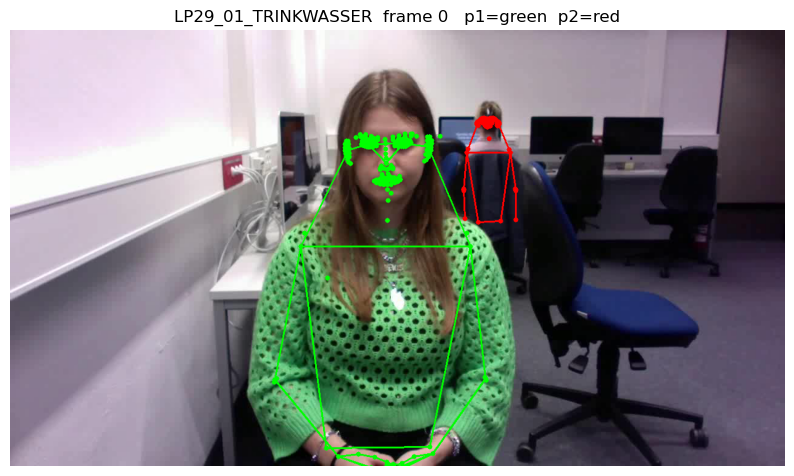

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP29_01_ZEIT\LP29_01_ZEIT_pose.csv
  showing frame 0


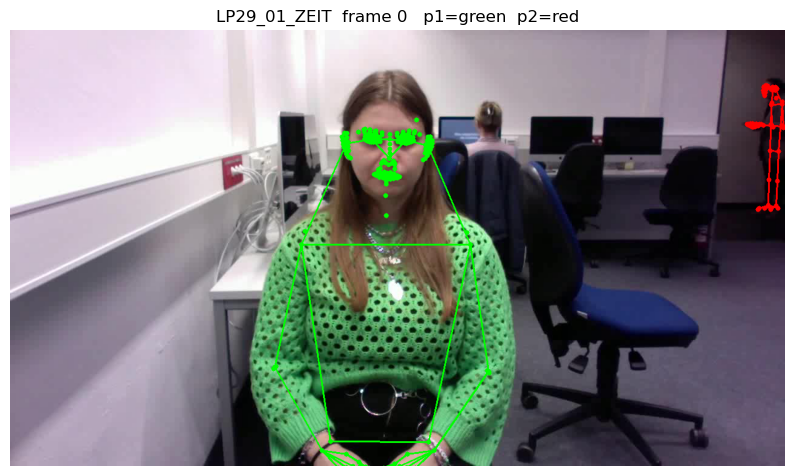

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP30_01_BEOBACHTEN\LP30_01_BEOBACHTEN_pose.csv
  showing frame 10


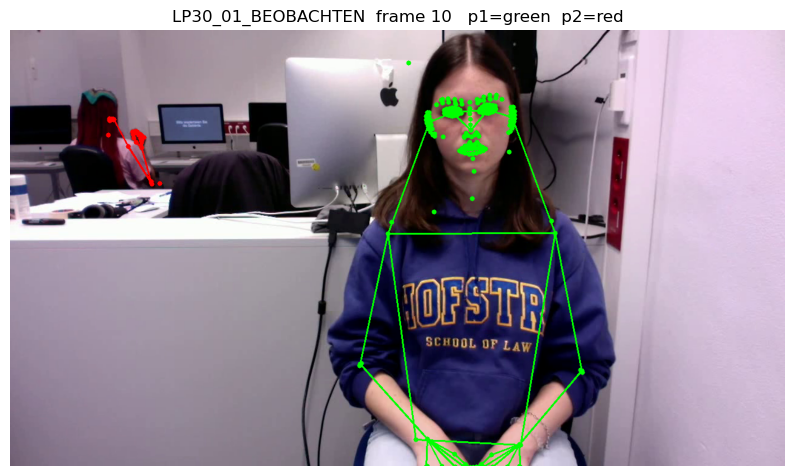

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP30_01_BODEN\LP30_01_BODEN_pose.csv
  showing frame 35


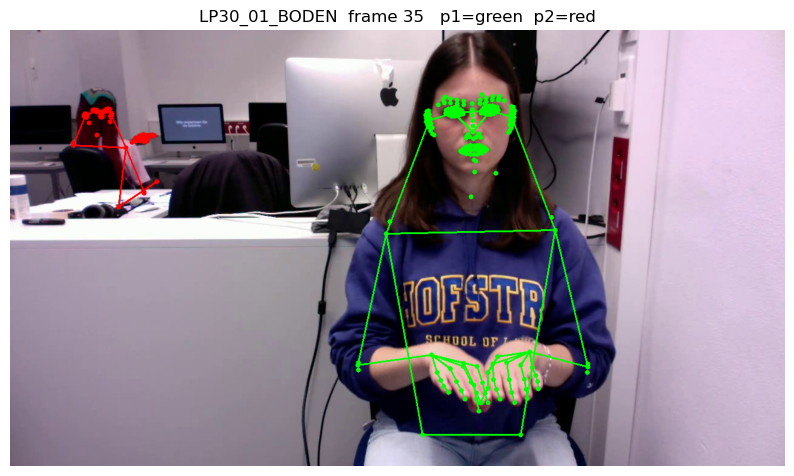

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP30_01_BRECHEN\LP30_01_BRECHEN_pose.csv
  showing frame 60


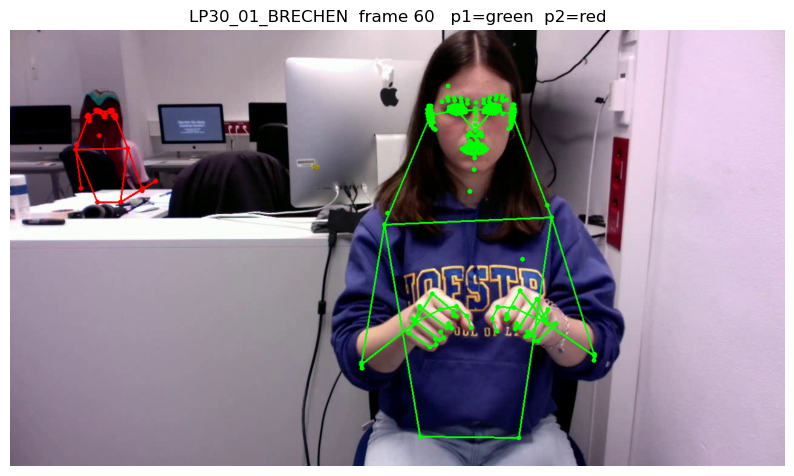

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP30_01_DUSCHEN\LP30_01_DUSCHEN_pose.csv
  showing frame 0


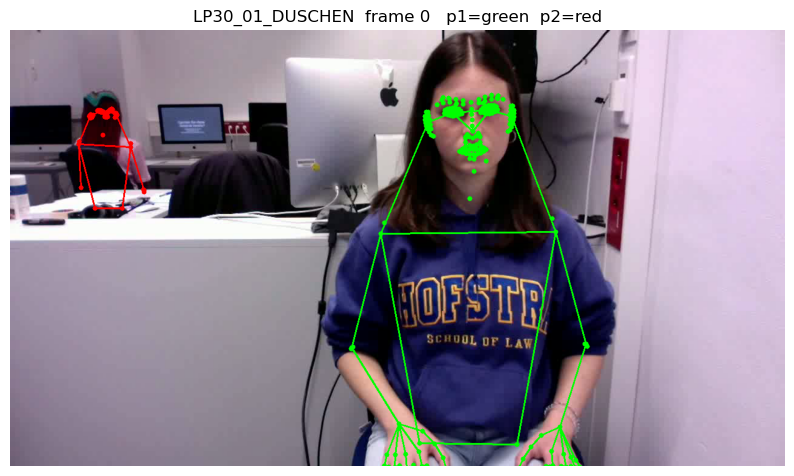

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP30_01_HEISS\LP30_01_HEISS_pose.csv
  showing frame 0


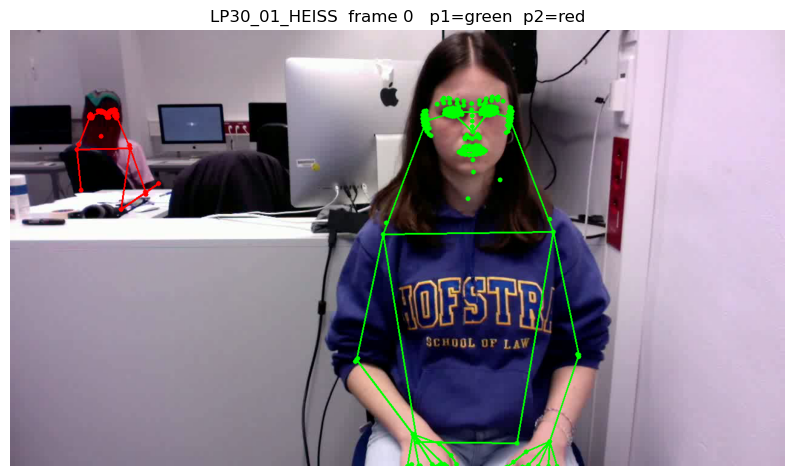

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP30_01_JONGLIEREN\LP30_01_JONGLIEREN_pose.csv
  showing frame 0


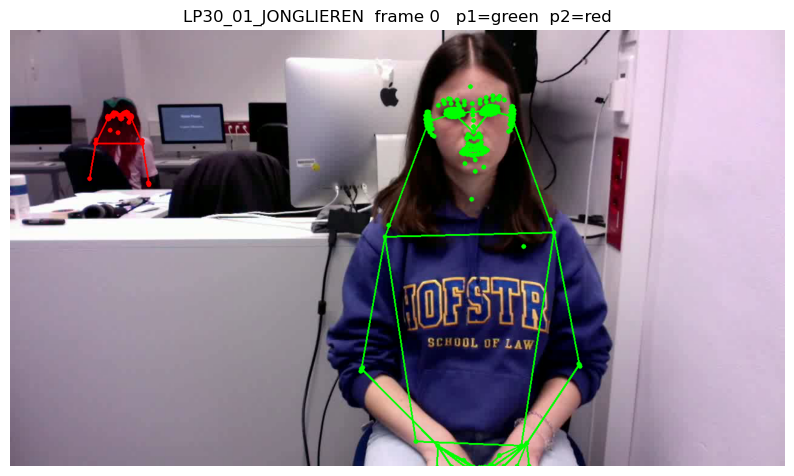

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP30_01_KLEID\LP30_01_KLEID_pose.csv
  showing frame 0


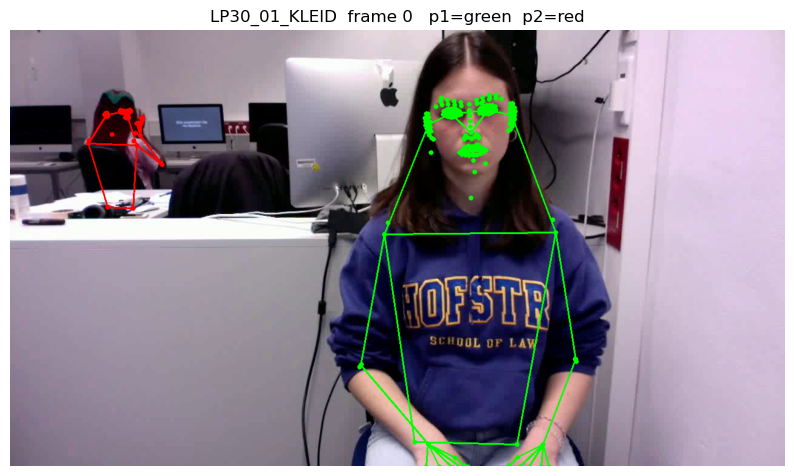

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP30_01_KLEIDUNG\LP30_01_KLEIDUNG_pose.csv
  showing frame 0


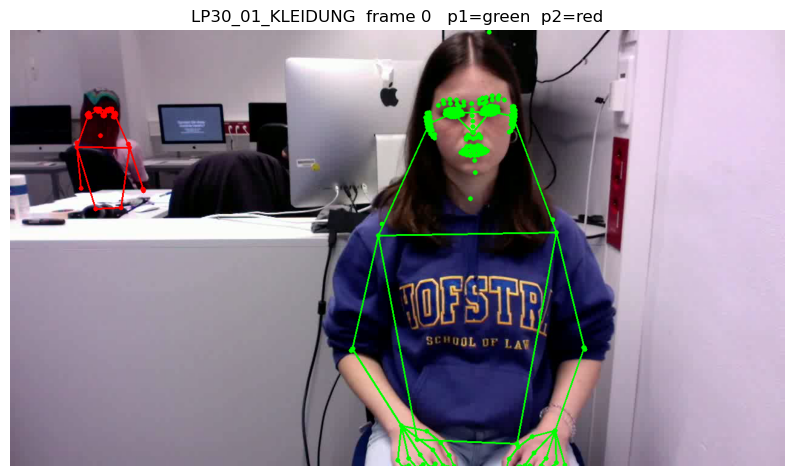

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP30_01_KRANKENWAGEN\LP30_01_KRANKENWAGEN_pose.csv
  showing frame 0


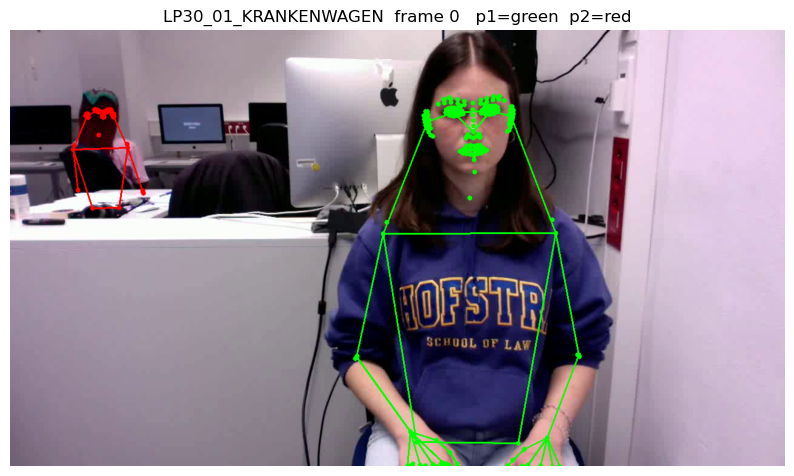

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP30_01_MASSAGE\LP30_01_MASSAGE_pose.csv
  showing frame 1


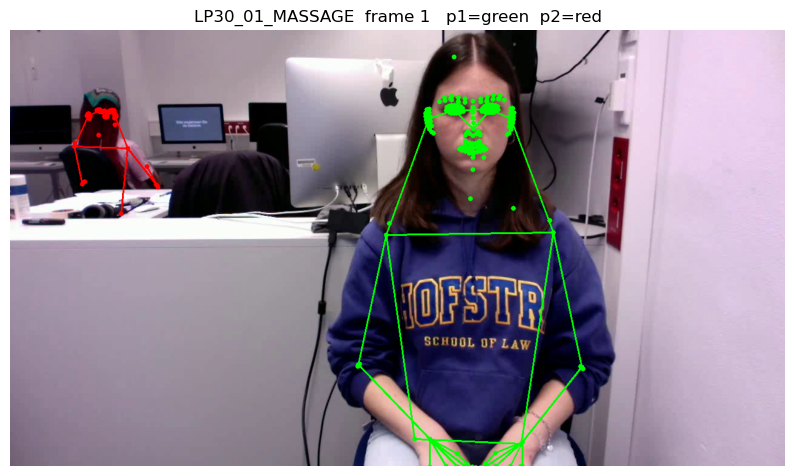

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP30_01_PFEFFER\LP30_01_PFEFFER_pose.csv
  showing frame 0


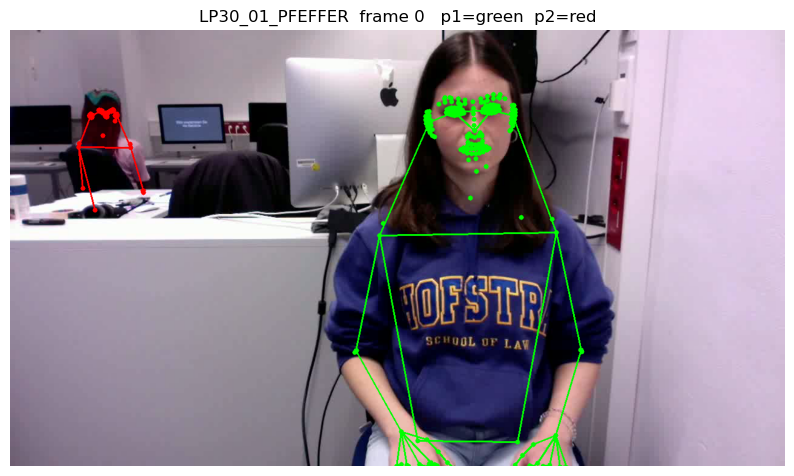

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP33_01_ABHOLEN\LP33_01_ABHOLEN_pose.csv
  showing frame 0


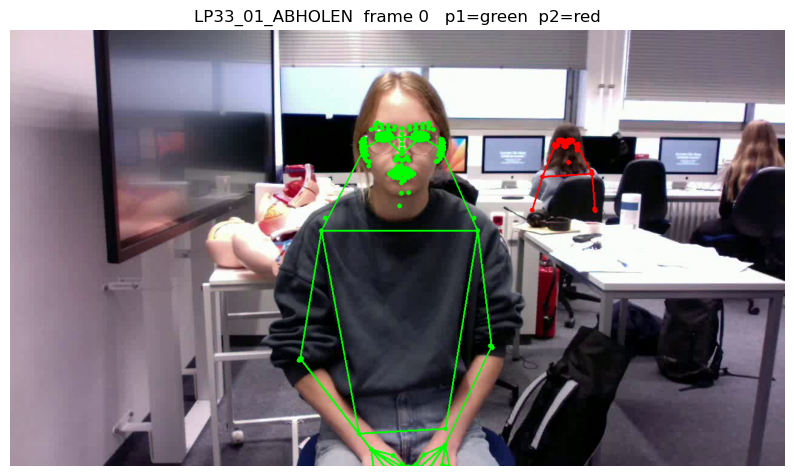

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP33_01_AUSSCHALTEN\LP33_01_AUSSCHALTEN_pose.csv
  showing frame 0


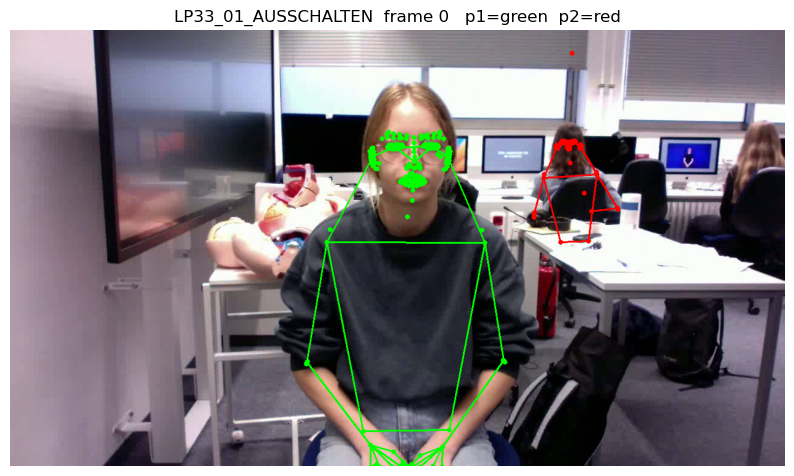

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP33_01_HEISS\LP33_01_HEISS_pose.csv
  showing frame 0


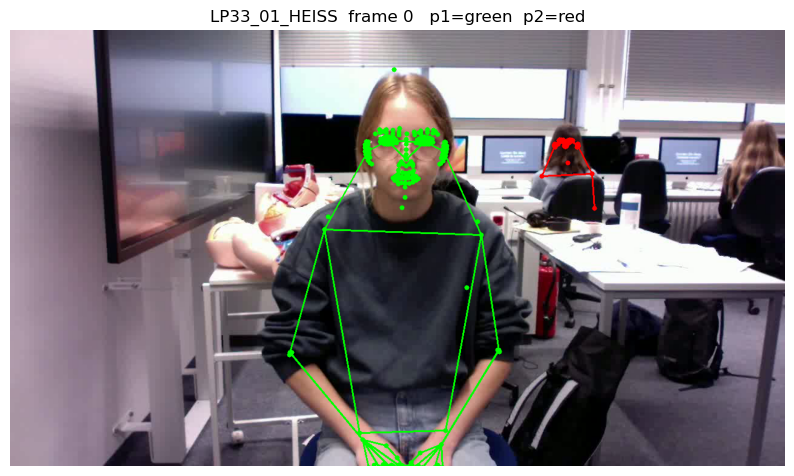

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP33_01_KOPIEREN\LP33_01_KOPIEREN_pose.csv
  showing frame 0


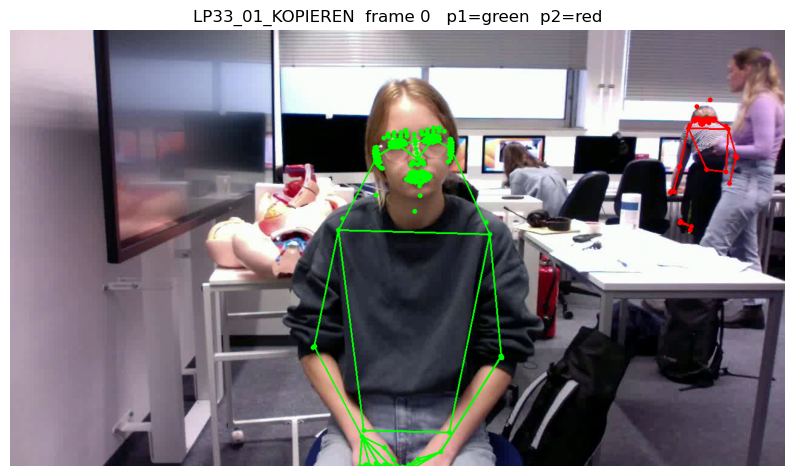

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP33_01_MUECKE\LP33_01_MUECKE_pose.csv
  showing frame 0


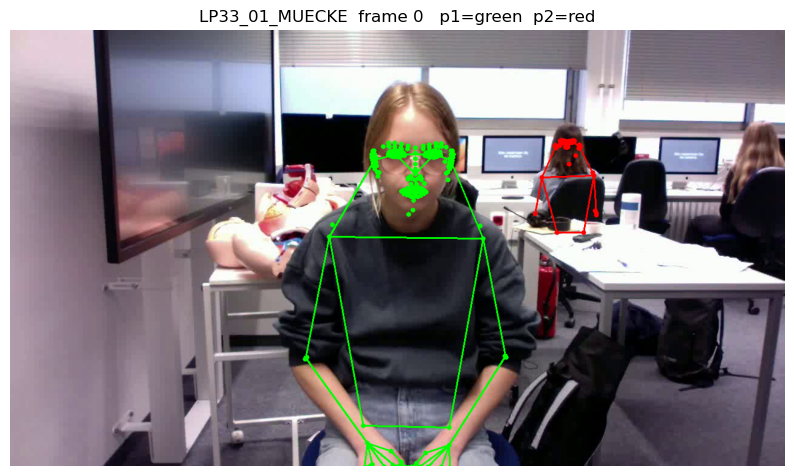

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP33_01_NAEHEN\LP33_01_NAEHEN_pose.csv
  showing frame 0


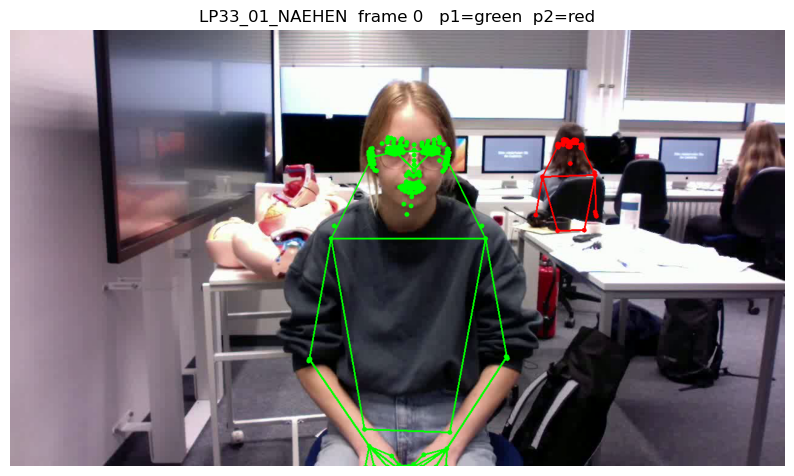

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP33_01_NASE\LP33_01_NASE_pose.csv
  showing frame 0


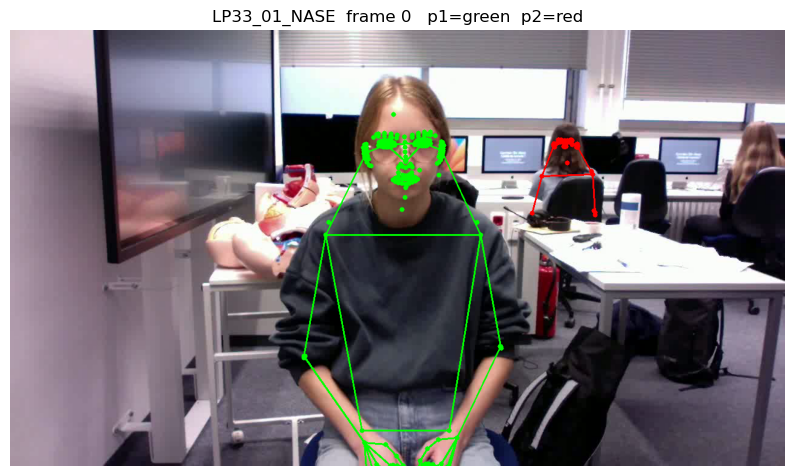

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP33_01_STINKEN\LP33_01_STINKEN_pose.csv
  showing frame 0


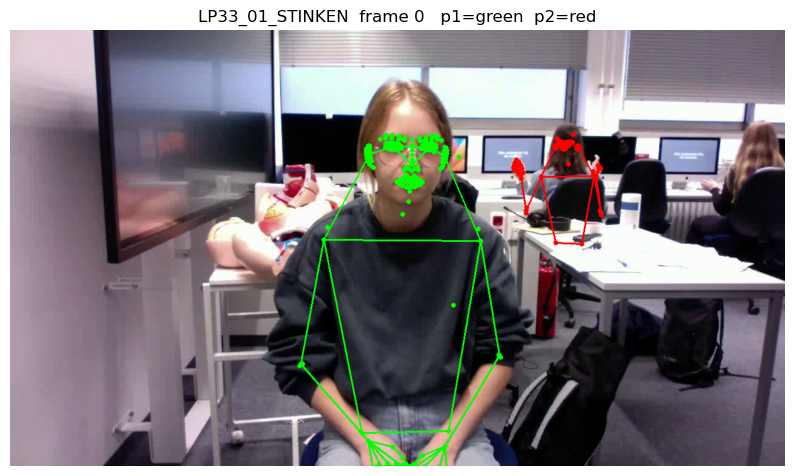

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP33_01_TRINKWASSER\LP33_01_TRINKWASSER_pose.csv
  showing frame 0


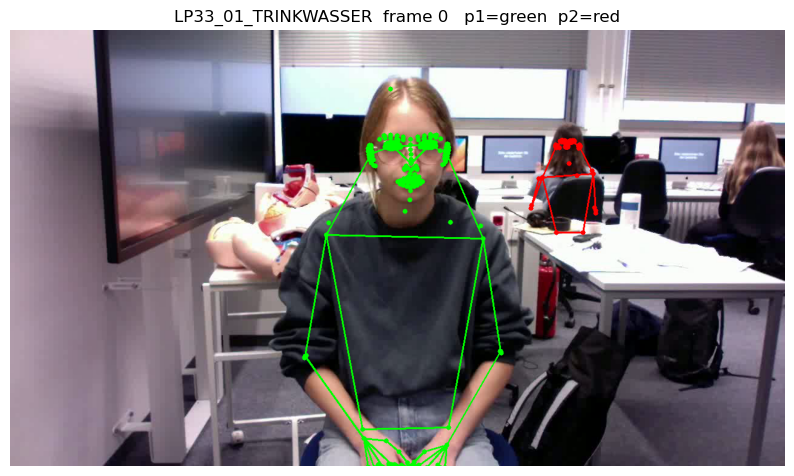

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP33_01_UEBERRASCHT\LP33_01_UEBERRASCHT_pose.csv
  showing frame 0


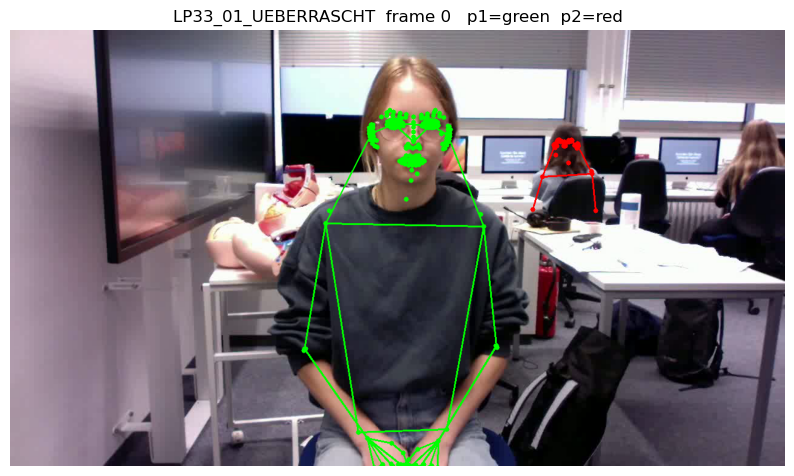

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP33_01_VERHEIRATET\LP33_01_VERHEIRATET_pose.csv
  showing frame 0


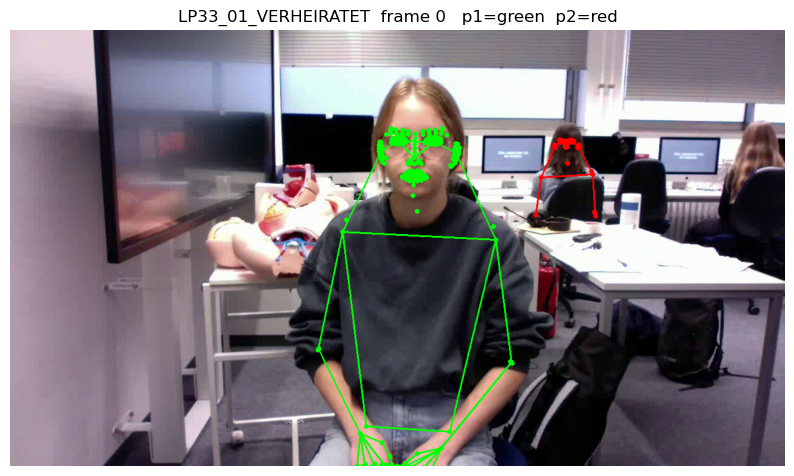

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP34_01_BEOBACHTEN\LP34_01_BEOBACHTEN_pose.csv
  showing frame 0


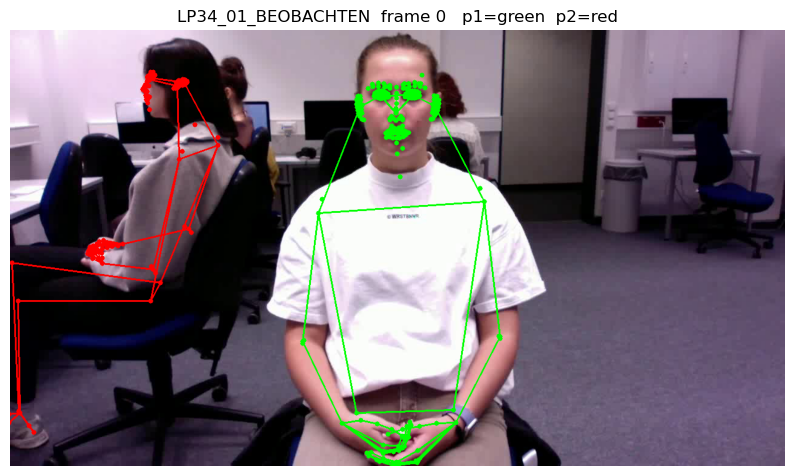

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP34_01_BILLIARD\LP34_01_BILLIARD_pose.csv
  showing frame 0


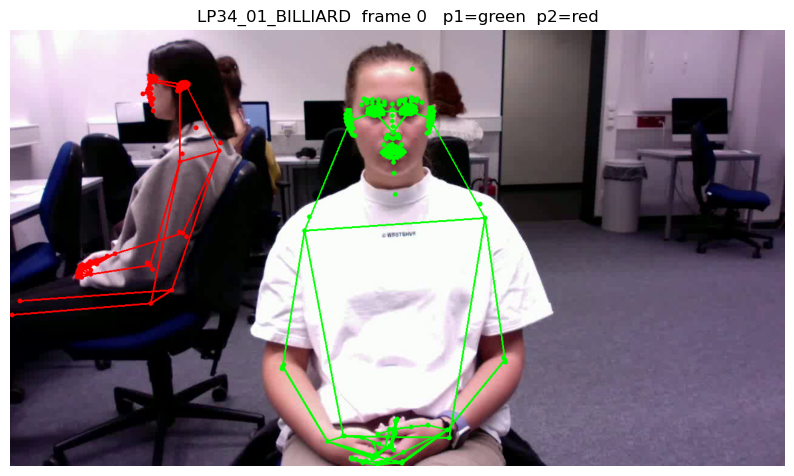

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP34_01_ESSEN\LP34_01_ESSEN_pose.csv
  showing frame 0


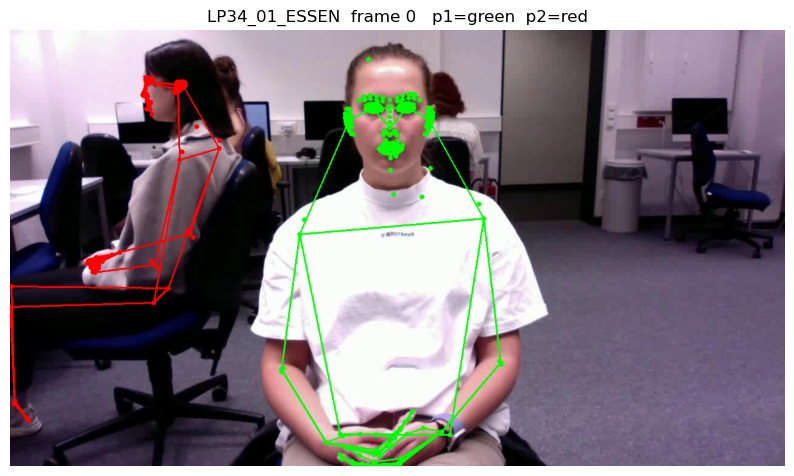

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP34_01_HAENDE\LP34_01_HAENDE_pose.csv
  showing frame 0


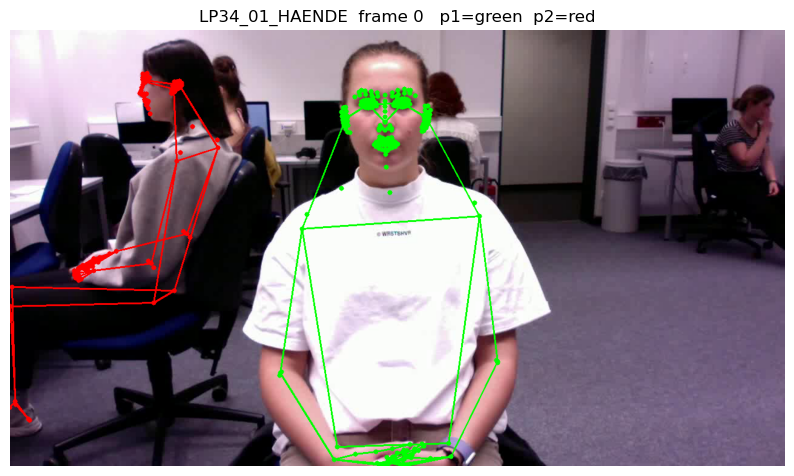

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP34_01_HANDY\LP34_01_HANDY_pose.csv
  showing frame 0


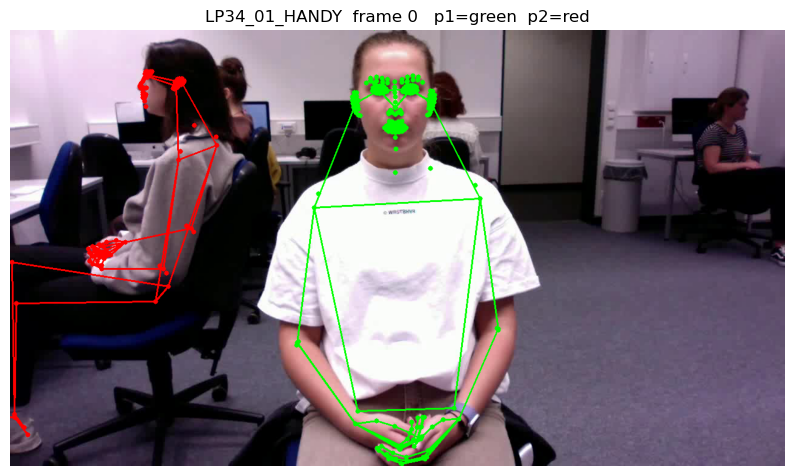

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP34_01_KLATSCHEN\LP34_01_KLATSCHEN_pose.csv
  showing frame 0


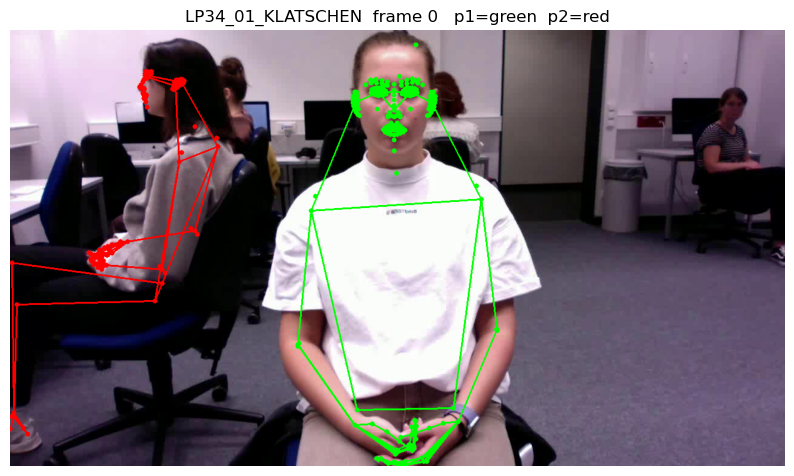

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP34_01_KOFFER\LP34_01_KOFFER_pose.csv
  showing frame 0


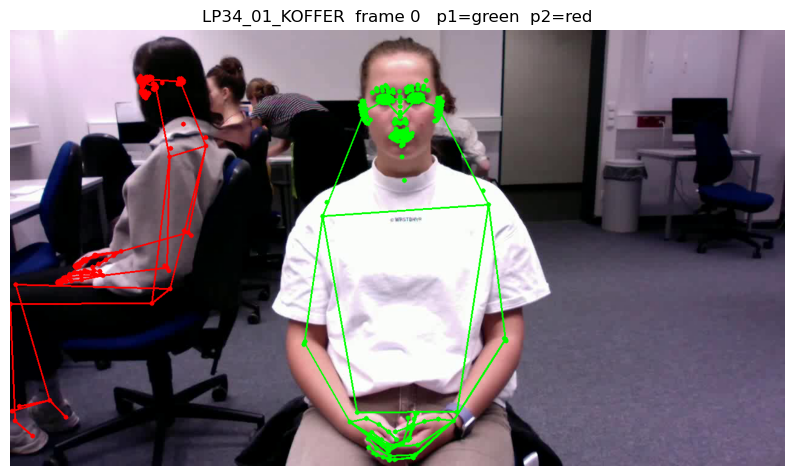

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP34_01_KOPIEREN\LP34_01_KOPIEREN_pose.csv
  showing frame 0


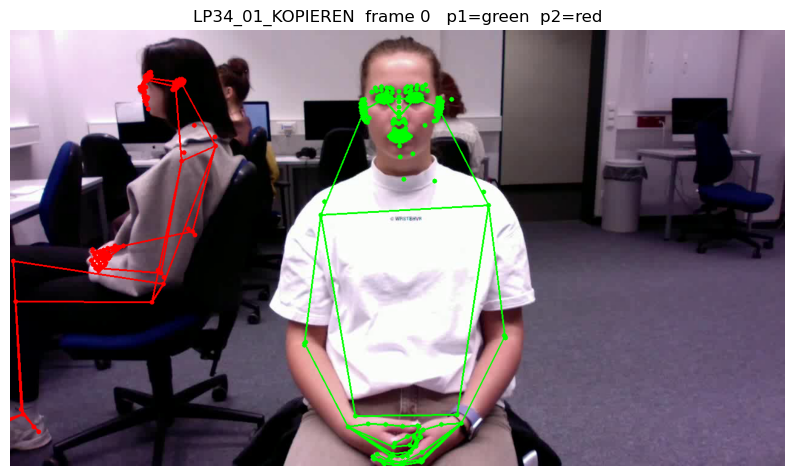

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP34_01_MASSAGE\LP34_01_MASSAGE_pose.csv
  showing frame 0


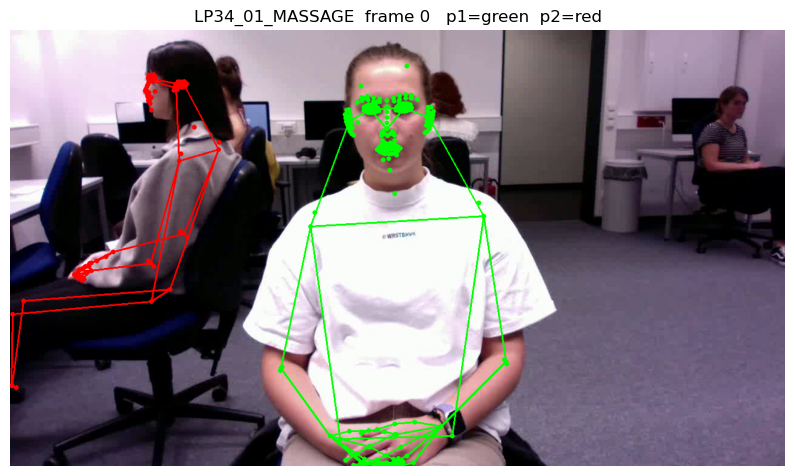

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP34_01_MILCH\LP34_01_MILCH_pose.csv
  showing frame 0


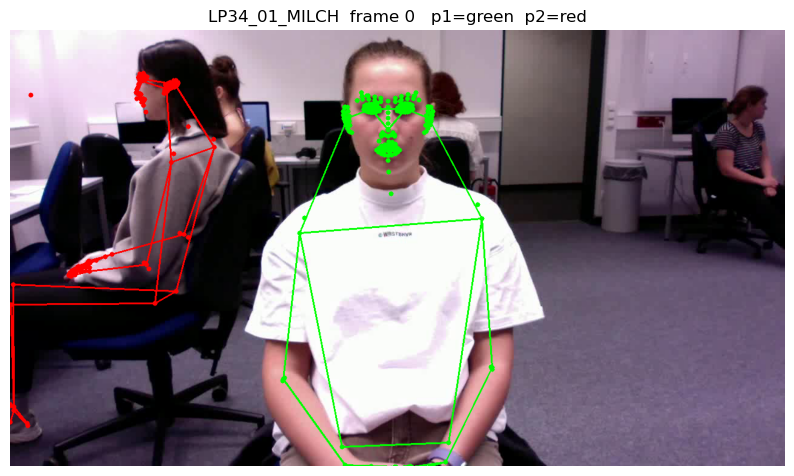

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP34_01_TELEFONANRUF\LP34_01_TELEFONANRUF_pose.csv
  showing frame 0


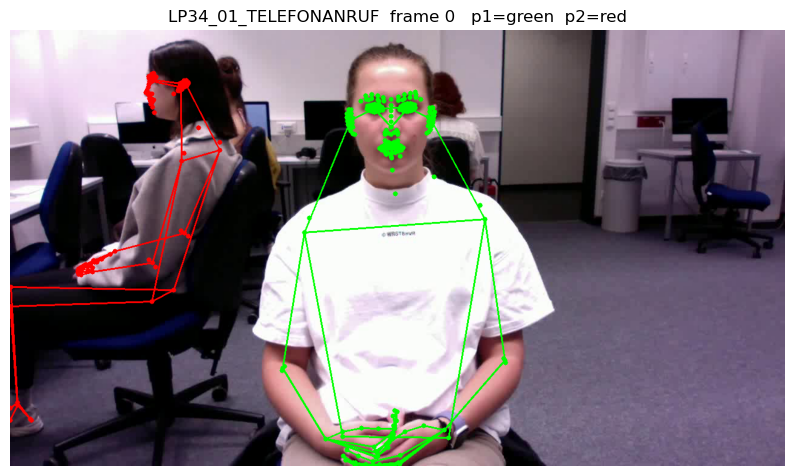

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP36_01_FOTOGRAFIE\LP36_01_FOTOGRAFIE_pose.csv
  showing frame 0


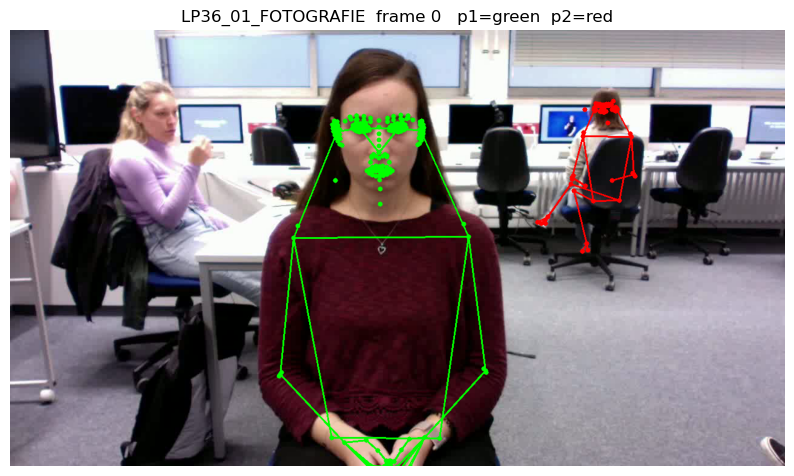

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP36_01_HUEGEL\LP36_01_HUEGEL_pose.csv
  showing frame 0


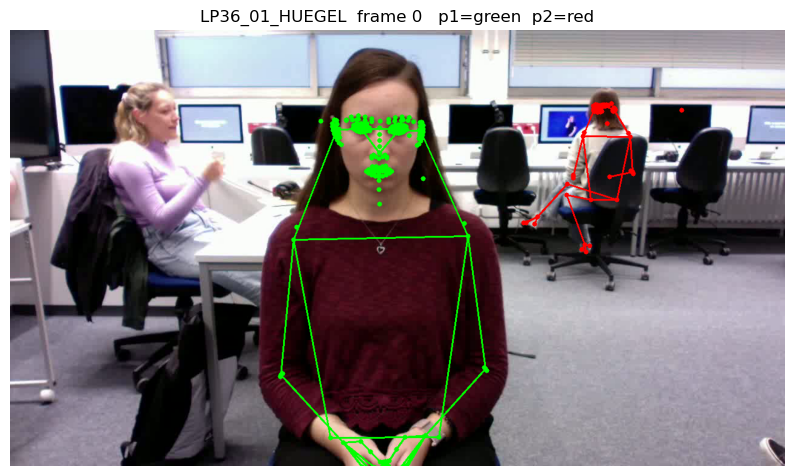

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP36_01_MIXER\LP36_01_MIXER_pose.csv
  showing frame 0


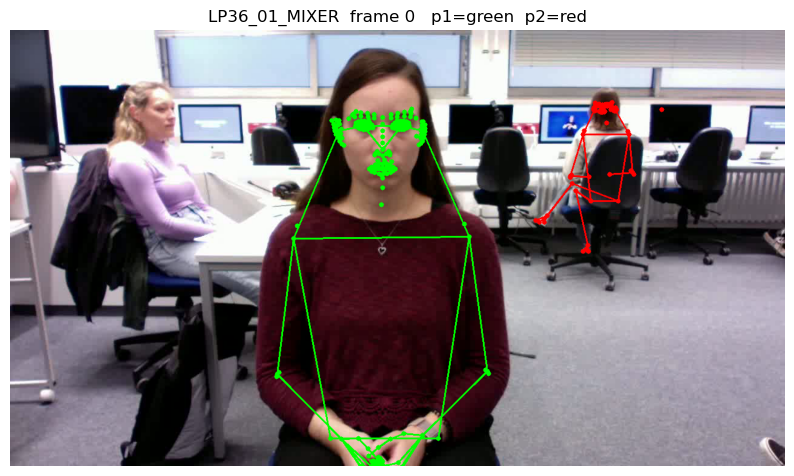

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP36_01_NAEHEN\LP36_01_NAEHEN_pose.csv
  showing frame 0


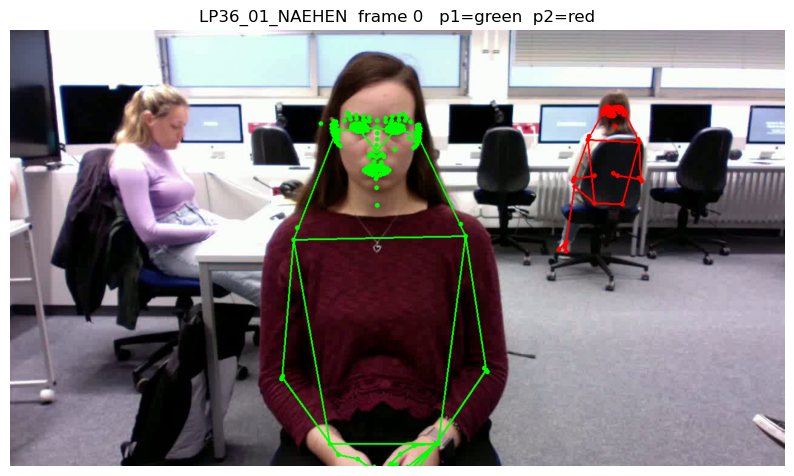

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP36_01_PFANNE\LP36_01_PFANNE_pose.csv
  showing frame 0


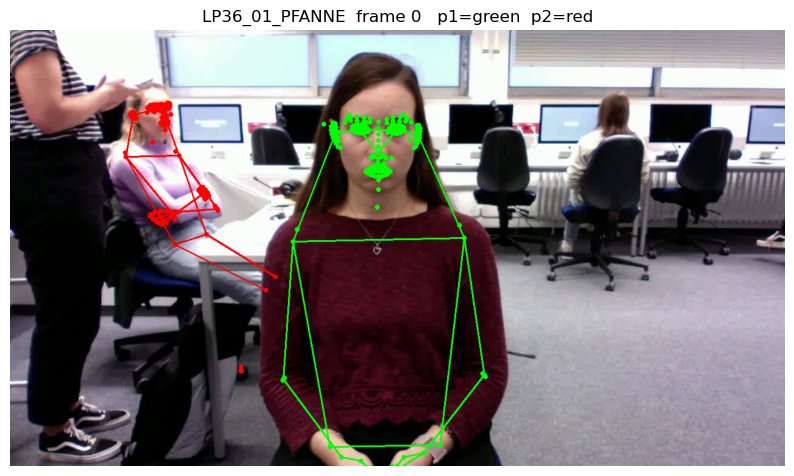

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP36_01_PFEFFER\LP36_01_PFEFFER_pose.csv
  showing frame 0


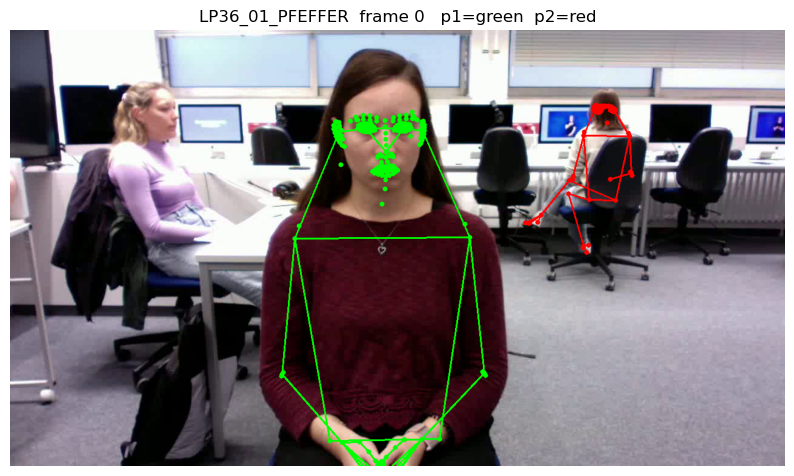

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP36_01_STERBEN\LP36_01_STERBEN_pose.csv
  showing frame 0


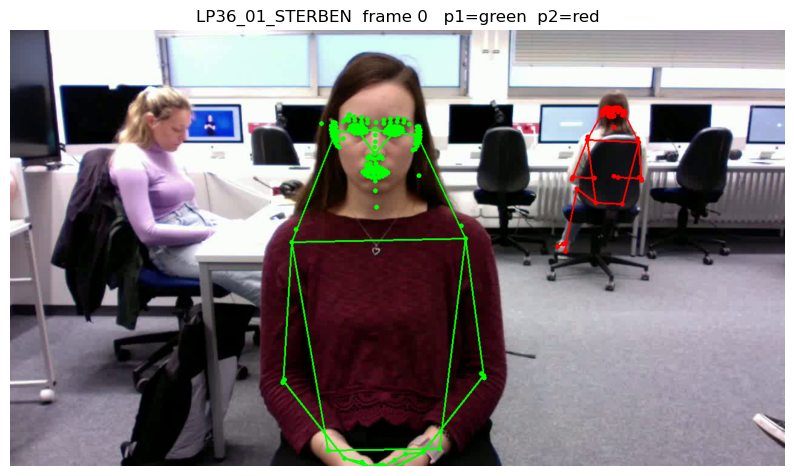

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP36_01_TREPPE\LP36_01_TREPPE_pose.csv
  showing frame 0


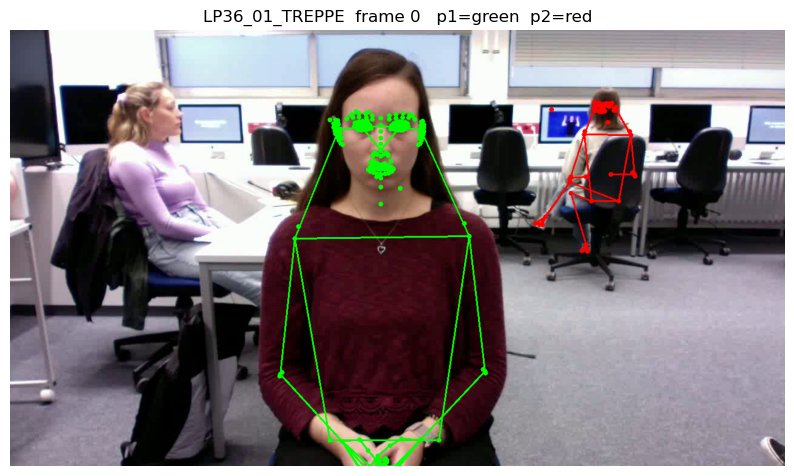

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP36_01_VERGANGENHEIT\LP36_01_VERGANGENHEIT_pose.csv
  showing frame 0


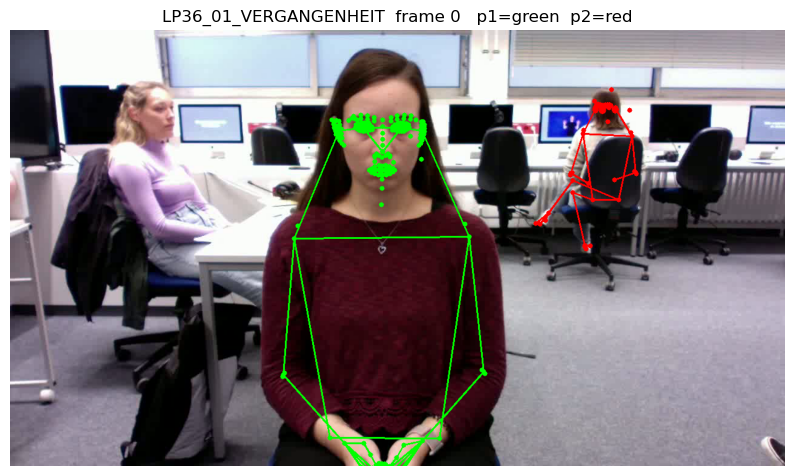

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP36_01_WARTEN\LP36_01_WARTEN_pose.csv
  showing frame 0


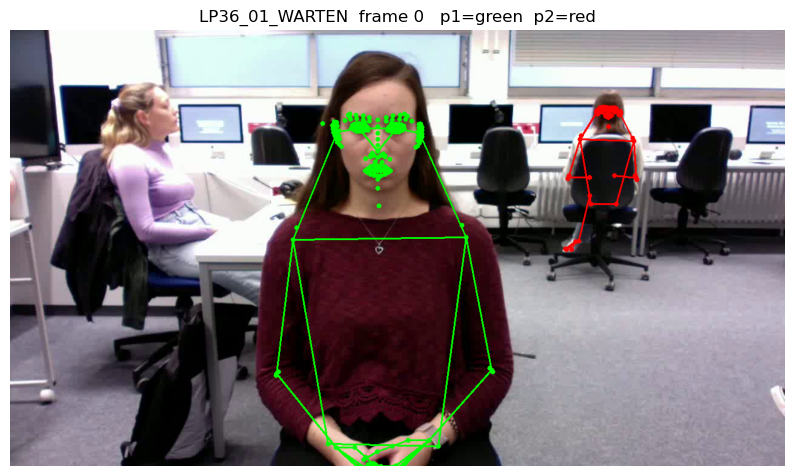

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP36_01_WEINEN\LP36_01_WEINEN_pose.csv
  showing frame 0


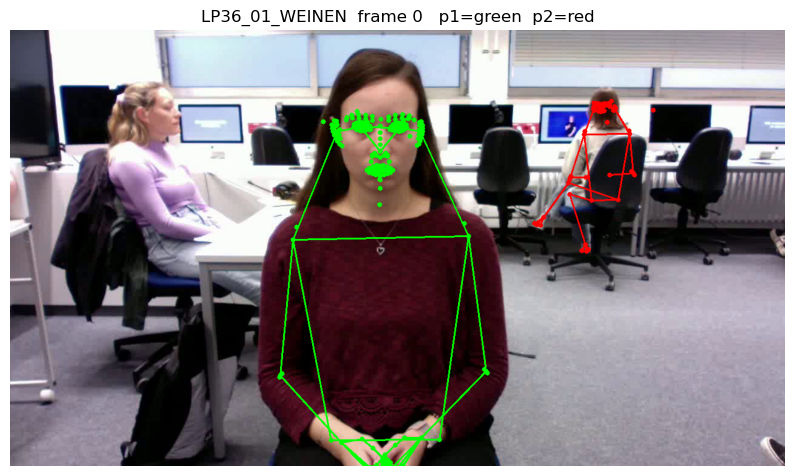

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP38_01_ARM\LP38_01_ARM_pose.csv
  showing frame 0


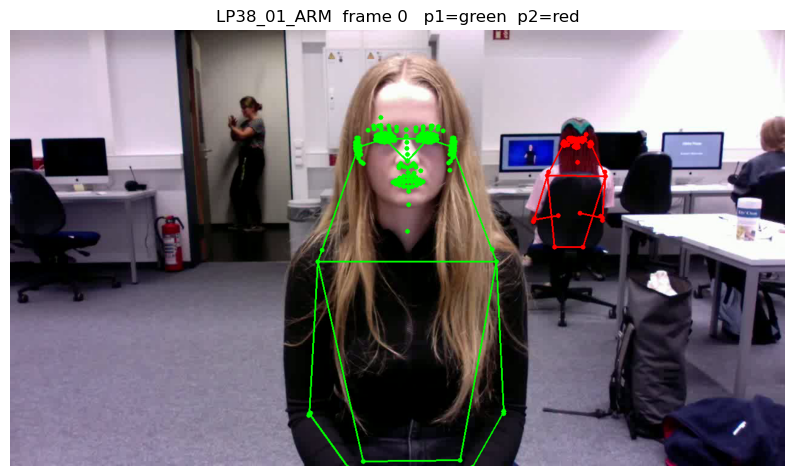

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP38_01_AUGE\LP38_01_AUGE_pose.csv
  showing frame 0


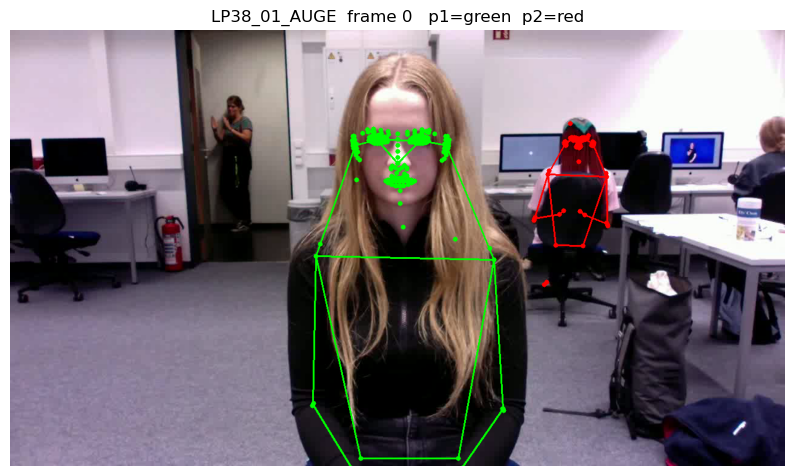

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP38_01_AUTO\LP38_01_AUTO_pose.csv
  showing frame 0


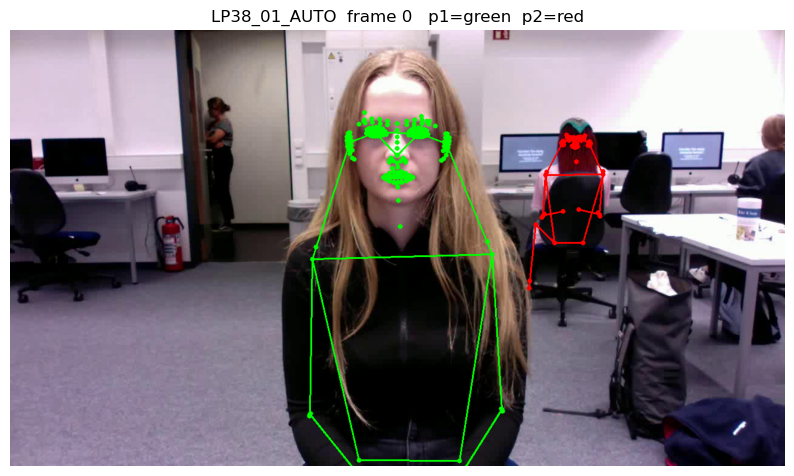

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP38_01_BRECHEN\LP38_01_BRECHEN_pose.csv
  showing frame 0


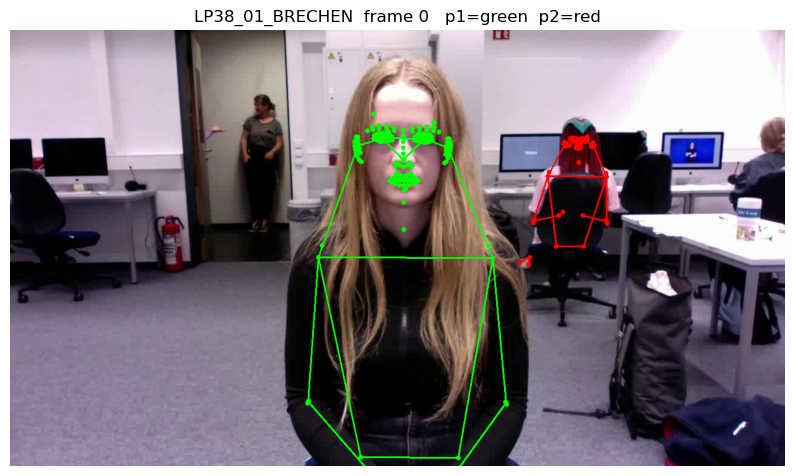

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP38_01_BUCH\LP38_01_BUCH_pose.csv
  showing frame 0


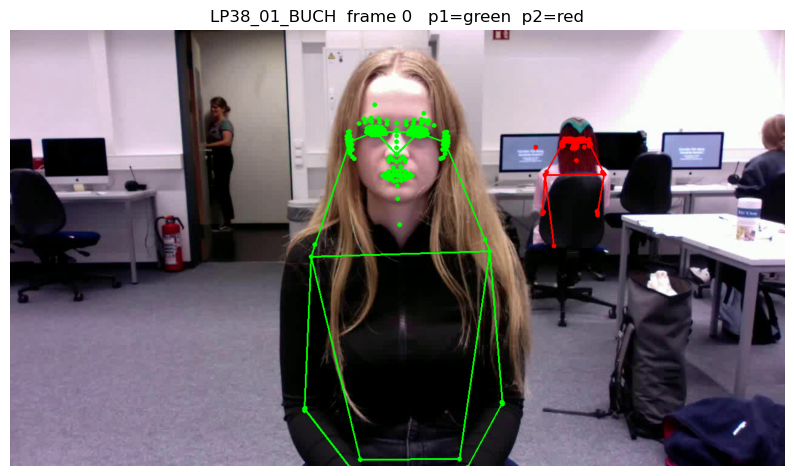

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP38_01_KOMMUNIKATION\LP38_01_KOMMUNIKATION_pose.csv
  showing frame 0


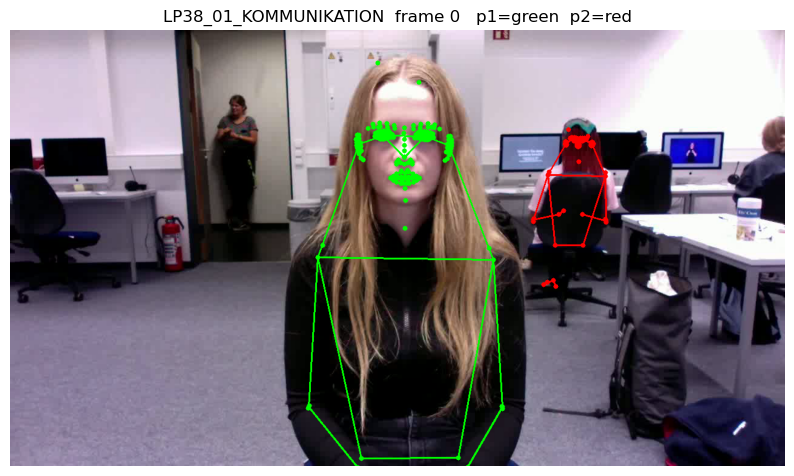

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP38_01_LIPPENSTIFT AUFTRAGEN\LP38_01_LIPPENSTIFT AUFTRAGEN_pose.csv
  showing frame 0


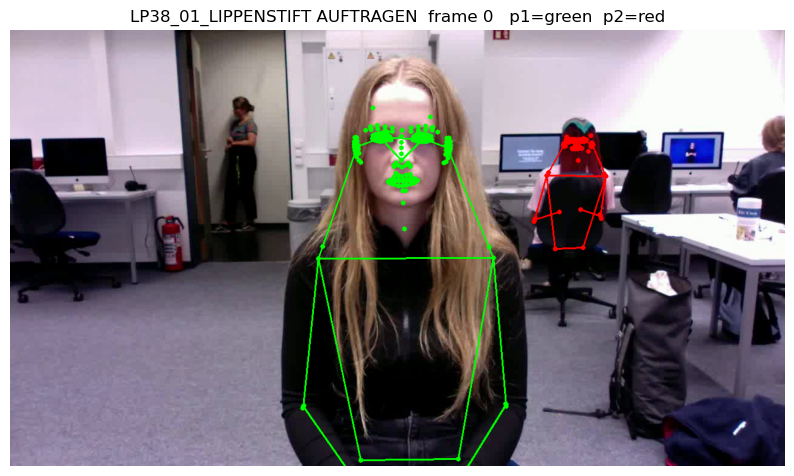

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP38_01_MILCH\LP38_01_MILCH_pose.csv
  showing frame 0


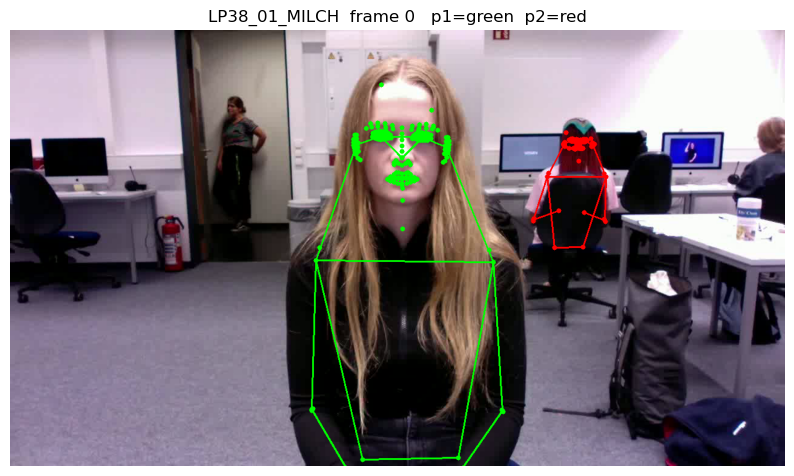

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP38_01_PYRAMIDE\LP38_01_PYRAMIDE_pose.csv
  showing frame 0


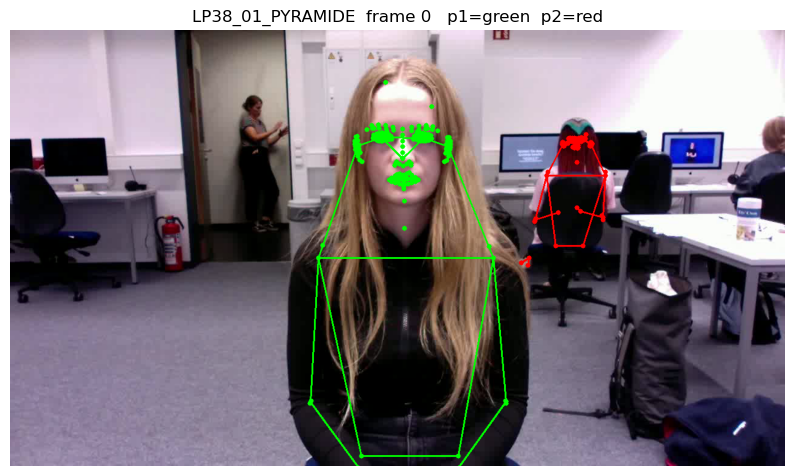

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP38_01_TEUFEL\LP38_01_TEUFEL_pose.csv
  showing frame 0


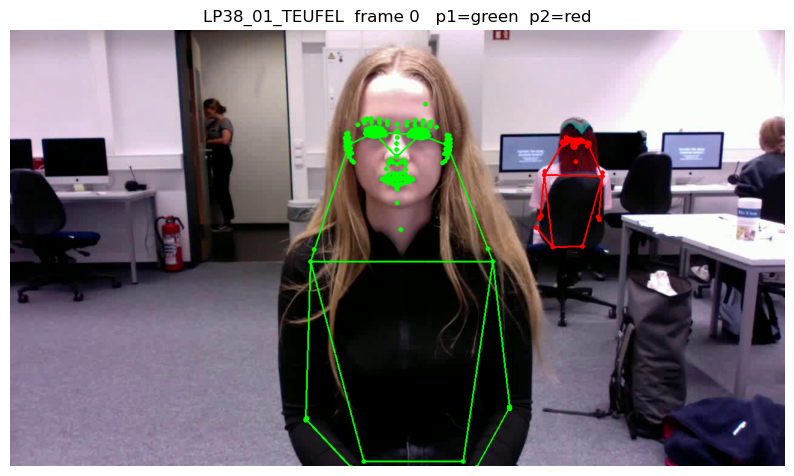

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP38_01_TREPPE\LP38_01_TREPPE_pose.csv
  showing frame 0


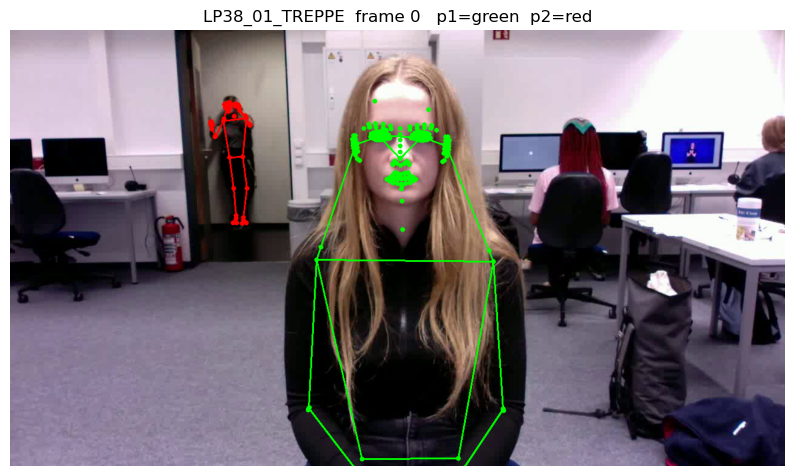

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP40_01_AUTO\LP40_01_AUTO_pose.csv
  showing frame 0


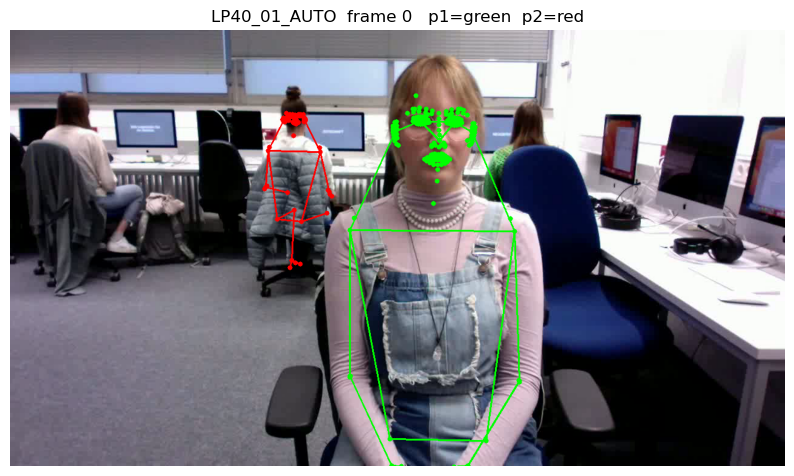

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP40_01_BUCH\LP40_01_BUCH_pose.csv
  showing frame 0


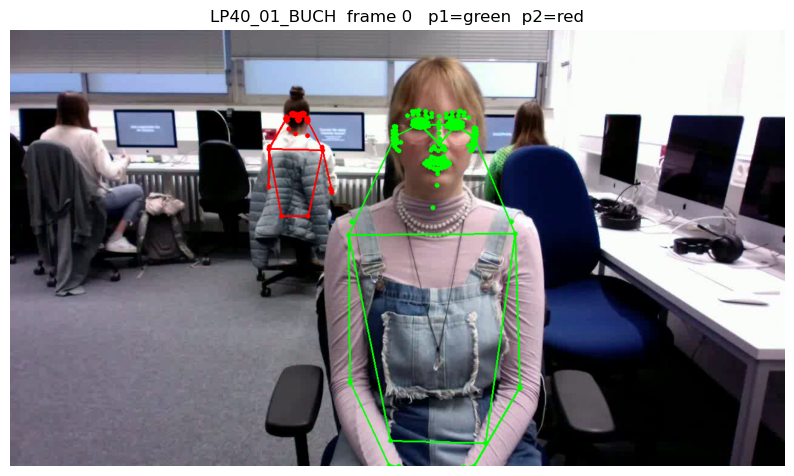

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP40_01_JONGLIEREN\LP40_01_JONGLIEREN_pose.csv
  showing frame 0


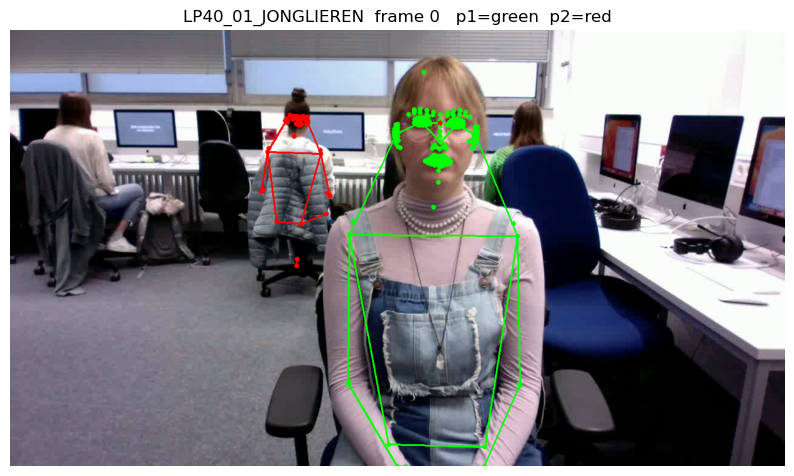

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP40_01_KAEMMEN\LP40_01_KAEMMEN_pose.csv
  showing frame 0


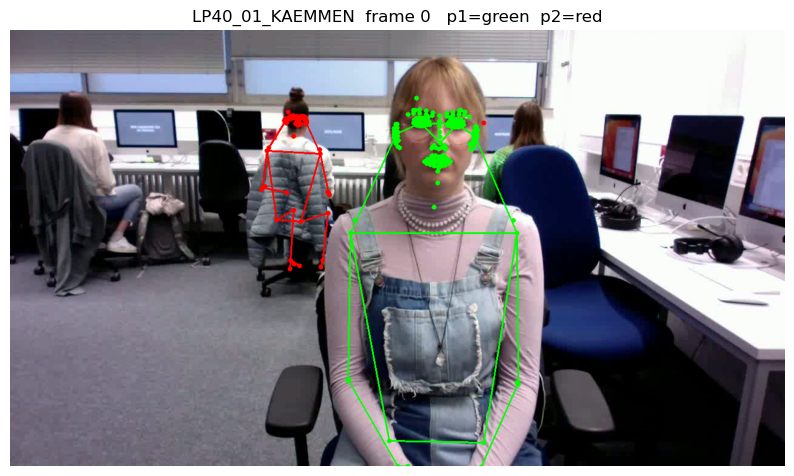

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP40_01_MOTORRAD\LP40_01_MOTORRAD_pose.csv
  showing frame 0


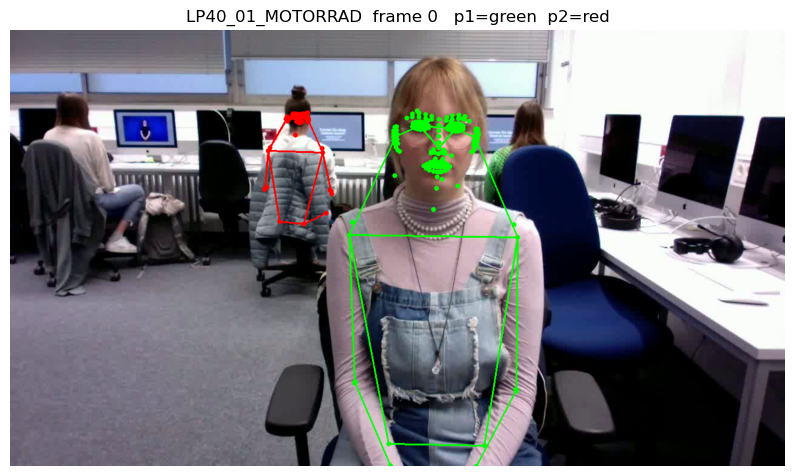

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP40_01_SANDWICH\LP40_01_SANDWICH_pose.csv
  showing frame 0


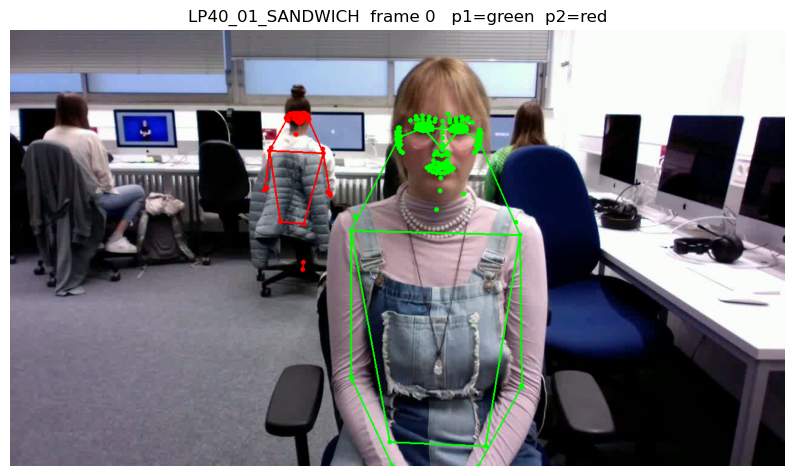

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP40_01_TISCHTENNIS\LP40_01_TISCHTENNIS_pose.csv
  showing frame 0


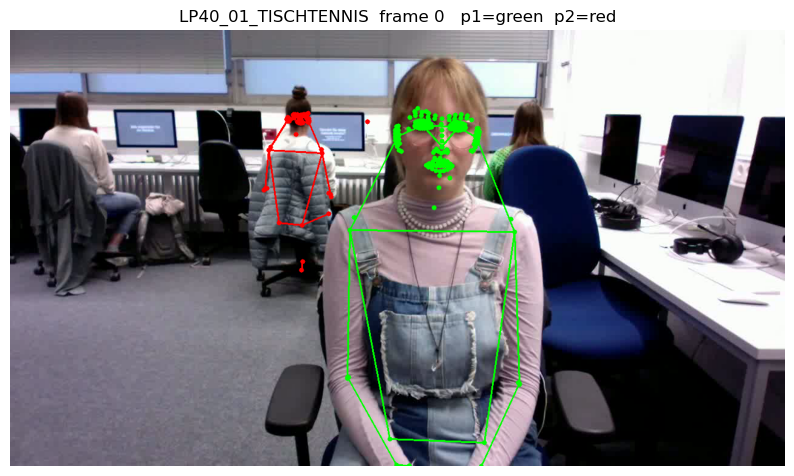

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP40_01_TRETEN\LP40_01_TRETEN_pose.csv
  showing frame 0


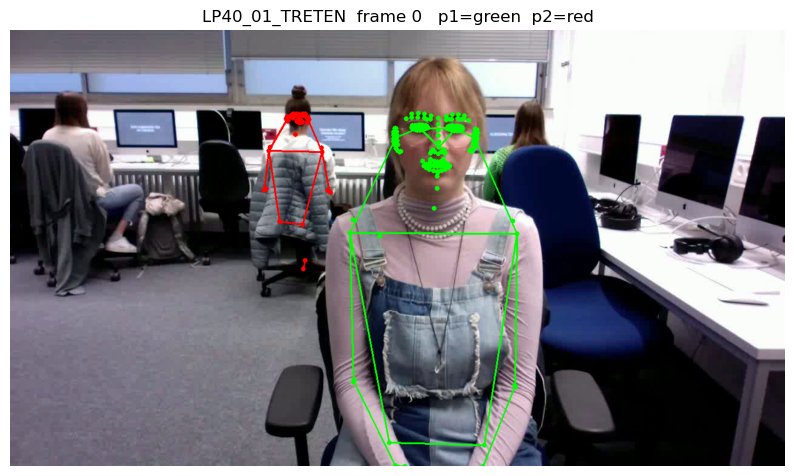

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP40_01_VERHEIRATET\LP40_01_VERHEIRATET_pose.csv
  showing frame 0


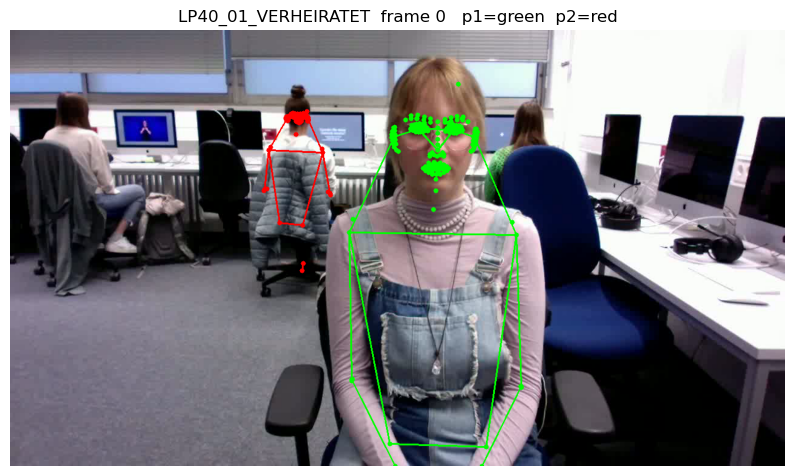

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP40_01_VORSCHLAGEN\LP40_01_VORSCHLAGEN_pose.csv
  showing frame 0


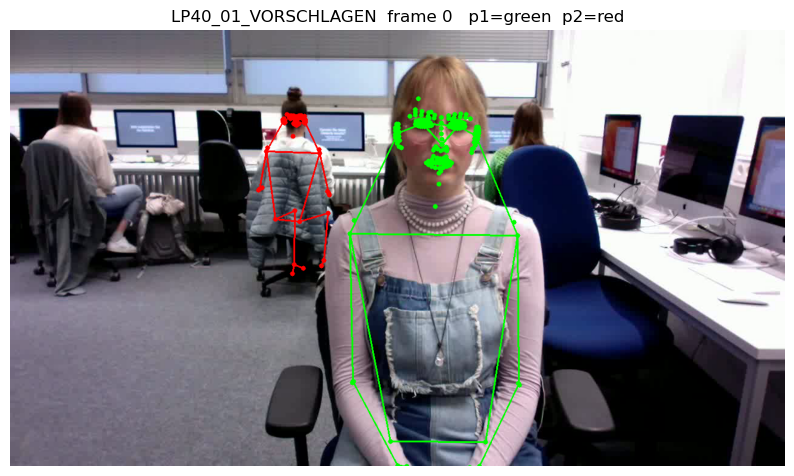

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP40_01_ZEICHNEN\LP40_01_ZEICHNEN_pose.csv
  showing frame 0


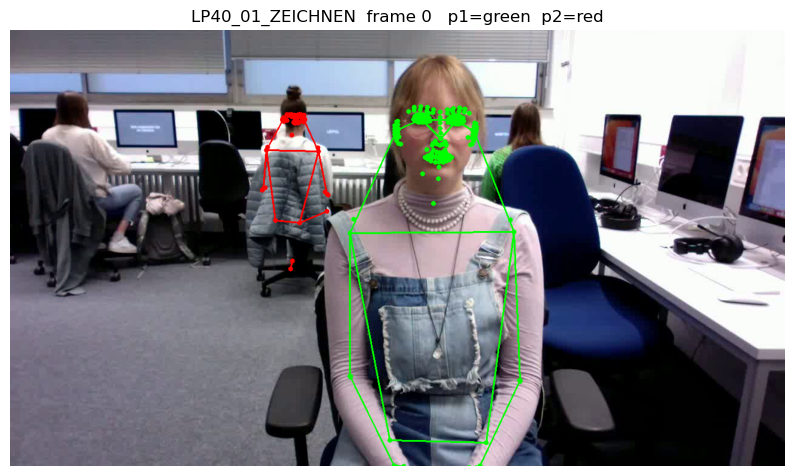

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP41_01_EGAL\LP41_01_EGAL_pose.csv
  showing frame 0


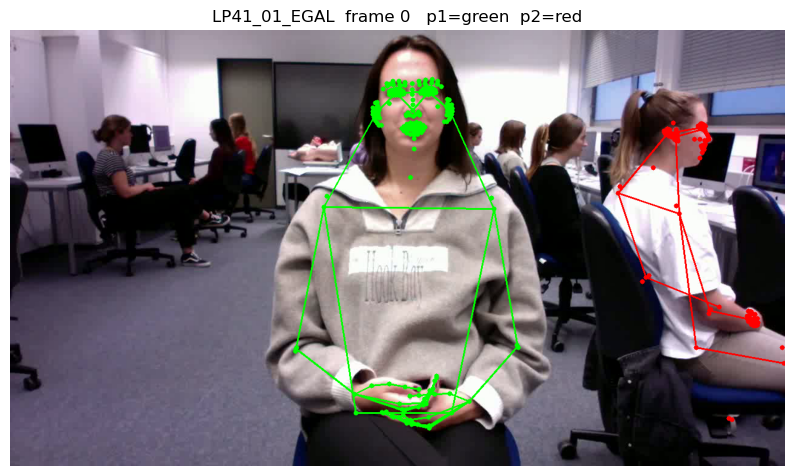

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP41_01_PYRAMIDE\LP41_01_PYRAMIDE_pose.csv
  showing frame 0


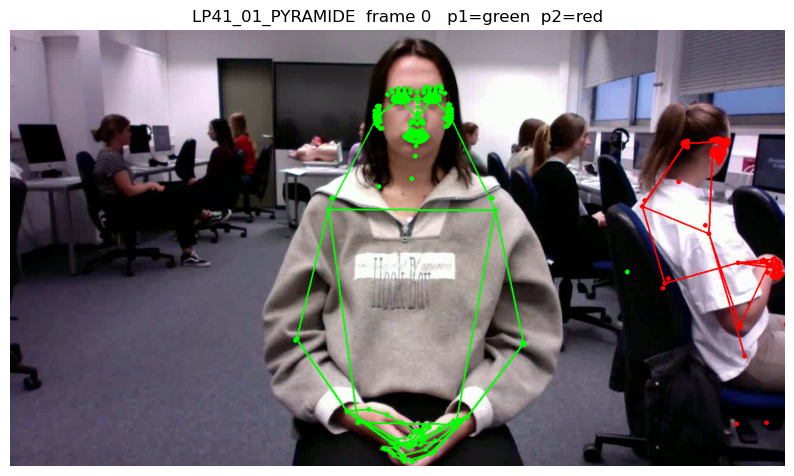

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP41_01_RAUCHEN\LP41_01_RAUCHEN_pose.csv
  showing frame 0


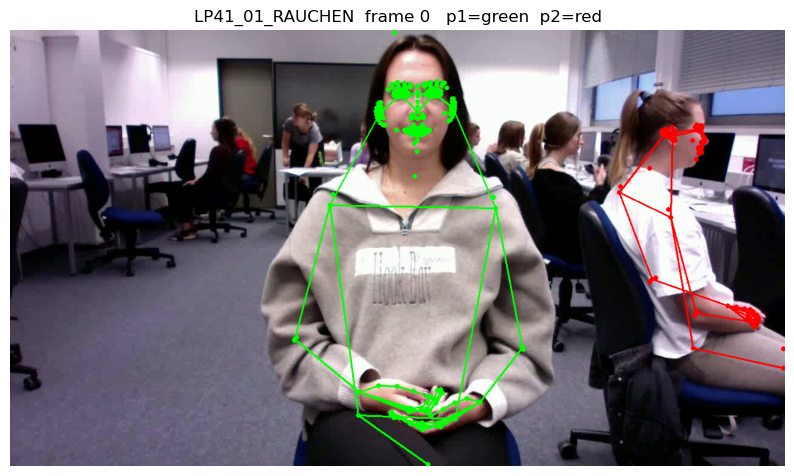

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP41_01_RENNEN\LP41_01_RENNEN_pose.csv
  showing frame 0


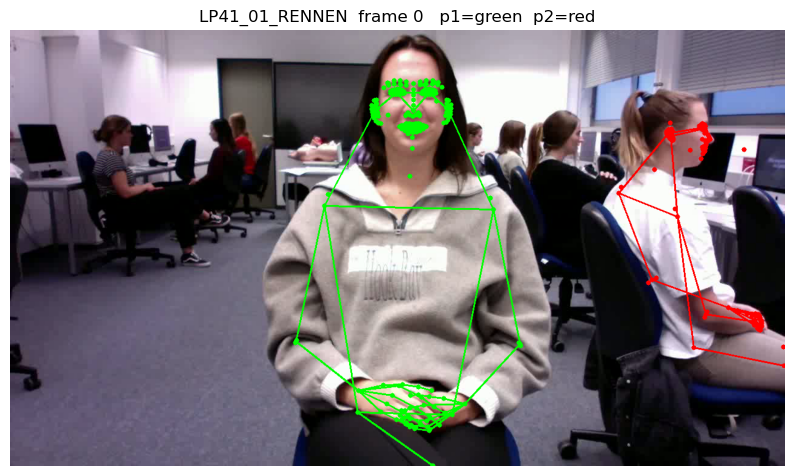

found p2 in c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Sapiens_Output\LP41_01_STINKEN\LP41_01_STINKEN_pose.csv
  showing frame 0


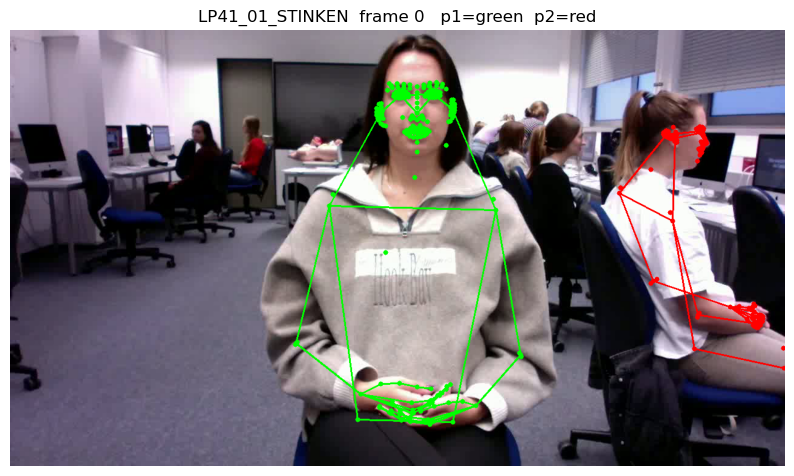

In [16]:
import numpy as np, cv2, os, glob
import matplotlib.pyplot as plt
import sys

sys.path.append(os.path.join(curfolder, 'Sapiens'))
from keypoints308 import dataset_info

csvfiles = glob.glob(os.path.join(curfolder, 'Sapiens_Output', '*', '*_pose.csv'))

_ki = dataset_info["keypoint_info"]
KP_NAMES = [_ki[i]["name"] for i in range(len(_ki))]
_name2id = {n: i for i, n in enumerate(KP_NAMES)}
SKELETON_EDGES = [(_name2id[a], _name2id[b])
                  for s in dataset_info["skeleton_info"].values()
                  for a, b in [s["link"]]
                  if a in _name2id and b in _name2id]

def person_xy(row, p):
    """Return (308x2 array, 308 conf) for person p from a dataframe row; NaN where missing."""
    xs = np.array([row.get(f"p{p}_{n}_x", np.nan) for n in KP_NAMES], float)
    ys = np.array([row.get(f"p{p}_{n}_y", np.nan) for n in KP_NAMES], float)
    cs = np.array([row.get(f"p{p}_{n}_conf", np.nan) for n in KP_NAMES], float)
    return np.column_stack([xs, ys]), cs

def draw(img, kpts, conf, color, thr=0.3):
    for a, b in SKELETON_EDGES:
        if conf[a] < thr or conf[b] < thr: continue
        if np.isnan(kpts[[a, b]]).any(): continue
        cv2.line(img, tuple(kpts[a].astype(int)), tuple(kpts[b].astype(int)), color, 2)
    for i in range(len(kpts)):
        if conf[i] < thr or np.isnan(kpts[i]).any(): continue
        cv2.circle(img, tuple(kpts[i].astype(int)), 4, color, -1)

for file in csvfiles:
    df = pd.read_csv(file)
    if not any(df.columns.str.contains('p2_')):
        continue
    print('found p2 in', file)

    # frames where BOTH persons have any keypoints -> pick the richest one
    p1_valid = df.filter(regex=r'^p1_.*_conf$').notna().sum(axis=1)
    p2_valid = df.filter(regex=r'^p2_.*_conf$').notna().sum(axis=1)
    both = df[(p1_valid > 0) & (p2_valid > 0)]
    if both.empty:
        print('  no frame has both -> p2 is sporadic; probably safe'); continue
    ridx = (p1_valid + p2_valid).loc[both.index].idxmax()   # most complete frame
    row = df.loc[ridx]
    frame_vis = int(row['frame'])
    print('  showing frame', frame_vis)

    name = os.path.basename(file).split('_pose.csv')[0]
    videofile = glob.glob(os.path.join(curfolder, 'GTST_sampled', name + '*.mp4'))[0]

    cap = cv2.VideoCapture(videofile)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_vis)
    ok, img = cap.read()
    cap.release()
    if not ok:
        print('  could not read frame'); continue

    k1, c1 = person_xy(row, 1)
    k2, c2 = person_xy(row, 2)
    draw(img, k1, c1, (0, 255, 0))     # p1 = green
    draw(img, k2, c2, (0, 0, 255))     # p2 = red

    plt.figure(figsize=(10, 7))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"{name}  frame {frame_vis}   p1=green  p2=red")
    plt.axis('off'); plt.show()
    #break     # remove to step through all p2 files

Now we can see that in only multi-party cases, p1 is the person of interest. We can therefore proceed with keeping only p1_* in the data

## Further processing (sample)

C:\Users\kadava\AppData\Local\Temp\ipykernel_54528\756630961.py:57: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['FileID'] = name
C:\Users\kadava\AppData\Local\Temp\ipykernel_54528\756630961.py:60: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['frame'] = frames
C:\Users\kadava\AppData\Local\Temp\ipykernel_54528\756630961.py:61: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.conc

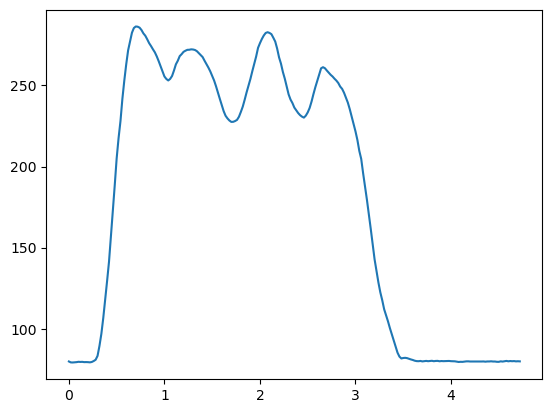

In [19]:
import matplotlib.pyplot as plt

csvfiles = glob.glob(os.path.join(curfolder, 'Sapiens_Output', '*', '*_pose.csv'))
csvsample = csvfiles[0]

TOKEEP = ['nose', 'shoulder', 'elbow', 'hip', 'thumb', 'finger', 'wrist', 'neck']

def flip_axis(df):
    cols = [col for col in df.columns if '_y' in col]
    
    # Identify the maximum value in the first row of the Y_
    maxpoint = max(df.loc[0, cols])

    # Flip all Y_ columns across all rows
    for joint in cols:
        df.loc[:, joint] = maxpoint - df[joint] - 1
            
    return df

def interpolate(df):
    cols = df.columns
    #print(cols)

    # put away time and fileID from cols
    cols = cols.drop(['time_s', 'frame', 'FileID'])

    # loop over the cols and interpolate missing data
    for col in cols:
        df[col] = df[col].interpolate(method='linear', x = df['time_s'], limit=10)
    return df


def clean_and_process_df(file, colstokeep):
    df = pd.read_csv(file)
    name = os.path.basename(file).split('_pose.csv')[0]

    # Get frame and time_s columns
    frames = df['frame']
    time_s = df['time_s']

    # Keep only p1_ columns
    df = df.loc[:, df.columns.str.contains('p1_')]
    
    # Keep only columns that share strings with elements in colstokeep
    df = df.loc[:, df.columns.str.contains('|'.join(colstokeep))]

    # Rename columns to remove p1_ prefix
    df.columns = df.columns.str.replace('p1_', '')

    # Get rid of columns that have '_of_' in (residuals of nose columns that we don't need)
    df = df.loc[:, ~df.columns.str.contains('_of_')]

    # Flip y axis
    df = flip_axis(df)

    # Add name as FileID
    df['FileID'] = name

    # Add time and frames in the beginning
    df['frame'] = frames
    df['time_s'] = time_s

    # Interpolate
    df = interpolate(df)

    return df

sample_proc = clean_and_process_df(csvsample, TOKEEP)
sample_proc.head()

# Plot wrist in y
plt.plot(sample_proc['time_s'], sample_proc['right_wrist_y'])

## Smoothing (sample)

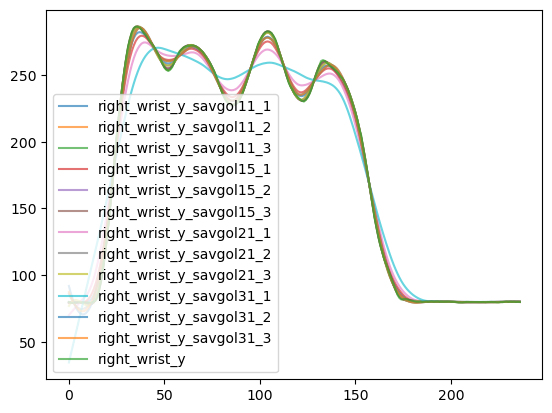

In [3]:
import scipy.signal

# test the different smoothing filter options - smoothing with savitzky-golay filter
x = 'right_wrist_y'
y = 'right_wrist_x'


# list possible window
window = [11, 15, 21, 31]
# list possible orders
order = [1, 2, 3]

# col of interest
samplecol = [y, x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample_proc[col], win, ord)


# make R_Hand_x from df_sample a list
col_x = sample_proc[x].tolist()
col_y = sample_proc[y].tolist()

# load these values into df_smooth as a new column
df_smooth[x] = col_x
df_smooth[y] = col_y

# plot all col_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
plt.show()




In [11]:
import numpy as np, pandas as pd, cv2, glob, os
import scipy.signal
import sys
sys.path.append(os.path.join(curfolder, 'Sapiens'))
from keypoints308 import dataset_info

_ki = dataset_info["keypoint_info"]
KP_NAMES = [_ki[i]["name"] for i in range(len(_ki))]
_name2id = {n: i for i, n in enumerate(KP_NAMES)}
SKELETON_EDGES = [(_name2id[a], _name2id[b], s["color"])
                  for s in dataset_info["skeleton_info"].values()
                  for a, b in [s["link"]]
                  if a in _name2id and b in _name2id]

CONF_THR = 0.3
COMBOS = [(11, 2), (15,2), (21, 2)]      # <-- your three (window, order) choices

def smooth_series(vals, conf, win, order):
    """Mask low-conf -> interpolate -> savgol. vals, conf are 1D arrays over frames."""
    s = pd.Series(vals, dtype=float)
    s[conf < CONF_THR] = np.nan
    s = s.interpolate(limit_direction="both")     # fill gaps so savgol can run
    if s.isna().all():
        return vals                                # nothing usable; leave as-is
    if len(s) <= win:
        return s.to_numpy()                        # too short to filter
    return scipy.signal.savgol_filter(s.to_numpy(), win, order)

def build_smoothed(df, person, win, order):
    """Return dict name -> (x_arr, y_arr) smoothed across all frames for one person."""
    out = {}
    for nm in KP_NAMES:
        cx = df.get(f"{person}_{nm}_x")
        cy = df.get(f"{person}_{nm}_y")
        cc = df.get(f"{person}_{nm}_conf")
        if cx is None:
            continue
        conf = cc.to_numpy() if cc is not None else np.ones(len(df))
        out[nm] = (smooth_series(cx.to_numpy(), conf, win, order),
                   smooth_series(cy.to_numpy(), conf, win, order))
    return out

def draw_skeleton(img, coords_by_name, fi, color=None):
    def pt(nm):
        if nm not in coords_by_name: return None
        x, y = coords_by_name[nm][0][fi], coords_by_name[nm][1][fi]
        return None if (np.isnan(x) or np.isnan(y)) else (int(x), int(y))
    for a, b, c in SKELETON_EDGES:
        pa, pb = pt(KP_NAMES[a]), pt(KP_NAMES[b])
        if pa and pb:
            cv2.line(img, pa, pb, (color or c[::-1]), 2)
    for nm in coords_by_name:
        p = pt(nm)
        if p: cv2.circle(img, p, 3, (color or (0, 255, 0)), -1)
    return img

def render_smoothing_qc(csv_path, video_path, out_dir, person="p1"):
    os.makedirs(out_dir, exist_ok=True)
    df = pd.read_csv(csv_path).sort_values("frame").reset_index(drop=True)
    name = os.path.basename(csv_path).split("_pose.csv")[0]

    # precompute smoothed coords for each combo
    smoothed = {combo: build_smoothed(df, person, *combo) for combo in COMBOS}

    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # one output video per combo
    writers = {combo: cv2.VideoWriter(
                   os.path.join(out_dir, f"{name}_savgol_w{combo[0]}_o{combo[1]}.mp4"),
                   cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
               for combo in COMBOS}

    for fi in range(len(df)):
        vframe = int(df.loc[fi, "frame"])
        cap.set(cv2.CAP_PROP_POS_FRAMES, vframe)
        ok, base = cap.read()
        if not ok: continue
        for combo in COMBOS:
            img = base.copy()
            draw_skeleton(img, smoothed[combo], fi, color=(0, 255, 0))
            cv2.putText(img, f"savgol win={combo[0]} order={combo[1]}", (12, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
            writers[combo].write(img)

    cap.release()
    for w in writers.values(): w.release()
    print("wrote", len(COMBOS), "videos to", out_dir)

# run on one file
filename = sample_proc['FileID'].iloc[0]
csv_path = os.path.join(curfolder, 'Sapiens_Output', filename, filename + '_pose.csv')
video_path = glob.glob(os.path.join(curfolder, "GTST_sampled", filename + "*.mp4"))[0]
render_smoothing_qc(csv_path, video_path, os.path.join(curfolder, "smoothing_qc"))

wrote 3 videos to c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\smoothing_qc


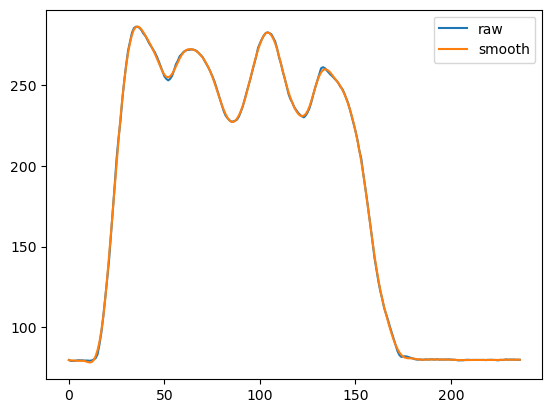

In [26]:
def savgol_smooth(df, window=21, order=2):
    df_smoothed = df.copy()
    colstosmooth = [c for c in df_smoothed.columns if c.endswith('_x') or c.endswith('_y')]
    #print(colstosmooth)
    for col in colstosmooth:
            df_smoothed[col] = scipy.signal.savgol_filter(df[col], window, order)

    return df_smoothed

sample_smooth = savgol_smooth(sample_proc, window=15, order=2)

# plot wrist_y from sample_proc and sample_smooth
plt.plot(sample_proc['right_wrist_y'], label = 'raw')
plt.plot(sample_smooth['right_wrist_y'], label = 'smooth')
plt.legend()
plt.show()

## Normalization

Given the nature of the data, we need to perform three normalization steps

- center all coordinates on mid-torso
- normalize all coordinates by torso length (to account for varying bodies)


In [28]:
def add_mid_torso_and_center_df(
    df,
    l_shoulder_prefix="left_shoulder",
    r_shoulder_prefix="right_shoulder",
    l_hip_prefix="left_hip",
    r_hip_prefix="right_hip"):
    """
    Create mid-torso from shoulders and hips and center all XYZ keypoints on it.

    Expected columns:
      X_<name>, Y_<name>, Z_<name>, visibility_<name>

    Returns a new DataFrame with:
      - X_midTorso, Y_midTorso, Z_midTorso added
      - All X_*, Y_*, Z_* centered on mid-torso
      - visibility_* and time unchanged
    """

    df = df.copy()

    # --- 1. Compute midpoints ---
    df["midtorso_x"] = 0.5 * (df[f"{l_shoulder_prefix}_x"] + df[f"{r_shoulder_prefix}_x"])
    df["midtorso_y"] = 0.5 * (df[f"{l_shoulder_prefix}_y"] + df[f"{r_shoulder_prefix}_y"])

    hips_mid_x = 0.5 * (df[f"{l_hip_prefix}_x"] + df[f"{r_hip_prefix}_x"])
    hips_mid_y = 0.5 * (df[f"{l_hip_prefix}_y"] + df[f"{r_hip_prefix}_y"])

    df["midtorso_x"] = 0.5 * (df["midtorso_x"] + hips_mid_x)
    df["midtorso_y"] = 0.5 * (df["midtorso_y"] + hips_mid_y)

    # --- 2. Center all XYZ columns on mid-torso ---
    x_cols = [c for c in df.columns if c.endswith("_x")]
    y_cols = [c for c in df.columns if c.endswith("_y")]

    for c in x_cols:
        df[c] = df[c] - df["midtorso_x"]
    for c in y_cols:
        df[c] = df[c] - df["midtorso_y"]

    return df


# usage on sample
sample_norm = add_mid_torso_and_center_df(sample_smooth)

# check that mid-torso is now at (0,0,0)
print(sample_norm[["midtorso_x", "midtorso_y"]].head())


   midtorso_x  midtorso_y
0         0.0         0.0
1         0.0         0.0
2         0.0         0.0
3         0.0         0.0
4         0.0         0.0


No trunk length provided, computing from data...
Trunk length used for normalization: 270.7304943490461


C:\Users\kadava\AppData\Local\Temp\ipykernel_54528\3780951144.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["midshoulder_x"] = 0.5 * (df["left_shoulder_x"] + df["right_shoulder_x"])
C:\Users\kadava\AppData\Local\Temp\ipykernel_54528\3780951144.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["midshoulder_y"] = 0.5 * (df["left_shoulder_y"] + df["right_shoulder_y"])
C:\Users\kadava\AppData\Local\Temp\ipykernel_54528\3780951144.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of 

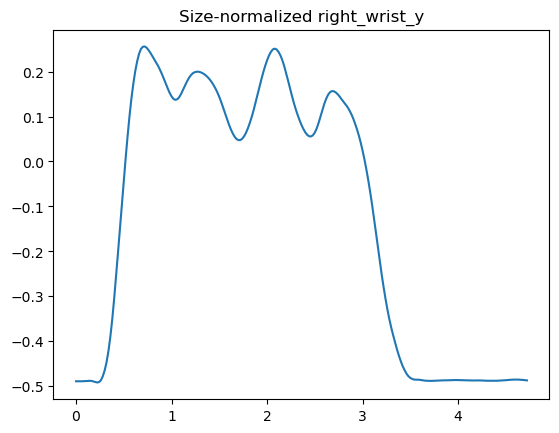

In [ ]:
def size_normalize_by_trunk(df, trunk_len=None):

    if trunk_len is None:

        print("No trunk length provided, computing from data...")
    
        # create mid shoulder
        df["midshoulder_x"] = 0.5 * (df["left_shoulder_x"] + df["right_shoulder_x"])
        df["midshoulder_y"] = 0.5 * (df["left_shoulder_y"] + df["right_shoulder_y"])

        # create midhip
        df["midhip_x"] = 0.5 * (df["left_hip_x"] + df["right_hip_x"])
        df["midhip_y"] = 0.5 * (df["left_hip_y"] + df["right_hip_y"])

        # compute trunk length as median distance between mid-shoulder and mid-hip
        dx = df["midshoulder_x"] - df["midhip_x"]
        dy = df["midshoulder_y"] - df["midhip_y"]

        trunk_len = np.median(np.sqrt(dx**2 + dy**2))

    else:
        print(f"Using provided trunk length: {trunk_len}") 

    xy_cols = [c for c in df.columns if c.endswith(("_x", "_y"))]
    for c in xy_cols:
        df[c] = df[c] / trunk_len

    return trunk_len, df

trunk_len, sample_norm = size_normalize_by_trunk(sample_norm)
print(f"Trunk length used for normalization: {trunk_len}")

# plot y_right_wrist again
plt.plot(sample_norm['time_s'], sample_norm['right_wrist_y'])
plt.title('Size-normalized right_wrist_y')
plt.show()



In [ ]:
# check if median_trunk_length_per_pcn.csv already exists, if not, create it

if not os.path.exists(os.path.join(curfolder, 'median_trunk_length_per_pcn.csv')):
    print("median_trunk_length_per_pcn.csv not found, creating it...")

    error_list = []
    trunk_len_list = []

    # create txt file
    f = open("error_log.txt", "w")

    #for loop to go through every file in the timeseries folder
    for file in csvfiles:
        print("This is file" + str(file) + "// Count: " + str(csvfiles.index(file)) + " of " + str(len(csvfiles)) + " files in total")

        try:
            # Cleaning
            sample = clean_and_process_df(csvsample, TOKEEP)
            try:
                fileID = sample['FileID'][0]
            except:
                print('FileID not found')
                f.write(f'{fileID} FileID not found\n')
                continue

            sample = savgol_smooth(sample, window=15, order=2)

            # Add mid-torso and center data on it
            sample = add_mid_torso_and_center_df(sample)
            
            # Size-normalize by trunk length
            trunk_len, sample = size_normalize_by_trunk(sample)

            # append trunk_len with fileID to trunk_len_list
            trunk_len_list.append((fileID, trunk_len))
        

        except Exception as e:
            print(f"Error processing {file}: {e}")
            error_list.append(file)
            f.write(f'{file} {e}\n')
            continue
            #break

        #break
        
    f.close()

    # make a df out of trunk_len_list
    trunk_len_df = pd.DataFrame(trunk_len_list, columns=['fileID', 'trunk_len'])

    # make a pcn_ID column by taking fiurst element of fileID split by '_'
    trunk_len_df['pcn_ID'] = trunk_len_df['fileID'].apply(lambda x: x.split('_')[0])

    # create a median trunk length per pcn_ID
    median_trunk_len_df = trunk_len_df.groupby('pcn_ID')['trunk_len'].median().reset_index()

    # save it
    median_trunk_len_df.to_csv(os.path.join(curfolder, 'median_trunk_length_per_pcn.csv'), index=False)

    # display
    median_trunk_len_df.head(10)

else:
    print("median_trunk_length_per_pcn.csv already exists, loading it...")
    median_trunk_len_df = pd.read_csv(os.path.join(curfolder, 'median_trunk_length_per_pcn.csv'))
    median_trunk_len_df.head(10)



In [ ]:
median_trunk_len_df.head(10)


In [ ]:
# make a density plot
plt.figure(figsize=(10, 6))
plt.hist(median_trunk_len_df['trunk_len'], bins=30, density=True, alpha=0.6, color='g')
plt.title('Density Plot of Trunk Lengths')
plt.xlabel('Trunk Length (normalized units)')
plt.ylabel('Density')
plt.show()

## Deriving (sample)

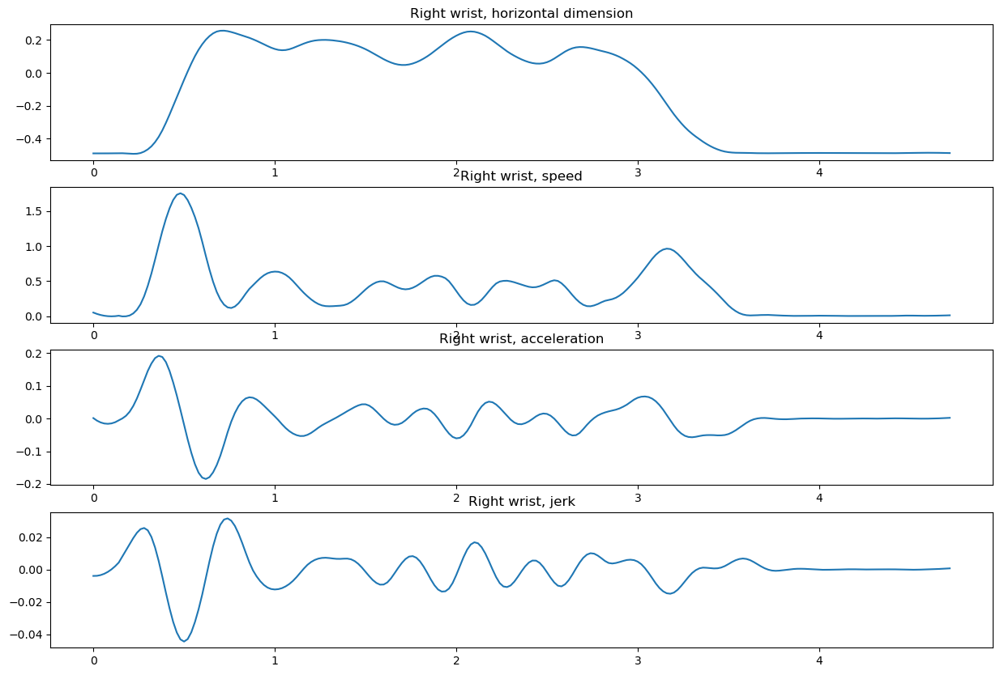

In [37]:
def process_derivs(df, sr):

    # Get speed
    cols = [c for c in df.columns if c.endswith(("_x", "_y"))]
    speedcols = [col.replace('_y', '').replace('_x', '').replace('_z', '') for col in cols]
    speedcols = list(set(speedcols))  # keep only unique values

    # Get rid of all columns with visibility
    speedcols = [col for col in speedcols if 'visibility' not in col]

    speed_dict = {}

    for col in speedcols:
        try:
            x = df[col + '_x'].to_numpy()
            y = df[col + '_y'].to_numpy()

            speed = np.insert(np.sqrt(np.diff(x)**2 + np.diff(y)**2), 0, 0)
            speed = np.abs(speed)
            speed = scipy.signal.savgol_filter(speed, 15, 2)
            speed = speed * sr  # convert to units per second

            speed_dict[col + '_speed'] = speed
        
        except KeyError:
            print(f"Skipping {col}: missing data")
            continue

    # Add all new speed columns at once
    speed_df = pd.DataFrame(speed_dict)
    df = pd.concat([df.reset_index(drop=True), speed_df], axis=1)

    # Get acceleration
    speedcols = [c for c in df.columns if c.endswith(("_speed"))]
    new_accel_cols = {}

    for col in speedcols:
        newcolname = col.replace('speed', 'acc')
        accel = np.insert(np.diff(df[col]), 0, 0)
        accel = scipy.signal.savgol_filter(accel, 15, 2)
        new_accel_cols[newcolname] = accel

    # Efficiently add all acceleration columns at once
    df = pd.concat([df, pd.DataFrame(new_accel_cols, index=df.index)], axis=1)

    # Get jerk
    accelcols = [c for c in df.columns if c.endswith(("_acc"))]
    new_jerk_cols = {}

    for col in accelcols:
        newcolname = col.replace('acc', 'jerk')
        jerk = np.insert(np.diff(df[col]), 0, 0)
        jerk = scipy.signal.savgol_filter(jerk, 15, 2)
        new_jerk_cols[newcolname] = jerk

    # Efficiently add all jerk columns at once
    df = pd.concat([df, pd.DataFrame(new_jerk_cols, index=df.index)], axis=1)

    return df


# Calculate sr of df_norm
sr = round(len(sample_norm) / (sample_norm['time_s'].iloc[-1] - sample_norm['time_s'].iloc[0]), 0)
#print(sr)
sample_der = process_derivs(sample_norm, sr=30.0)

# plot RIGHT_WRIST_y, speed, accel and jerk in grid of 4 subplots
plt.figure(figsize=(15, 10))
plt.subplot(4, 1, 1)
plt.plot(sample_der['time_s'], sample_der['right_wrist_y'])
plt.title('Right wrist, horizontal dimension')
plt.subplot(4, 1, 2)
plt.plot(sample_der['time_s'], sample_der['right_wrist_speed'])
plt.title('Right wrist, speed')
plt.subplot(4,1,3)
plt.plot(sample_der['time_s'], sample_der['right_wrist_acc'])
plt.title('Right wrist, acceleration')
plt.subplot(4,1,4)
plt.plot(sample_der['time_s'], sample_der['right_wrist_jerk'])
plt.title('Right wrist, jerk')    
plt.show()
    

## Individualize keypoints

# TODO:

- hand center on palm
- normalize by palm size
- individualize
- calculate distances